# hieuchinh — GPU, TEST lịch sử và HOLDOUT fake mới 14 ngày
Bật GPU → **Restart kernel → Run All**. Giữ feature và 6 cấu hình chính; chỉ fit TRAIN, audit dùng lại MODELS và không fit thêm.

HOLDOUT mới: **11/09/2026 00:00 → 25/09/2026 00:00 (không gồm mốc cuối)** theo giờ Việt Nam. Dùng lại logic fake data cũ với stream ngẫu nhiên mới, giữ nguyên demand lịch sử và cutoff TEST **15/08/2026 09:40**. TEST/HOLDOUT tách riêng, purge target H10/H30/H60 vượt ranh giới; holdout không dùng chọn model, cây hay hiệu chỉnh.

Đã bỏ output cũ để tránh nhầm kết quả holdout hồi cứu với holdout mới. Sau Run All, lưu notebook kèm output và xuất `demand_trend_overfit_results.zip`. Đã chạy kiểm tra sinh dữ liệu, feature và split: toàn bộ 5.404.530 dòng lịch sử cùng các dòng TRAIN/VAL khớp bản gốc, input holdout hợp lệ và split chính/audit đồng nhất. Chưa chạy lại 6 model GPU; chưa có metric holdout mới.

# Tuần 4 — Thống kê dự đoán gốc tại các hex có demand cao
**Restart kernel → Run All.** Chỉ huấn luyện 6 model trên TRAIN, dự đoán toàn TEST rồi thống kê riêng các dòng **actual >30** theo từng hex, mode và horizon. Không cộng/trừ bias, không học bảng bù, không chọn model theo TEST.

Giữ nguyên bộ sinh dữ liệu, feature, cutoff có purge và 6 cấu hình model từ notebook đã gửi. Prediction gốc vẫn theo quy tắc cũ: clip không âm rồi làm tròn. Đây là dữ liệu **giả lập**, kết quả chỉ chứng minh trong phạm vi bộ dữ liệu này.

Quyết định hiện tại: giữ dự đoán gốc, chưa áp dụng hiệu chỉnh. Thống kê phục vụ giải thích quyết định; không mặc định mọi sai số đều nhỏ hoặc hiệu chỉnh chắc chắn vô ích. Không chạy thêm thử nghiệm bão hòa.

Sau khi chạy: lưu notebook **kèm output** và gửi lại notebook cùng `tuan4_ketqua_bao_cao.zip` (đường dẫn được in cuối notebook). Chưa cần gửi model hoặc toàn bộ dữ liệu dự đoán.


In [2]:
import importlib.util
import subprocess
import sys

packages = {
    "IPython": "ipython",
    "numpy": "numpy", "pandas": "pandas", "scipy": "scipy",
    "h3": "h3>=4,<5", "holidays": "holidays", "pyarrow": "pyarrow",
    "lightgbm": "lightgbm", "matplotlib": "matplotlib", "joblib": "joblib",
}
missing = [package for name, package in packages.items()
           if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("Thư viện sẵn sàng.")


Thư viện sẵn sàng.


In [3]:
# Chạy cell này trước mọi cell train LightGBM, kể cả khi chỉ chạy mục 13.
import numpy as np
import lightgbm as lgb
from lightgbm import LGBMRegressor as _GPU_LGBMRegressor

LGB_GPU_CONFIG = {
    'device_type': 'gpu',   # OpenCL. 'cuda' cần bản LightGBM build riêng USE_CUDA=ON.
    'gpu_platform_id': -1, # Tự chọn; đổi theo thiết bị OpenCL nếu máy có nhiều platform.
    'gpu_device_id': -1,
    'gpu_use_dp': False,
}
LGB_GPU_READY = False

def make_lgbm_gpu(*args, **kwargs):
    if not LGB_GPU_READY:
        raise RuntimeError('Chạy cell cấu hình và kiểm tra LightGBM GPU trước khi train.')
    params = dict(kwargs)
    # Cấu hình chung luôn thắng params kế thừa từ model CPU hoặc bản chạy trước.
    for name in ('device','device_type','gpu_platform_id','gpu_device_id','gpu_use_dp','num_gpu'):
        params.pop(name, None)
    params.update(LGB_GPU_CONFIG)
    return _GPU_LGBMRegressor(*args, **params)

print('LightGBM:', lgb.__version__, '| cấu hình:', LGB_GPU_CONFIG)
_rng = np.random.default_rng(20261012)
_gpu_x = _rng.normal(size=(2048,8)).astype(np.float32)
_gpu_y = _rng.poisson(np.exp(np.clip(_gpu_x[:,0]*.2+1,-2,3))).astype(np.float32)
try:
    _gpu_probe = _GPU_LGBMRegressor(n_estimators=3,num_leaves=7,min_child_samples=10,
        objective='poisson',verbosity=1,n_jobs=2,**LGB_GPU_CONFIG)
    _gpu_probe.fit(_gpu_x,_gpu_y)
    if _gpu_probe.booster_.params.get('device_type') != 'gpu':
        raise RuntimeError('Model kiểm tra không xác nhận device_type=gpu.')
    LGB_GPU_READY = True
    print('GPU preflight PASS. Đọc dòng Using GPU Device trong log để biết thiết bị.')
except Exception as exc:
    raise RuntimeError(
        'LightGBM chưa sử dụng được GPU; dừng trước khi train dữ liệu lớn. '
        'Trên Kaggle hãy bật Settings > Accelerator > GPU, khởi động lại kernel và chạy lại cell này. '
        'Nếu báo No OpenCL device found, kiểm tra driver/OpenCL; nếu báo GPU Tree Learner was not enabled, '
        'cài bản LightGBM hỗ trợ GPU rồi restart kernel. Không tự chuyển về CPU. '
        f'Lỗi gốc: {exc}'
    ) from exc
finally:
    del _gpu_x, _gpu_y, _rng


LightGBM: 4.6.0 | cấu hình: {'device_type': 'gpu', 'gpu_platform_id': -1, 'gpu_device_id': -1, 'gpu_use_dp': False}
[LightGBM] [Info] This is the GPU trainer!!
[LightGBM] [Info] Total Bins 2040
[LightGBM] [Info] Number of data points in the train set: 2048, number of used features: 8
[LightGBM] [Info] Using GPU Device: Tesla T4, Vendor: NVIDIA Corporation
[LightGBM] [Info] Compiling OpenCL Kernel with 256 bins...


1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.


[LightGBM] [Info] GPU programs have been built
[LightGBM] [Info] Size of histogram bin entry: 8
[LightGBM] [Info] 8 dense feature groups (0.02 MB) transferred to GPU in 0.002146 secs. 0 sparse feature groups
[LightGBM] [Info] Start training from score 1.002683
GPU preflight PASS. Đọc dòng Using GPU Device trong log để biết thiết bị.


In [4]:
import gc
import json
import warnings
from pathlib import Path
from time import perf_counter

import h3
import holidays
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from lightgbm import LGBMRegressor, early_stopping
from IPython.display import display

SEED = 20260916
LOCAL_TIMEZONE = "Asia/Ho_Chi_Minh"
MODES = ("Car", "Motorcycle")
HORIZONS = (10, 30, 60)
CASES = [(mode, h) for mode in MODES for h in HORIZONS]
VALIDATION_DAYS = 30
TEST_START = pd.Timestamp("2026-08-15 09:40:00", tz=LOCAL_TIMEZONE)
VAL_START = TEST_START - pd.Timedelta(days=VALIDATION_DAYS)
VAL_MIDPOINT = VAL_START + (TEST_START - VAL_START) / 2

N_JOBS = -1
MAX_TREES = 800
EARLY_STOPPING_ROUNDS = 50
LEAF_CANDIDATES = (31, 63, 130)
# Cùng thứ tự thử với source: H10 bắt đầu 130; H30/H60 bắt đầu 63.
LEAF_TRIAL_ORDER = {10: (130, 31, 63), 30: (63, 31, 130), 60: (63, 31, 130)}
FRESH_BUCKET_IS_CLOSED_AT_T = True
FEATURE_POLICY = {
    (mode, h): "fresh_10_20" if h == 10 else "fresh_plus_neighbor"
    for mode, h in CASES
}
EXPECTED_FEATURE_COUNT = {10: 25, 30: 33, 60: 33}

output_root = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()
RUN_DIR = output_root / "tuan4_khong_hieu_chinh"
RUN_DIR.mkdir(parents=True, exist_ok=True)
print("TRAIN <", VAL_START, "| VAL <", TEST_START, "| TEST >=", TEST_START)
print("Feature đã khóa:", FEATURE_POLICY)
print("Đúng 6 lần fit TRAIN; tham số khóa, không grid search/refit.")

SOURCE_GENERATOR_SHA256 = 'a85690337e5b847530f7eed7287a2f69cdc6fdc049e6ce7f0925e5aa1f19bc3d'
PREDICTION_DIR = RUN_DIR / "predictions"
PREDICTION_DIR.mkdir(exist_ok=True)

# Ranh giới dữ liệu độc lập với cutoff TRAIN/VAL/TEST đã khóa.
LEGACY_DATA_START = pd.Timestamp("2026-05-01 00:00:00", tz=LOCAL_TIMEZONE)
LEGACY_DATA_END = pd.Timestamp("2026-09-11 00:00:00", tz=LOCAL_TIMEZONE)
HOLDOUT_DAYS = 14
HOLDOUT_START = LEGACY_DATA_END
HOLDOUT_END = HOLDOUT_START + pd.Timedelta(days=HOLDOUT_DAYS)
HOLDOUT_RNG_OFFSET = 1_000_000
LEGACY_GENERATOR_INPUT_SHA256 = 'a85690337e5b847530f7eed7287a2f69cdc6fdc049e6ce7f0925e5aa1f19bc3d'
assert HOLDOUT_END - HOLDOUT_START == pd.Timedelta(days=14)


TRAIN < 2026-07-16 09:40:00+07:00 | VAL < 2026-08-15 09:40:00+07:00 | TEST >= 2026-08-15 09:40:00+07:00
Feature đã khóa: {('Car', 10): 'fresh_10_20', ('Car', 30): 'fresh_plus_neighbor', ('Car', 60): 'fresh_plus_neighbor', ('Motorcycle', 10): 'fresh_10_20', ('Motorcycle', 30): 'fresh_plus_neighbor', ('Motorcycle', 60): 'fresh_plus_neighbor'}
Đúng 6 lần fit TRAIN; tham số khóa, không grid search/refit.


## 1. Phạm vi và cách đọc
- Demand cao = actual >30 tại từng thời điểm; **không phải demand trung bình của hex >30**. Ngưỡng giữ nguyên cho H10/H30/H60, nhưng target có độ dài khác nhau nên không xem ba tập là tương đương.
- Dự đoán toàn TEST trước, rồi thống kê mọi hex có ít nhất một dòng actual >30; không chọn theo lỗi cao/thấp. TEST chỉ dùng đánh giá, không fit hoặc tính tham số bù.
- `mean_over_pct`: trung bình 100×(prediction−actual)/actual **chỉ trên dòng dự đoán dư**.
- `mean_under_pct`: trung bình 100×(actual−prediction)/actual **chỉ trên dòng dự đoán thiếu**, biểu diễn bằng số dương. Không có dòng tương ứng → NaN, không phải 0%.
- `over_rate_pct`, `under_rate_pct`, `exact_rate_pct`: tỷ lệ trên tất cả dòng trong phạm vi đang xét.
- `WMAPE_pct` = 100×Σ|prediction−actual|/Σactual; `bias_pct` = 100×Σ(prediction−actual)/Σactual. Bias âm là thiếu. `mean_signed_pct` là trung bình % có dấu từng dòng, khác bias có trọng số demand.
- `within_15pct`: tỷ lệ dòng lệch không quá ±15%; **100−WMAPE không phải accuracy**.
- Cờ đủ mẫu: ≥20 dòng demand cao và ≥3 ngày; vẫn xuất cả hex ít mẫu, không tự loại kết quả xấu. Đây chỉ là mức tối thiểu mô tả, không bảo đảm ý nghĩa thống kê.
- Bảng tổng tính trực tiếp từ các dòng (không lấy trung bình WMAPE của hex). Bảng theo ngày và hex–giờ giúp phát hiện lệch cục bộ bị che bởi tổng hợp.
- Lọc theo actual cao có thể làm thay đổi phân phối residual; dùng bảng toàn TEST và toàn thời điểm của cùng hex để đối chiếu. Không dùng điều kiện actual >30 làm quy tắc serving vì chưa biết actual tương lai.


In [5]:
DEMAND_THRESHOLD = 30  # strict actual > 30, cùng ngưỡng cho H10/H30/H60
MIN_GROUP_ROWS = 20
MIN_GROUP_DAYS = 3
PREDICT_BATCH_SIZE = 100_000
LOCKED = {("Car",10):(63,633), ("Car",30):(130,763), ("Car",60):(130,799),
          ("Motorcycle",10):(63,762), ("Motorcycle",30):(63,795), ("Motorcycle",60):(130,792)}
assert DEMAND_THRESHOLD >= 0
REPORT_DIR = RUN_DIR / "reports"
MODEL_DIR = RUN_DIR / "models"
REPORT_DIR.mkdir(exist_ok=True); MODEL_DIR.mkdir(exist_ok=True)



## 2. Sinh fake data nguyên bộ sinh cũ

In [6]:
# Bộ sinh cũ được đóng thành hàm để dùng lại, không thay công thức demand.
# rng_offset=0 tái tạo lịch sử cũ; holdout dùng stream ngẫu nhiên mới.
def run_legacy_fake_generator(local_start, local_end, output_dir,
                              rng_offset=0, write_start=None, write_end=None):
    from pathlib import Path
    import gc

    import h3
    import holidays
    import numpy as np
    import pandas as pd
    import pyarrow as pa
    import pyarrow.parquet as pq

    from scipy.ndimage import gaussian_filter1d
    from scipy.optimize import least_squares
    try:
        from IPython.display import display
    except ImportError:
        def display(frame):
            print(frame.to_string(index=False))

    SEED = 20260916
    LOCAL_TIMEZONE = "Asia/Ho_Chi_Minh"

    LOCAL_START = pd.Timestamp(local_start)
    LOCAL_END = pd.Timestamp(local_end)
    assert LOCAL_START.tzinfo is not None and LOCAL_END.tzinfo is not None
    assert LOCAL_END > LOCAL_START

    # Lịch nghỉ lễ Việt Nam. observed=True bao gồm ngày nghỉ bù do thư viện cung cấp.
    VN_HOLIDAYS = holidays.country_holidays(
        "VN",
        years=range(LOCAL_START.year, LOCAL_END.year + 1),
        observed=True,
        language="vi",
    )


    VALID_MODES = ("Car", "Motorcycle")

    # Mỗi ngày có 144 bucket 10 phút
    SLOTS_PER_DAY = 24 * 6
    N_DAYS = (LOCAL_END - LOCAL_START).days
    N_TIME = N_DAYS * SLOTS_PER_DAY

    ALL_LOCAL_DATES = pd.date_range(
        start=LOCAL_START.normalize(),
        periods=N_DAYS,
        freq="D",
    )

    IS_HOLIDAY_BY_DAY = np.asarray(
        [int(ts.date() in VN_HOLIDAYS) for ts in ALL_LOCAL_DATES],
        dtype=np.int8,
    )

    HOLIDAY_NAME_BY_DAY = np.asarray(
        [VN_HOLIDAYS.get(ts.date(), "") for ts in ALL_LOCAL_DATES],
        dtype=object,
    )

    HOLIDAY_DATES_IN_RANGE = pd.DataFrame({
        "date": ALL_LOCAL_DATES.date,
        "is_holiday": IS_HOLIDAY_BY_DAY,
        "holiday_name": HOLIDAY_NAME_BY_DAY,
    })
    HOLIDAY_DATES_IN_RANGE = HOLIDAY_DATES_IN_RANGE[
        HOLIDAY_DATES_IN_RANGE["is_holiday"] == 1
    ].reset_index(drop=True)

    print("Holiday dates inside fake-data range:")
    display(HOLIDAY_DATES_IN_RANGE)

    HCM_CENTER = (10.7769, 106.7009)
    H3_RESOLUTION = 7
    H3_K_RING = 8

    # Preserve the notebook's existing 217 H3 IDs and spatial footprint. A radius
    # around the city center does not certify membership of the HCMC boundary;
    # replace COMMON_HEX with a verified operations H3 list if one is available.
    HCM_CENTER_HEX = h3.latlng_to_cell(
        *HCM_CENTER,
        H3_RESOLUTION,
    )

    COMMON_HEX = sorted(
        h3.grid_disk(HCM_CENTER_HEX, H3_K_RING)
    )

    N_HEX = len(COMMON_HEX)


    def km_to(point, lat, lng):
        """Local equirectangular distance (adequate for this ~40 km footprint)."""
        return np.hypot(
            (lat - point[0]) * 111.1,
            (lng - point[1]) * 109.2,
        )


    def make_hex_metadata():
        """Geographic priors: these area labels are synthetic, not actual POIs."""
        coords = np.asarray([h3.cell_to_latlng(h) for h in COMMON_HEX])
        lat, lng = coords[:, 0], coords[:, 1]
        anchor = {
            "central": (10.7769, 106.7009),
            "airport": (10.8188, 106.6519),
            "west": (10.7510, 106.6550),
            "south": (10.7295, 106.7219),
            "east": (10.8506, 106.7719),
        }
        distance = {key: km_to(value, lat, lng) for key, value in anchor.items()}
        near = {key: np.exp(-0.5 * (d / 3.8) ** 2) for key, d in distance.items()}
        outer = np.minimum.reduce([distance[key] for key in anchor]) > 6.2
        zone_score = np.column_stack([
            1.40 * near["central"],
            1.20 * near["airport"],
            near["west"],
            near["south"],
            near["east"],
        ])
        zone = np.array(["central", "airport", "west", "south", "east"], dtype=object)[
            zone_score.argmax(axis=1)
        ]
        zone[outer] = "outer"
        # A shared coarse H3 effect keeps neighboring hexes more similar.
        parent = [h3.cell_to_parent(h, 5) for h in COMMON_HEX]
        parent_code = pd.factorize(np.asarray(parent), sort=True)[0]
        rng = np.random.default_rng(SEED + 402)
        coarse = rng.normal(0, 0.18, size=parent_code.max() + 1)
        local = rng.normal(0, 0.075, size=N_HEX)
        spatial_log = (
            0.72 * near["central"]
            + 0.38 * near["airport"]
            + 0.26 * near["west"]
            + 0.24 * near["south"]
            + 0.22 * near["east"]
            - 0.018 * distance["central"]
            - 0.43 * outer
            + coarse[parent_code]
            + local
        )
        return pd.DataFrame({
            "hex_id_7": COMMON_HEX,
            "center_lat": lat,
            "center_lng": lng,
            "synthetic_zone": zone,
            "spatial_log_weight": spatial_log.astype(np.float32),
        })


    HEX_METADATA = make_hex_metadata()
    ZONE = HEX_METADATA["synthetic_zone"].to_numpy()
    SPATIAL_LOG_WEIGHT = HEX_METADATA["spatial_log_weight"].to_numpy()

    # Zero chỉ xuất hiện hiếm ở các active hex. Tỷ lệ nhỏ để không phá
    # n/mean/std/p50/p95/p99/max được hiệu chỉnh từ thống kê thực.
    ZERO_RATE_BY_MODE = {
        "Car": 0.003,         # khoảng 0.30% số bucket
        "Motorcycle": 0.002,  # khoảng 0.20% số bucket
    }
    ZERO_CANDIDATE_SHARE = 0.26

    CONTRACT = {
        "Car": {
            "n": 2_863_718,
            "mean": 9.75,
            "std": 17.37,
            "p50": 4,
            "p95": 40,
            "p99": 86,
            "max": 1_000,
            "bucket_rows": [
                615_688,
                1_525_941,
                618_033,
                104_056,
            ],
            "bucket_volume_pct": [
                0.022,
                0.227,
                0.454,
                0.298,
            ],
        },
        "Motorcycle": {
            "n": 2_540_812,
            "mean": 16.96,
            "std": 29.29,
            "p50": 6,
            "p95": 73,
            "p99": 144,
            "max": 914,
            "bucket_rows": [
                480_508,
                1_069_539,
                770_448,
                220_316,
            ],
            "bucket_volume_pct": [
                0.011,
                0.108,
                0.400,
                0.481,
            ],
        },
    }

    OUTPUT_ROOT = (
        Path("/kaggle/working")
        if Path("/kaggle/working").exists()
        else Path.cwd()
    )

    OUTPUT_DIR = Path(output_dir)
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    DEMAND_PATH = (
        OUTPUT_DIR
        / "xanhsm_hcm_smooth_10min_bucket_v9.parquet"
    )

    # ------------------------------------------------------------
    # HÀM TẠO PHÂN PHỐI DEMAND ĐÚNG CONTRACT
    # ------------------------------------------------------------
    def largest_remainder_counts(weights, total):
        weights = np.asarray(weights, dtype=float)
        weights = weights / weights.sum()

        expected = weights * total
        counts = np.floor(expected).astype(np.int64)

        remainder = total - counts.sum()

        if remainder:
            order = np.argsort(
                -(expected - counts),
                kind="stable",
            )
            counts[order[:remainder]] += 1

        return counts


    def bucket_counts_for_mode(mode):
        spec = CONTRACT[mode]

        counts = np.asarray(
            spec["bucket_rows"],
            dtype=np.int64,
        ).copy()

        # Motorcycle thiếu một dòng trong thống kê nguồn
        counts[-1] += spec["n"] - counts.sum()

        return counts


    def maxent_discrete(
        support,
        feature_functions,
        targets,
    ):
        support = np.asarray(support, dtype=float)

        features = np.column_stack([
            function(support)
            for function in feature_functions
        ])

        targets = np.asarray(targets, dtype=float)

        def probabilities(theta):
            logits = features @ theta
            logits -= logits.max()

            probability = np.exp(logits)
            return probability / probability.sum()

        result = least_squares(
            lambda theta:
            probabilities(theta) @ features - targets,
            np.zeros(features.shape[1]),
            xtol=1e-13,
            ftol=1e-13,
            gtol=1e-13,
            max_nfev=20_000,
        )

        probability = probabilities(result.x)

        error = np.max(
            np.abs(
                probability @ features - targets
            )
        )

        if error > 2e-7:
            raise RuntimeError(
                f"Calibration failed: {error}"
            )

        return probability


    def calibrated_segments(mode):
        spec = CONTRACT[mode]

        n = spec["n"]
        mean = float(spec["mean"])
        std = float(spec["std"])
        max_value = int(spec["max"])

        bucket_counts = bucket_counts_for_mode(mode)
        bucket_probability = bucket_counts / n

        exact_one_share = (
            bucket_counts[0] / (n * mean)
        )

        remaining_share = np.asarray(
            spec["bucket_volume_pct"][1:],
            dtype=float,
        )

        remaining_share *= (
            1.0 - exact_one_share
        ) / remaining_share.sum()

        volume_share = np.r_[
            exact_one_share,
            remaining_share,
        ]

        conditional_mean = (
            mean
            * volume_share
            / bucket_probability
        )

        delta = max(0.0002, 3.0 / n)

        supports = [
            np.asarray([1], dtype=np.int16)
        ]
        probabilities = [
            np.asarray([1.0])
        ]

        # Bucket 2–9
        q50 = int(spec["p50"])
        support = np.arange(2, 10)

        probability = maxent_discrete(
            support,
            [
                lambda x: x / 9.0,
                lambda x:
                (x <= q50 - 1).astype(float),
                lambda x:
                (x <= q50).astype(float),
            ],
            [
                conditional_mean[1] / 9.0,
                (
                    0.50
                    - delta
                    - bucket_probability[0]
                ) / bucket_probability[1],
                (
                    0.50
                    + delta
                    - bucket_probability[0]
                ) / bucket_probability[1],
            ],
        )

        supports.append(support.astype(np.int16))
        probabilities.append(probability)

        # Bucket 10–49
        support = np.arange(10, 50)

        functions = [
            lambda x: x / 49.0
        ]
        targets = [
            conditional_mean[2] / 49.0
        ]

        q95 = int(spec["p95"])

        if q95 <= 49:
            functions.extend([
                lambda x:
                (x <= q95 - 1).astype(float),
                lambda x:
                (x <= q95).astype(float),
            ])

            targets.extend([
                (
                    0.95
                    - delta
                    - bucket_probability[:2].sum()
                ) / bucket_probability[2],
                (
                    0.95
                    + delta
                    - bucket_probability[:2].sum()
                ) / bucket_probability[2],
            ])

        probability = maxent_discrete(
            support,
            functions,
            targets,
        )

        supports.append(support.astype(np.int16))
        probabilities.append(probability)

        # Bucket 50+
        population_second_moment = (
            std**2 * (n - 1) / n
            + mean**2
        )

        lower_second_moment = sum(
            bucket_probability[index]
            * float(
                probabilities[index]
                @ supports[index].astype(float) ** 2
            )
            for index in range(3)
        )

        tail_second_moment = (
            population_second_moment
            - lower_second_moment
        ) / bucket_probability[3]

        support = np.arange(
            50,
            max_value + 1,
        )

        functions = [
            lambda x: x / max_value,
            lambda x:
            (x / max_value) ** 2,
        ]

        targets = [
            conditional_mean[3] / max_value,
            tail_second_moment / max_value**2,
        ]

        for percentile, quantile_value in [
            (0.95, int(spec["p95"])),
            (0.99, int(spec["p99"])),
        ]:
            if quantile_value >= 50:
                functions.extend([
                    lambda x, q=quantile_value:
                    (x <= q - 1).astype(float),
                    lambda x, q=quantile_value:
                    (x <= q).astype(float),
                ])

                targets.extend([
                    (
                        percentile
                        - delta
                        - bucket_probability[:3].sum()
                    ) / bucket_probability[3],
                    (
                        percentile
                        + delta
                        - bucket_probability[:3].sum()
                    ) / bucket_probability[3],
                ])

        probability = maxent_discrete(
            support,
            functions,
            targets,
        )

        supports.append(support.astype(np.int16))
        probabilities.append(probability)

        return (
            bucket_counts,
            supports,
            probabilities,
        )


    def repair_integer_moments(values, mode):
        spec = CONTRACT[mode]

        max_value = int(spec["max"])
        q99 = int(spec["p99"])

        counts = np.bincount(
            values.astype(np.int64),
            minlength=max_value + 1,
        ).astype(np.int64)

        support = np.arange(
            max_value + 1,
            dtype=np.int64,
        )

        n = counts.sum()

        target_sum = int(
            np.rint(n * spec["mean"])
        )

        target_sumsq_float = (
            (n - 1) * spec["std"] ** 2
            + target_sum**2 / n
        )

        target_sumsq = int(
            np.rint(target_sumsq_float)
        )

        if (target_sumsq - target_sum) % 2:
            candidates = (
                target_sumsq - 1,
                target_sumsq + 1,
            )

            target_sumsq = min(
                candidates,
                key=lambda x:
                abs(x - target_sumsq_float),
            )

        current_sum = int(counts @ support)
        sum_deficit = target_sum - current_sum

        if sum_deficit > 0:
            for value in range(
                q99 + 1,
                max_value,
            ):
                if sum_deficit == 0:
                    break

                move = min(
                    sum_deficit,
                    int(counts[value]),
                )

                counts[value] -= move
                counts[value + 1] += move
                sum_deficit -= move

        elif sum_deficit < 0:
            remaining = -sum_deficit

            for value in range(
                max_value,
                q99 + 1,
                -1,
            ):
                if remaining == 0:
                    break

                movable = int(counts[value])

                if value == max_value:
                    movable = max(
                        0,
                        movable - 1,
                    )

                move = min(
                    remaining,
                    movable,
                )

                counts[value] -= move
                counts[value - 1] += move
                remaining -= move

            sum_deficit = -remaining

        if sum_deficit != 0:
            raise RuntimeError(
                f"Cannot repair mean for {mode}"
            )

        current_sumsq = int(
            counts @ (support * support)
        )

        square_deficit = (
            target_sumsq - current_sumsq
        )

        iterations = 0

        while square_deficit > 0:
            iterations += 1

            if iterations > 100_000:
                break

            max_gap = square_deficit // 2 - 1

            if max_gap < 1:
                break

            available_low = (
                np.flatnonzero(
                    counts[q99 + 2:max_value] > 0
                )
                + q99
                + 2
            )

            available_high = (
                np.flatnonzero(
                    counts[q99 + 1:max_value] > 0
                )
                + q99
                + 1
            )

            best = None

            for low in available_low:
                high_limit = min(
                    max_value - 1,
                    int(low) + max_gap,
                )

                candidates = available_high[
                    (available_high > low)
                    & (available_high <= high_limit)
                ]

                if len(candidates):
                    high = int(candidates[-1])
                    gap = high - int(low)

                    if best is None or gap > best[0]:
                        best = (
                            gap,
                            int(low),
                            high,
                        )

            if best is None:
                break

            gap, low, high = best
            delta_per_pair = 2 * gap + 2

            move = min(
                int(counts[low]),
                int(counts[high]),
                square_deficit // delta_per_pair,
            )

            if move <= 0:
                break

            counts[low] -= move
            counts[low - 1] += move
            counts[high] -= move
            counts[high + 1] += move

            square_deficit -= (
                move * delta_per_pair
            )

        while square_deficit < 0:
            iterations += 1

            if iterations > 100_000:
                break

            remaining = -square_deficit
            max_gap = remaining // 2 + 1

            if max_gap < 2:
                break

            available_low = (
                np.flatnonzero(
                    counts[q99 + 1:max_value] > 0
                )
                + q99
                + 1
            )

            high_capacity = counts.copy()
            high_capacity[max_value] = max(
                0,
                high_capacity[max_value] - 1,
            )

            available_high = (
                np.flatnonzero(
                    high_capacity[
                        q99 + 2:max_value + 1
                    ] > 0
                )
                + q99
                + 2
            )

            best = None

            for low in available_low:
                high_limit = min(
                    max_value,
                    int(low) + max_gap,
                )

                candidates = available_high[
                    (available_high >= low + 2)
                    & (available_high <= high_limit)
                ]

                if len(candidates):
                    high = int(candidates[-1])
                    gap = high - int(low)

                    if best is None or gap > best[0]:
                        best = (
                            gap,
                            int(low),
                            high,
                        )

            if best is None:
                break

            gap, low, high = best
            delta_per_pair = 2 * gap - 2

            movable_high = int(counts[high])

            if high == max_value:
                movable_high = max(
                    0,
                    movable_high - 1,
                )

            move = min(
                int(counts[low]),
                movable_high,
                remaining // delta_per_pair,
            )

            if move <= 0:
                break

            counts[low] -= move
            counts[low + 1] += move
            counts[high] -= move
            counts[high - 1] += move

            square_deficit += (
                move * delta_per_pair
            )

        actual_sum = int(counts @ support)
        actual_sumsq = int(
            counts @ (support * support)
        )

        if (
            actual_sum != target_sum
            or actual_sumsq != target_sumsq
        ):
            raise RuntimeError(
                f"Moment repair failed for {mode}"
            )

        return np.repeat(
            support,
            counts,
        ).astype(np.int16)


    def create_calibrated_marks(mode, rng):
        spec = CONTRACT[mode]
        n = spec["n"]

        (
            bucket_counts,
            supports,
            probabilities,
        ) = calibrated_segments(mode)

        pieces = []

        for count, support, probability in zip(
            bucket_counts,
            supports,
            probabilities,
        ):
            value_counts = largest_remainder_counts(
                probability,
                int(count),
            )

            pieces.append(
                np.repeat(
                    support,
                    value_counts,
                ).astype(np.int16)
            )

        values = np.concatenate(pieces)

        max_value = int(spec["max"])

        if not np.any(values == max_value):
            tail_start = bucket_counts[:3].sum()
            tail = values[tail_start:]

            replacement_value = int(
                np.argmax(
                    np.bincount(
                        tail.astype(np.int64)
                    )
                )
            )

            candidate = np.flatnonzero(
                tail == replacement_value
            )[0]

            tail[candidate] = max_value
            values[tail_start:] = tail

        # Đổi một phần rất nhỏ demand=1 thành demand=0. Sau đó repair lại
        # tổng và tổng bình phương nên mean/std mục tiêu vẫn được giữ.
        zero_count = int(np.rint(n * ZERO_RATE_BY_MODE[mode]))
        one_positions = np.flatnonzero(values == 1)

        if zero_count > len(one_positions):
            raise RuntimeError(
                f"Not enough demand=1 rows to create zeros for {mode}"
            )

        zero_mark_positions = rng.choice(
            one_positions,
            size=zero_count,
            replace=False,
        )
        values[zero_mark_positions] = 0

        values = repair_integer_moments(
            values,
            mode,
        )

        rng.shuffle(values)

        assert len(values) == n
        return values


    def assign_marks_with_sparse_zeros(
        marks,
        propensity,
        hex_index,
        time_index,
        rng,
    ):
        """Gán marks theo propensity và không để zero liên tiếp/cùng hex."""
        n_rows = len(marks)
        zero_count = int(np.count_nonzero(marks == 0))

        if zero_count == 0:
            order = np.argsort(propensity, kind="stable")
            demand = np.empty(n_rows, dtype=np.int16)
            demand[order] = np.sort(marks)
            return demand

        # Zero is sparse globally, mostly overnight in low-activity cells;
        # choose within the bottom propensity band so zero never lands at a peak.
        candidate_count = min(
            n_rows,
            max(
                zero_count * 20,
                int(np.ceil(n_rows * ZERO_CANDIDATE_SHARE)),
            ),
        )

        low_candidates = np.argpartition(
            propensity,
            candidate_count - 1,
        )[:candidate_count]
        slot = time_index[low_candidates] % SLOTS_PER_DAY
        overnight = (slot < 30) | (slot >= 138)
        night_candidates = low_candidates[overnight]
        other_candidates = low_candidates[~overnight]
        rng.shuffle(night_candidates)
        rng.shuffle(other_candidates)

        selected = []
        selected_keys = set()

        night_target = int(np.rint(0.85 * zero_count))
        for candidates, target in (
            (night_candidates, night_target),
            (other_candidates, zero_count),
            (night_candidates, zero_count),
        ):
            if len(selected) >= zero_count:
                break
            for row_index in candidates:
                hex_value = int(hex_index[row_index])
                time_value = int(time_index[row_index])
                key = hex_value * N_TIME + time_value
                if key in selected_keys or key - 1 in selected_keys or key + 1 in selected_keys:
                    continue
                selected.append(int(row_index))
                selected_keys.add(key)
                if len(selected) >= target:
                    break

        if len(selected) != zero_count:
            raise RuntimeError(
                f"Cannot place sparse zeros: selected={len(selected)}, "
                f"target={zero_count}, night_candidates={len(night_candidates)}, "
                f"other_candidates={len(other_candidates)}"
            )

        zero_positions = np.asarray(selected, dtype=np.int64)
        zero_mask = np.zeros(n_rows, dtype=bool)
        zero_mask[zero_positions] = True

        demand = np.empty(n_rows, dtype=np.int16)
        demand[zero_positions] = 0

        positive_positions = np.flatnonzero(~zero_mask)
        positive_order = positive_positions[
            np.argsort(
                propensity[positive_positions],
                kind="stable",
            )
        ]
        demand[positive_order] = np.sort(marks[marks > 0])

        return demand


    def validate_generated_demand(
        demand,
        mode,
        hex_index,
        time_index,
    ):
        """Fail-fast nếu zero hoặc thống kê sinh ra lệch contract thực."""
        spec = CONTRACT[mode]
        expected_zero_count = int(
            np.rint(spec["n"] * ZERO_RATE_BY_MODE[mode])
        )

        actual_quantiles = np.quantile(
            demand,
            [0.50, 0.95, 0.99],
        )

        if len(demand) != spec["n"]:
            raise AssertionError(f"Invalid n for {mode}")
        if not np.isclose(demand.mean(), spec["mean"], atol=5e-7):
            raise AssertionError(f"Invalid mean for {mode}")
        if not np.isclose(demand.std(ddof=1), spec["std"], atol=5e-7):
            raise AssertionError(f"Invalid std for {mode}")
        if not np.array_equal(
            actual_quantiles,
            [spec["p50"], spec["p95"], spec["p99"]],
        ):
            raise AssertionError(f"Invalid quantiles for {mode}")
        if int(demand.max()) != spec["max"]:
            raise AssertionError(f"Invalid max for {mode}")
        if int(np.count_nonzero(demand == 0)) != expected_zero_count:
            raise AssertionError(f"Invalid zero count for {mode}")

        slot = time_index % SLOTS_PER_DAY
        zero = demand == 0
        overnight = (slot < 30) | (slot >= 138)
        if zero.any() and np.mean(overnight[zero]) < 0.80:
            raise AssertionError(f"Too few overnight zero rows for {mode}")
        if np.mean(demand[(slot >= 42) & (slot < 54)]) <= 2 * np.mean(
            demand[(slot >= 6) & (slot < 24)]
        ):
            raise AssertionError(f"Morning is not above overnight for {mode}")
        if np.mean(demand[(slot >= 102) & (slot < 120)]) <= 2 * np.mean(
            demand[(slot >= 6) & (slot < 24)]
        ):
            raise AssertionError(f"Evening is not above overnight for {mode}")
        valid_neighbors = (np.diff(hex_index) == 0) & (np.diff(time_index) == 1)
        if valid_neighbors.mean() < 0.995:
            raise AssertionError(f"Too many holes in observed cell histories for {mode}")

        actual_bucket_rows = np.asarray([
            np.count_nonzero((demand >= 0) & (demand <= 1)),
            np.count_nonzero((demand >= 2) & (demand <= 9)),
            np.count_nonzero((demand >= 10) & (demand <= 49)),
            np.count_nonzero(demand >= 50),
        ])

        if not np.array_equal(
            actual_bucket_rows,
            bucket_counts_for_mode(mode),
        ):
            raise AssertionError(f"Invalid bucket rows for {mode}")

        zero_positions = np.flatnonzero(demand == 0)
        zero_keys = np.sort(
            hex_index[zero_positions].astype(np.int64) * N_TIME
            + time_index[zero_positions].astype(np.int64)
        )

        if len(zero_keys) > 1:
            same_hex = (
                zero_keys[1:] // N_TIME
                == zero_keys[:-1] // N_TIME
            )
            consecutive = same_hex & (np.diff(zero_keys) == 1)

            if np.any(consecutive):
                raise AssertionError(
                    f"Consecutive zero buckets detected for {mode}"
                )

    # ------------------------------------------------------------
    # CHỌN CHÍNH XÁC N VỊ TRÍ HEX × BUCKET
    # Mỗi hex có tối đa một đoạn ngày không quan sát, bù nhau giữa các hex.
    # ------------------------------------------------------------
    def select_bucket_positions(n_rows, rng, mode):
        full_days, remainder = divmod(
            n_rows,
            SLOTS_PER_DAY,
        )
        min_days = 42
        if not N_HEX * min_days <= full_days <= N_HEX * N_DAYS:
            raise ValueError("n_rows cannot support the requested continuous history")

        # This controls observation coverage only; it does not change the
        # frequency of zero within the rows that are actually observed.
        mode_weight = (1.0 if mode == "Car" else 0.91)
        weights = np.exp(mode_weight * (SPATIAL_LOG_WEIGHT - SPATIAL_LOG_WEIGHT.mean()))
        days = np.full(N_HEX, min_days, dtype=np.int32)
        remaining = full_days - int(days.sum())
        while remaining:
            eligible = days < N_DAYS
            proportions = weights[eligible] / weights[eligible].sum()
            extra = np.minimum(N_DAYS - days[eligible], np.floor(remaining * proportions).astype(int))
            if not extra.any():
                indices = np.flatnonzero(eligible)
                priority = np.argsort(-proportions, kind="stable")
                extra[priority[:remaining]] = 1
            days[eligible] += extra
            remaining = full_days - int(days.sum())

        # Spread the missing interval evenly around the circular date axis. This
        # prevents a large artificial loss of hex coverage at the edges of the
        # four-month window; each hex has at most one absence interval.
        permuted_rank = rng.permutation(N_HEX)
        missing_starts = (
            (permuted_rank * N_DAYS // N_HEX)
            + int(rng.integers(0, N_DAYS))
        ) % N_DAYS
        hex_parts = []
        time_parts = []
        observed_days_by_hex = []
        for cell_idx, n_days in enumerate(days):
            missing_length = N_DAYS - int(n_days)
            observed_days = np.flatnonzero(
                ((np.arange(N_DAYS) - missing_starts[cell_idx]) % N_DAYS)
                >= missing_length
            )
            observed_days_by_hex.append(observed_days)
            size = len(observed_days) * SLOTS_PER_DAY
            hex_parts.append(np.full(size, cell_idx, dtype=np.int16))
            time_parts.append((
                np.repeat(observed_days, SLOTS_PER_DAY) * SLOTS_PER_DAY
                + np.tile(np.arange(SLOTS_PER_DAY), len(observed_days))
            ).astype(np.int32))

        if remainder:
            cell_idx = int(rng.choice(np.flatnonzero(days < N_DAYS)))
            obs = np.zeros(N_DAYS, dtype=bool)
            obs[observed_days_by_hex[cell_idx]] = True
            right_edge = np.flatnonzero(obs[:-1] & ~obs[1:])
            if len(right_edge):
                first = (int(right_edge[0]) + 1) * SLOTS_PER_DAY
            else:
                left_edge = np.flatnonzero(~obs[:-1] & obs[1:])
                first = (int(left_edge[0]) + 1) * SLOTS_PER_DAY - remainder
            hex_parts.append(np.full(remainder, cell_idx, dtype=np.int16))
            time_parts.append(np.arange(first, first + remainder, dtype=np.int32))

        hex_index = np.concatenate(hex_parts)
        time_index = np.concatenate(time_parts)
        order = np.lexsort((time_index, hex_index))
        return hex_index[order], time_index[order]


    # ------------------------------------------------------------
    # QUY LUẬT THỜI GIAN
    # ------------------------------------------------------------
    def time_profile(mode, time_index, hex_index):
        day_index = time_index // SLOTS_PER_DAY
        slot = time_index % SLOTS_PER_DAY

        hour = slot / 6.0

        day_of_week = (
            LOCAL_START.dayofweek + day_index
        ) % 7

        working_day = day_of_week < 5

        morning = np.exp(
            -0.5 * ((hour - 8.0) / 1.4) ** 2
        )
        lunch = np.exp(
            -0.5 * ((hour - 12.0) / 2.1) ** 2
        )
        evening = np.exp(
            -0.5 * ((hour - 18.0) / 1.6) ** 2
        )
        night = np.exp(
            -0.5 * ((hour - 21.5) / 2.0) ** 2
        )

        if mode == "Car":
            weekday = (
                0.42
                + 1.20 * morning
                + 0.35 * lunch
                + 1.55 * evening
                + 0.18 * night
            )

            weekend = (
                0.52
                + 0.45 * morning
                + 0.85 * lunch
                + 1.00 * evening
                + 0.30 * night
            )
        else:
            weekday = (
                0.45
                + 1.35 * morning
                + 0.48 * lunch
                + 1.70 * evening
                + 0.23 * night
            )

            weekend = (
                0.55
                + 0.55 * morning
                + 0.95 * lunch
                + 1.15 * evening
                + 0.38 * night
            )

        baseline = np.where(
            working_day,
            weekday,
            weekend,
        )
        # Pickup origins can differ across spatial zones; these are heuristics.
        zone = ZONE[hex_index]
        early = np.exp(-0.5 * ((hour - 7.7) / 1.35) ** 2)
        late = np.exp(-0.5 * ((hour - 18.2) / 1.5) ** 2)
        after_dark = np.exp(-0.5 * ((hour - 22.5) / 1.9) ** 2)
        # Airport cells retain activity overnight; outer cells are very quiet.
        baseline += (zone == "airport") * (
            0.22 + 0.20 * early + 0.18 * after_dark
        )
        baseline += (zone == "central") * (
            0.11 + 0.15 * late + 0.27 * after_dark * (~working_day)
        )
        baseline += ((zone == "south") | (zone == "west")) * (
            0.16 * early * working_day + 0.08 * late
        )
        baseline += (zone == "east") * (0.13 * early * working_day)
        overnight = (hour < 5.0)
        night_factor = np.where(
            zone == "outer", 0.27,
            np.where(zone == "airport", 0.78,
                     np.where(zone == "central", 0.54, 0.38))
        )
        # Demand 00:00–05:00 is often 0/1/2 in lower-activity cells.
        return baseline * np.where(overnight, night_factor, 1.0)


    # ------------------------------------------------------------
    # SINH FILE PARQUET
    # ------------------------------------------------------------
    OUTPUT_SCHEMA = pa.schema([
        pa.field(
            "period_datetime_utc",
            pa.timestamp("us", tz="UTC"),
        ),
        pa.field("hex_id_7", pa.string()),
        pa.field("travel_mode", pa.string()),
        pa.field("total_demand", pa.int16()),
        pa.field("is_holiday", pa.int8()),
    ])

    if DEMAND_PATH.exists():
        DEMAND_PATH.unlink()

    writer = pq.ParquetWriter(
        DEMAND_PATH,
        OUTPUT_SCHEMA,
        compression="zstd",
        use_dictionary=[
            "hex_id_7",
            "travel_mode",
        ],
    )

    shared_rng = np.random.default_rng(SEED + rng_offset)

    hex_to_index = {hex_id: i for i, hex_id in enumerate(COMMON_HEX)}
    hex_coverage = []

    # Trạng thái thành phố thay đổi chậm theo ngày
    city_state = shared_rng.normal(
        0,
        1,
        size=N_DAYS,
    )

    city_state = gaussian_filter1d(
        city_state,
        sigma=2.0,
    )

    city_state = (
        city_state - city_state.mean()
    ) / (city_state.std() + 1e-8)

    START_UTC_US = int(
        LOCAL_START.tz_convert("UTC").value
        // 1_000
    )

    TEN_MINUTES_US = (
        10 * 60 * 1_000_000
    )

    hex_array = np.asarray(
        COMMON_HEX,
        dtype=object,
    )

    generation_summary = []

    try:
        for mode_index, mode in enumerate(
            VALID_MODES
        ):
            rng = np.random.default_rng(
                SEED + rng_offset + 10_000 * (mode_index + 1)
            )

            n_rows = CONTRACT[mode]["n"]

            hex_index, time_index = (
                select_bucket_positions(
                    n_rows,
                    rng,
                    mode,
                )
            )

            # Demand marks giữ đúng thống kê tổng
            marks = create_calibrated_marks(
                mode,
                rng,
            )

            # Trạng thái demand mịn theo từng hex
            smooth_state = rng.normal(
                0,
                1,
                size=(N_HEX, N_TIME),
            ).astype(np.float32)

            smooth_state = gaussian_filter1d(
                smooth_state,
                sigma=8.0,  # khoảng 80 phút
                axis=1,
                mode="nearest",
            )

            smooth_state = (
                smooth_state
                - smooth_state.mean(
                    axis=1,
                    keepdims=True,
                )
            ) / (
                smooth_state.std(
                    axis=1,
                    keepdims=True,
                )
                + 1e-6
            )

            day_index = (
                time_index // SLOTS_PER_DAY
            )

            is_holiday = IS_HOLIDAY_BY_DAY[day_index].astype(np.int8)

            # --------------------------------------------------------
            # HOLIDAY EFFECT — tăng NHẸ, không tạo spike quá giả
            # --------------------------------------------------------
            # Chỉ thay đổi propensity nên bộ marks / phân phối tổng vẫn giữ contract.
            # Holiday effect tập trung từ trưa đến tối vì nhu cầu đi lại thường rõ hơn
            # ở các khung giờ này; sáng sớm chỉ được boost rất nhẹ.
            slot = time_index % SLOTS_PER_DAY
            hour = slot / 6.0

            holiday_time_profile = (
                0.30
                + 0.25
                * np.exp(
                    -0.5 * ((hour - 12.0) / 2.7) ** 2
                )
                + 0.45
                * np.exp(
                    -0.5 * ((hour - 18.5) / 3.0) ** 2
                )
            )

            # Có thể tăng/giảm 2 số này để holiday nổi bật hơn/ít hơn.
            # Giá trị hiện tại chỉ làm holiday nhô lên vừa phải.
            HOLIDAY_STRENGTH = {
                "Car": 0.06,
                "Motorcycle": 0.06,
            }[mode]

            holiday_propensity_boost = (
                is_holiday
                * HOLIDAY_STRENGTH
                * holiday_time_profile
            )

            mode_spatial_effect = (
                SPATIAL_LOG_WEIGHT
                + rng.normal(0, 0.09, size=N_HEX)
            )

            # Localized, time-limited events introduce rare peaks without
            # altering the exact overall demand histogram / maximum.
            event_state = np.zeros((N_HEX, N_TIME), dtype=np.float32)
            for _ in range(75):
                focus = int(rng.integers(0, N_HEX))
                start = int(rng.integers(0, N_TIME - 14))
                neighbors = [
                    hex_to_index[h]
                    for h in h3.grid_disk(COMMON_HEX[focus], 1)
                    if h in hex_to_index
                ]
                length = int(rng.integers(5, 15))
                shape = np.sin(np.linspace(0, np.pi, length, dtype=np.float32))
                event_state[np.ix_(neighbors, np.arange(start, start + length))] += (
                    rng.uniform(0.6, 1.35) * shape[None, :]
                )

            profile = time_profile(
                mode,
                time_index,
                hex_index,
            )

            # Noise nhỏ (0.08 như bản đầu) vì dữ liệu bucket thực đã mịn
            propensity = (
                1.15
                * mode_spatial_effect[hex_index]
                + 1.15
                * np.log(profile + 1e-6)
                + 0.09
                * city_state[day_index]
                + 0.44
                * smooth_state[
                    hex_index,
                    time_index,
                ]
                + event_state[hex_index, time_index]
                + holiday_propensity_boost
                + 0.06
                * time_index
                / max(N_TIME - 1, 1)
                + rng.normal(0, 0.08, size=n_rows)
            )

            # Demand lớn đi vào propensity lớn; zero chỉ nằm trong vùng
            # propensity thấp và không liên tiếp trên cùng một hex.
            demand = assign_marks_with_sparse_zeros(
                marks,
                propensity,
                hex_index,
                time_index,
                rng,
            )

            validate_generated_demand(
                demand,
                mode,
                hex_index,
                time_index,
            )

            # Separate spatial lookup to interpret the H3 identifiers without
            # leaking synthetic zone labels into the existing ML training schema.
            coverage = HEX_METADATA.copy()
            coverage["travel_mode"] = mode
            coverage["observed_rows"] = np.bincount(hex_index, minlength=N_HEX)
            coverage["first_observed_local"] = (
                LOCAL_START + pd.to_timedelta(
                    10 * np.minimum.reduceat(
                        time_index,
                        np.r_[0, np.cumsum(coverage["observed_rows"].to_numpy())[:-1]],
                    ),
                    unit="min",
                )
            )
            coverage["zero_rows"] = np.bincount(
                hex_index[demand == 0], minlength=N_HEX,
            )
            night_mask = ((time_index % SLOTS_PER_DAY) < 30) | (
                (time_index % SLOTS_PER_DAY) >= 138
            )
            coverage["night_rows"] = np.bincount(
                hex_index[night_mask], minlength=N_HEX,
            )
            coverage["night_demand_sum"] = np.bincount(
                hex_index[night_mask], weights=demand[night_mask], minlength=N_HEX,
            ).astype(np.int64)
            for demand_value in (0, 1, 2):
                coverage[f"night_{demand_value}_rows"] = np.bincount(
                    hex_index[night_mask & (demand == demand_value)], minlength=N_HEX,
                )
            hex_coverage.append(coverage)

            timestamp_us = (
                START_UTC_US
                + time_index.astype(np.int64)
                * TEN_MINUTES_US
            )

            generation_summary.append({
                "travel_mode": mode,
                "n": len(demand),
                "mean": demand.mean(),
                "std": demand.std(ddof=1),
                "CV": (
                    demand.std(ddof=1)
                    / demand.mean()
                ),
                "p50": np.quantile(
                    demand,
                    0.50,
                ),
                "p95": np.quantile(
                    demand,
                    0.95,
                ),
                "p99": np.quantile(
                    demand,
                    0.99,
                ),
                "max": demand.max(),
                "zero_rows": int(
                    np.count_nonzero(demand == 0)
                ),
                "zero_pct": (
                    100.0
                    * np.count_nonzero(demand == 0)
                    / len(demand)
                ),
                "max_consecutive_zero_buckets": (
                    1 if np.any(demand == 0) else 0
                ),
                "number_of_hex": len(
                    np.unique(hex_index)
                ),
                "overnight_zero_pct": round(100 * np.mean(
                    ((time_index[demand == 0] % SLOTS_PER_DAY) < 30)
                    | ((time_index[demand == 0] % SLOTS_PER_DAY) >= 138)
                ), 2),
                "morning_mean": round(float(demand[
                    ((time_index % SLOTS_PER_DAY) >= 42)
                    & ((time_index % SLOTS_PER_DAY) < 54)
                ].mean()), 2),
                "late_night_mean": round(float(demand[
                    ((time_index % SLOTS_PER_DAY) >= 6)
                    & ((time_index % SLOTS_PER_DAY) < 24)
                ].mean()), 2),
                "holiday_rows": int(is_holiday.sum()),
                "holiday_mean": (
                    float(demand[is_holiday == 1].mean())
                    if np.any(is_holiday == 1)
                    else np.nan
                ),
                "non_holiday_mean": (
                    float(demand[is_holiday == 0].mean())
                    if np.any(is_holiday == 0)
                    else np.nan
                ),
            })

            chunk_size = 250_000

            for start in range(
                0,
                n_rows,
                chunk_size,
            ):
                stop = min(
                    start + chunk_size,
                    n_rows,
                )

                table = pa.Table.from_arrays(
                    [
                        pa.array(
                            timestamp_us[start:stop],
                            type=pa.timestamp(
                                "us",
                                tz="UTC",
                            ),
                        ),
                        pa.array(
                            hex_array[
                                hex_index[start:stop]
                            ]
                        ),
                        pa.array(
                            np.repeat(
                                mode,
                                stop - start,
                            )
                        ),
                        pa.array(
                            demand[start:stop],
                            type=pa.int16(),
                        ),
                        pa.array(
                            is_holiday[start:stop],
                            type=pa.int8(),
                        ),
                    ],
                    schema=OUTPUT_SCHEMA,
                )

                # Chỉ xuất phần thời gian yêu cầu; calibration vẫn dùng contract cũ.
                if write_start is not None or write_end is not None:
                    keep = np.ones(stop - start, dtype=bool)
                    if write_start is not None:
                        keep &= timestamp_us[start:stop] >= int(pd.Timestamp(write_start).value // 1_000)
                    if write_end is not None:
                        keep &= timestamp_us[start:stop] < int(pd.Timestamp(write_end).value // 1_000)
                    table = table.filter(pa.array(keep))
                if table.num_rows:
                    writer.write_table(table)

            del (
                marks,
                hex_index,
                time_index,
                smooth_state,
                event_state,
                propensity,
                demand,
                is_holiday,
                holiday_propensity_boost,
                timestamp_us,
            )

            gc.collect()

    finally:
        writer.close()

    GENERATION_SUMMARY = pd.DataFrame(
        generation_summary
    )

    display(GENERATION_SUMMARY)
    HEX_METADATA_PATH = OUTPUT_DIR / "hcm_hex_synthetic_profiles_v11.csv"
    pd.concat(hex_coverage, ignore_index=True).to_csv(HEX_METADATA_PATH, index=False)
    print("H3 profile path:", HEX_METADATA_PATH)
    night_report = (
        pd.concat(hex_coverage, ignore_index=True)
        .groupby(["travel_mode", "synthetic_zone"], as_index=False)
        [["night_rows", "night_demand_sum", "night_0_rows", "night_1_rows", "night_2_rows"]]
        .sum()
    )
    night_report["night_mean"] = night_report["night_demand_sum"] / night_report["night_rows"]
    night_report["night_0_1_2_pct"] = (
        100 * night_report[["night_0_rows", "night_1_rows", "night_2_rows"]].sum(axis=1)
        / night_report["night_rows"]
    )
    display(night_report.round(2))
    print("Demand path:", DEMAND_PATH)
    print("Parquet MB:", DEMAND_PATH.stat().st_size / 1024**2)

    return dict(DEMAND_PATH=DEMAND_PATH, VN_HOLIDAYS=VN_HOLIDAYS,
                COMMON_HEX=COMMON_HEX, HEX_METADATA=HEX_METADATA,
                GENERATION_SUMMARY=GENERATION_SUMMARY, CONTRACT=CONTRACT,
                N_DAYS=N_DAYS, LOCAL_START=LOCAL_START, LOCAL_END=LOCAL_END)

# Lịch sử gốc: giữ seed, ngày, contract, coverage và toàn bộ demand như cũ.
_legacy = run_legacy_fake_generator(
    LEGACY_DATA_START, LEGACY_DATA_END, RUN_DIR / "fake_data")
DEMAND_PATH = _legacy["DEMAND_PATH"]
VN_HOLIDAYS = _legacy["VN_HOLIDAYS"]
COMMON_HEX = _legacy["COMMON_HEX"]
HEX_METADATA = _legacy["HEX_METADATA"]
GENERATION_SUMMARY = _legacy["GENERATION_SUMMARY"]
CONTRACT = _legacy["CONTRACT"]


Holiday dates inside fake-data range:


,date,is_holiday,holiday_name
0,2026-05-01,1,Ngày Quốc tế Lao động
1,2026-09-01,1,Quốc khánh
2,2026-09-02,1,Quốc khánh


,travel_mode,n,mean,std,CV,p50,p95,p99,max,zero_rows,zero_pct,max_consecutive_zero_buckets,number_of_hex,overnight_zero_pct,morning_mean,late_night_mean,holiday_rows,holiday_mean,non_holiday_mean
0,Car,2863718,9.75,17.37,1.781538,4.0,40.0,86.0,1000,8591,0.299995,1,217,85.00,17.18,1.68,64800,11.809367,9.702322
1,Motorcycle,2540812,16.96,29.29,1.727005,6.0,73.0,144.0,914,5082,0.200015,1,217,85.01,30.25,2.16,56160,21.249733,16.863040


H3 profile path: /kaggle/working/tuan4_khong_hieu_chinh/fake_data/hcm_hex_synthetic_profiles_v11.csv


,travel_mode,synthetic_zone,night_rows,night_demand_sum,night_0_rows,night_1_rows,night_2_rows,night_mean,night_0_1_2_pct
0,Car,airport,64800,424441,65,2075,13718,6.55,24.47
1,Car,central,61020,372255,114,4498,17221,6.10,35.78
2,Car,east,74772,114015,827,56490,10074,1.52,90.13
3,Car,outer,398910,451147,5234,354840,29333,1.13,97.62
4,Car,south,61560,131136,591,36112,14523,2.13,83.21
5,Car,west,54864,140294,471,26764,16084,2.56,78.96
6,Motorcycle,airport,55656,572959,49,1204,7082,10.29,14.98
7,Motorcycle,central,56916,568308,74,3082,9977,9.99,23.07
8,Motorcycle,east,63684,127710,504,44010,9948,2.01,85.52
9,Motorcycle,outer,357366,439712,3060,313039,24383,1.23,95.28


Demand path: /kaggle/working/tuan4_khong_hieu_chinh/fake_data/xanhsm_hcm_smooth_10min_bucket_v9.parquet
Parquet MB: 28.32637119293213


### 2b. Fake thêm 14 ngày HOLDOUT bằng bộ sinh cũ
HOLDOUT: **[11/09/2026 00:00, 25/09/2026 00:00)** theo giờ Việt Nam; TEST kết thúc ở 11/09 và không bị cắt lấy 7 ngày cuối nữa.

Bộ sinh cũ hiệu chỉnh marks theo contract toàn bộ 133 ngày và yêu cầu mỗi hex có ít nhất 42 ngày quan sát. Vì vậy dùng lại nguyên bộ sinh trên cửa sổ tham chiếu 133 ngày dịch thêm 14 ngày, với stream ngẫu nhiên mới; **chỉ ghi 14 ngày nằm sau dữ liệu cũ**. Phần tham chiếu trước holdout không được ghép vào lịch sử và không dùng fit model. Không ép thống kê riêng 14 ngày bằng contract toàn bộ; xuất thống kê thực tế của holdout để kiểm tra.

Giữ H3/spatial priors, quy luật thứ–giờ, nghỉ lễ, smooth noise, sự kiện hiếm và sparse zero. Lịch sử cũ được tạo riêng nên không đổi demand. Hai đợt sinh có trạng thái ngẫu nhiên riêng tại ranh giới; đây là kiểm chứng trên dữ liệu giả lập mới cùng cơ chế, chưa phải dữ liệu thực hoặc quá trình latent được nối liên tục. Feature holdout lấy lịch sử đã quan sát trước từng thời điểm, không dùng actual tương lai.

In [7]:
# Tạo holdout độc lập, không ghi đè parquet lịch sử.
import pyarrow.parquet as pq
import hashlib

HISTORY_DEMAND_PATH = Path(DEMAND_PATH)
_history_sha = hashlib.sha256(HISTORY_DEMAND_PATH.read_bytes()).hexdigest()
_shift = pd.Timedelta(days=HOLDOUT_DAYS)
_holdout_generation = run_legacy_fake_generator(
    LEGACY_DATA_START + _shift, LEGACY_DATA_END + _shift,
    RUN_DIR / "fake_holdout_14d", rng_offset=HOLDOUT_RNG_OFFSET,
    write_start=HOLDOUT_START, write_end=HOLDOUT_END)
HOLDOUT_DEMAND_PATH = Path(_holdout_generation["DEMAND_PATH"])
assert hashlib.sha256(HISTORY_DEMAND_PATH.read_bytes()).hexdigest() == _history_sha
# Lịch nghỉ bao phủ toàn bộ lịch sử + holdout, không học từ model/actual.
VN_HOLIDAYS = _holdout_generation["VN_HOLIDAYS"]

_holdout_raw = pd.read_parquet(HOLDOUT_DEMAND_PATH)
_holdout_ts = pd.to_datetime(_holdout_raw.period_datetime_utc, utc=True).dt.tz_convert(LOCAL_TIMEZONE)
assert _holdout_ts.ge(HOLDOUT_START).all() and _holdout_ts.lt(HOLDOUT_END).all()
assert not _holdout_raw.duplicated(["travel_mode", "hex_id_7", "period_datetime_utc"]).any()
assert _holdout_raw.total_demand.ge(0).all()
assert set(_holdout_raw.hex_id_7).issubset(set(COMMON_HEX))
for _mode in MODES:
    _dates = _holdout_ts.loc[_holdout_raw.travel_mode.eq(_mode)].dt.floor("D")
    assert set(_dates.unique()) == set(pd.date_range(HOLDOUT_START, periods=14, freq="D"))
    assert _holdout_ts.loc[_holdout_raw.travel_mode.eq(_mode)].max() == HOLDOUT_END - pd.Timedelta(minutes=10)
HOLDOUT_GENERATION_SUMMARY = (
    _holdout_raw.assign(local_date=_holdout_ts.dt.floor("D"))
    .groupby("travel_mode", observed=True)
    .agg(rows=("total_demand", "size"), days=("local_date", "nunique"),
         hexes=("hex_id_7", "nunique"), mean=("total_demand", "mean"),
         std=("total_demand", "std"), minimum=("total_demand", "min"), maximum=("total_demand", "max"))
    .reset_index())
HOLDOUT_GENERATION_SUMMARY.to_csv(REPORT_DIR / "holdout_generation_summary.csv", index=False)
HOLDOUT_MANIFEST = dict(
    status="NEW_SYNTHETIC_14_DAY_HOLDOUT", start=str(HOLDOUT_START), end_exclusive=str(HOLDOUT_END),
    days=14, base_seed=SEED, rng_offset=HOLDOUT_RNG_OFFSET,
    legacy_generator_input_sha256=LEGACY_GENERATOR_INPUT_SHA256,
    historical_parquet_sha256=_history_sha,
    holdout_parquet_sha256=hashlib.sha256(HOLDOUT_DEMAND_PATH.read_bytes()).hexdigest(),
    historical_values_unchanged=True, independent_random_stream=True,
    reference_window_days=_holdout_generation["N_DAYS"],
    reference_window_used_for_model_fit=False, latent_state_continuous_at_boundary=False,
    notes="Old generator/contract retained; only new 14-day slice exported; synthetic evaluation only.")
(REPORT_DIR / "holdout_generation_manifest.json").write_text(
    json.dumps(HOLDOUT_MANIFEST, ensure_ascii=False, indent=2), encoding="utf-8")

# Ghép row groups nguyên trạng; không thay giá trị lịch sử và không thêm reference rows.
COMBINED_DEMAND_PATH = RUN_DIR / "fake_data" / "xanhsm_hcm_history_plus_holdout14d.parquet"
_schema = pq.read_schema(HISTORY_DEMAND_PATH)
with pq.ParquetWriter(COMBINED_DEMAND_PATH, _schema, compression="zstd") as _writer:
    for _path in (HISTORY_DEMAND_PATH, HOLDOUT_DEMAND_PATH):
        _file = pq.ParquetFile(_path)
        assert _file.schema_arrow.equals(_schema)
        for _batch in _file.iter_batches(batch_size=250_000):
            _writer.write_batch(_batch)
assert pq.ParquetFile(COMBINED_DEMAND_PATH).metadata.num_rows == (
    pq.ParquetFile(HISTORY_DEMAND_PATH).metadata.num_rows + len(_holdout_raw))
DEMAND_PATH = COMBINED_DEMAND_PATH
print("HOLDOUT mới:", HOLDOUT_START, "→", HOLDOUT_END, "(end exclusive)")
display(HOLDOUT_GENERATION_SUMMARY)
del _holdout_raw, _holdout_ts, _holdout_generation, _file, _batch
gc.collect()


Holiday dates inside fake-data range:


,date,is_holiday,holiday_name
0,2026-09-01,1,Quốc khánh
1,2026-09-02,1,Quốc khánh


,travel_mode,n,mean,std,CV,p50,p95,p99,max,zero_rows,zero_pct,max_consecutive_zero_buckets,number_of_hex,overnight_zero_pct,morning_mean,late_night_mean,holiday_rows,holiday_mean,non_holiday_mean
0,Car,2863718,9.75,17.37,1.781538,4.0,40.0,86.0,1000,8591,0.299995,1,217,85.00,17.19,1.65,42624,9.778834,9.749564
1,Motorcycle,2540812,16.96,29.29,1.727005,6.0,73.0,144.0,914,5082,0.200015,1,217,85.01,30.27,2.13,38016,17.345670,16.954142


H3 profile path: /kaggle/working/tuan4_khong_hieu_chinh/fake_holdout_14d/hcm_hex_synthetic_profiles_v11.csv


,travel_mode,synthetic_zone,night_rows,night_demand_sum,night_0_rows,night_1_rows,night_2_rows,night_mean,night_0_1_2_pct
0,Car,airport,64800,404553,65,1727,13840,6.24,24.12
1,Car,central,61020,339952,138,5353,18404,5.57,39.16
2,Car,east,74772,114106,884,56131,10226,1.53,89.93
3,Car,outer,398910,454499,5170,354844,28531,1.14,97.40
4,Car,south,61560,131217,631,34929,15445,2.13,82.85
5,Car,west,54864,151806,414,24099,17463,2.77,76.51
6,Motorcycle,airport,55656,583144,46,1037,7134,10.48,14.76
7,Motorcycle,central,56916,555160,100,4163,11222,9.75,27.21
8,Motorcycle,east,63684,120041,485,46075,8507,1.88,86.47
9,Motorcycle,outer,357336,442614,3094,312076,24102,1.24,94.94


Demand path: /kaggle/working/tuan4_khong_hieu_chinh/fake_holdout_14d/xanhsm_hcm_smooth_10min_bucket_v9.parquet
Parquet MB: 0.8811092376708984
HOLDOUT mới: 2026-09-11 00:00:00+07:00 → 2026-09-25 00:00:00+07:00 (end exclusive)


,travel_mode,rows,days,hexes,mean,std,minimum,maximum
0,Car,293616,14,159,10.837832,18.465810,0,346
1,Motorcycle,263232,14,152,18.750376,32.289191,0,914


84

In [8]:
# Đọc dữ liệu vừa tạo từ Parquet để các cell xử lý tiếp theo dùng biến df.
# DEMAND_PATH được khai báo và ghi bởi cell Fake data phía trên.
from pathlib import Path
import pandas as pd

if "DEMAND_PATH" not in globals():
    raise RuntimeError("Hãy chạy cell Fake data trước để tạo DEMAND_PATH.")
if not Path(DEMAND_PATH).is_file():
    raise FileNotFoundError(
        f"Chưa thấy dữ liệu fake tại {DEMAND_PATH}. Hãy chạy cell Fake data trước."
    )

df = pd.read_parquet(DEMAND_PATH)
required_columns = {"period_datetime_utc", "hex_id_7", "travel_mode", "total_demand"}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise KeyError(f"Parquet thiếu các cột: {sorted(missing_columns)}")
print(f"Đã đọc {len(df):,} dòng từ {DEMAND_PATH}")

# CHUẨN HÓA THỜI GIAN
#
# Chuyển UTC -> giờ Việt Nam.
# bucket_start là thời điểm bắt đầu mỗi bucket 10 phút.

LOCAL_TIMEZONE = "Asia/Ho_Chi_Minh"

df["bucket_start"] = pd.to_datetime(df["period_datetime_utc"], utc=True).dt.tz_convert(
    LOCAL_TIMEZONE
)

# Đảm bảo dữ liệu đúng bucket 10 phút
assert (df["bucket_start"].dt.minute % 10 == 0).all()
assert (df["bucket_start"].dt.second == 0).all()

display(df[["period_datetime_utc", "bucket_start"]].head())

assert not df.duplicated(["travel_mode", "hex_id_7", "bucket_start"]).any()
assert df["total_demand"].ge(0).all()


Đã đọc 5,961,378 dòng từ /kaggle/working/tuan4_khong_hieu_chinh/fake_data/xanhsm_hcm_history_plus_holdout14d.parquet


,period_datetime_utc,bucket_start
0,2026-04-30 17:00:00+00:00,2026-05-01 00:00:00+07:00
1,2026-04-30 17:10:00+00:00,2026-05-01 00:10:00+07:00
2,2026-04-30 17:20:00+00:00,2026-05-01 00:20:00+07:00
3,2026-04-30 17:30:00+00:00,2026-05-01 00:30:00+07:00
4,2026-04-30 17:40:00+00:00,2026-05-01 00:40:00+07:00


## 3. Feature, target và chia thời gian có purge

In [9]:
df = df.rename(columns={"total_demand": "demand_h10"})
df = df.sort_values(
    ["travel_mode", "hex_id_7", "bucket_start"], kind="stable"
).reset_index(drop=True)
df["hex_id_7"] = df["hex_id_7"].astype("category")
df["hex_code"] = df["hex_id_7"].cat.codes.astype("int16")
ts = df["bucket_start"]
df["slot_10m"] = (ts.dt.hour * 6 + ts.dt.minute // 10).astype("int16")
df["day_of_week"] = ts.dt.dayofweek.astype("int8")
df["is_weekend"] = (df["day_of_week"] >= 5).astype("int8")
df["is_holiday"] = ts.dt.date.isin(VN_HOLIDAYS.keys()).astype("int8")

history_index = pd.MultiIndex.from_arrays(
    [df["travel_mode"], df["hex_id_7"], ts],
    names=["travel_mode", "hex_id_7", "bucket_start"],
)
history = pd.Series(df["demand_h10"].to_numpy(), index=history_index)
assert history.index.is_unique
for name, minutes in {
    "lag_30m": 30, "lag_40m": 40, "lag_50m": 50, "lag_60m": 60,
    "lag_90m": 90, "lag_120m": 120, "lag_1d": 1440, "lag_7d": 10080,
}.items():
    query = pd.MultiIndex.from_arrays([
        df["travel_mode"], df["hex_id_7"], ts - pd.Timedelta(minutes=minutes)
    ])
    df[name] = history.reindex(query).to_numpy().astype("float32")

recent = ["lag_30m", "lag_40m", "lag_50m", "lag_60m"]
df["recent_mean_30_60m"] = df[recent].mean(axis=1).astype("float32")
df["recent_std_30_60m"] = df[recent].std(axis=1, ddof=0).astype("float32")
df["recent_trend"] = (df["lag_30m"] - df["lag_60m"]).astype("float32")
hour = ts.dt.hour + ts.dt.minute / 60
df["hour_sin"] = np.sin(2 * np.pi * hour / 24).astype("float32")
df["hour_cos"] = np.cos(2 * np.pi * hour / 24).astype("float32")
df["dow_sin"] = np.sin(2 * np.pi * df["day_of_week"] / 7).astype("float32")
df["dow_cos"] = np.cos(2 * np.pi * df["day_of_week"] / 7).astype("float32")
LOCAL_START = ts.min()
df["trend_day"] = (
    (ts - LOCAL_START).dt.total_seconds() / 86400
).astype("float32")

FEATURES = [
    "hex_code", "slot_10m", "day_of_week", "is_weekend", "is_holiday",
    "hour_sin", "hour_cos", "dow_sin", "dow_cos", "trend_day",
    "lag_30m", "lag_40m", "lag_50m", "lag_60m", "lag_90m", "lag_120m",
    "lag_1d", "lag_7d", "recent_mean_30_60m", "recent_std_30_60m", "recent_trend",
]
assert len(FEATURES) == len(set(FEATURES)) == 21
df = df.loc[df["lag_30m"].notna()].copy().reset_index(drop=True)
MODE_FRAMES = {
    str(mode): frame.sort_values(
        ["hex_id_7", "bucket_start"], kind="stable"
    ).reset_index(drop=True)
    for mode, frame in df.groupby("travel_mode", observed=True, sort=False)
}
del df, history, history_index, query, ts, hour
gc.collect()
print("21 feature:", FEATURES)


21 feature: ['hex_code', 'slot_10m', 'day_of_week', 'is_weekend', 'is_holiday', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'trend_day', 'lag_30m', 'lag_40m', 'lag_50m', 'lag_60m', 'lag_90m', 'lag_120m', 'lag_1d', 'lag_7d', 'recent_mean_30_60m', 'recent_std_30_60m', 'recent_trend']


In [10]:
def make_time_split(frame, horizon_minutes):
    ts = frame["bucket_start"]
    target_end = ts + pd.Timedelta(minutes=horizon_minutes)
    train = (ts < VAL_START) & (target_end <= VAL_START)
    val = (ts >= VAL_START) & (ts < TEST_START) & (target_end <= TEST_START)
    test = (ts >= TEST_START) & (ts < HOLDOUT_START) & (target_end <= HOLDOUT_START)
    holdout = (ts >= HOLDOUT_START) & (ts < HOLDOUT_END) & (target_end <= HOLDOUT_END)
    train_index = np.flatnonzero(train.to_numpy())
    val_index = np.flatnonzero(val.to_numpy())
    test_index = np.flatnonzero(test.to_numpy())
    holdout_index = np.flatnonzero(holdout.to_numpy())
    train_val_index = np.flatnonzero((train | val).to_numpy())
    purged = len(frame) - len(train_index) - len(val_index) - len(test_index) - len(holdout_index)
    if min(len(train_index), len(val_index), len(test_index), len(holdout_index)) == 0:
        raise ValueError(f"H{horizon_minutes}: train/val/test/holdout rỗng")
    assert target_end.iloc[train_index].max() <= VAL_START
    assert target_end.iloc[val_index].max() <= TEST_START
    assert ts.iloc[val_index].min() >= VAL_START
    assert ts.iloc[test_index].min() >= TEST_START
    assert target_end.iloc[test_index].max() <= HOLDOUT_START
    assert ts.iloc[holdout_index].min() >= HOLDOUT_START
    assert target_end.iloc[holdout_index].max() <= HOLDOUT_END
    joined = np.concatenate([train_index, val_index, test_index, holdout_index])
    assert len(np.unique(joined)) == len(joined)
    return {
        "train_index": train_index,
        "val_index": val_index,
        "train_val_index": train_val_index,
        "test_index": test_index,
        "holdout_index": holdout_index,
        "holdout_start": HOLDOUT_START,
        "holdout_end": HOLDOUT_END,
        "val_start": VAL_START,
        "test_start": TEST_START,
        "purged_rows": purged,
    }

def prepare_horizon_data(horizon):

    prepared = {}

    number_of_buckets = horizon // 10

    # TARGET OFFSETS
    #
    # H30:
    #   0, +10, +20
    #
    # H60:
    #   0, +10, +20, +30, +40, +50

    target_offsets = list(range(0, horizon, 10))

    # RECENT HISTORY
    #
    # H30:
    #   T-30, T-40, T-50
    #
    # H60:
    #   T-30 ... T-80

    recent_offsets = [-(30 + 10 * index) for index in range(number_of_buckets)]

    # CÙNG HORIZON NGÀY HÔM TRƯỚC

    one_day_offsets = [-1440 + offset for offset in target_offsets]

    # CÙNG HORIZON TUẦN TRƯỚC

    seven_day_offsets = [-10080 + offset for offset in target_offsets]

    # XỬ LÝ RIÊNG CAR / MOTORCYCLE

    for mode, source in MODE_FRAMES.items():

        print("\n" + "=" * 70)

        print(f"PREPARE " f"{mode} H{horizon}")

        print("=" * 70)

        # XÁC ĐỊNH CỘT DEMAND GỐC

        demand_column = next(
            (
                column
                for column in [
                    "demand_h10",
                    "total_demand",
                    "demand",
                    "total",
                ]
                if column in source.columns
            ),
            None,
        )

        if demand_column is None:

            raise KeyError(f"{mode}: " "không tìm thấy " "demand 10 phút.")

        # KHÔNG CHO TARGET VÀO FEATURE

        forbidden_features = {
            demand_column,
            "total_demand",
            "demand_h10",
            "demand_h30",
            "demand_h60",
        }

        base_features = [
            column
            for column in FEATURES
            if (
                column in source.columns
                and column not in forbidden_features
                and not column.startswith("prediction")
            )
        ]

        if "hex_code" in source.columns and "hex_code" not in base_features:

            base_features.insert(0, "hex_code")

        # CÁC CỘT CẦN DÙNG

        required_columns = list(
            dict.fromkeys(
                [
                    "hex_id_7",
                    "bucket_start",
                    demand_column,
                ]
                + base_features
            )
        )

        frame = source[required_columns].copy()

        frame["bucket_start"] = pd.to_datetime(frame["bucket_start"])

        # KIỂM TRA DUPLICATE

        if frame.duplicated(["hex_id_7", "bucket_start"]).any():

            raise ValueError(f"{mode}: " "duplicate " "(hex_id_7, bucket_start)")

        # TIMELINE 10 PHÚT ĐẦY ĐỦ

        full_times = pd.date_range(
            start=frame["bucket_start"].min(),
            end=frame["bucket_start"].max(),
            freq="10min",
        )

        # MATRIX:
        #
        # row    = hex
        # column = timestamp
        # value  = demand

        demand_wide = frame.pivot(
            index="hex_id_7", columns=("bucket_start"), values=(demand_column)
        ).reindex(columns=full_times)

        demand_matrix = demand_wide.to_numpy(dtype=np.float32, copy=True)

        # MAP HEX -> ROW MATRIX

        hex_position = demand_wide.index.get_indexer(frame["hex_id_7"])

        # MAP TIME -> COLUMN MATRIX

        time_position = full_times.get_indexer(pd.DatetimeIndex(frame["bucket_start"]))

        # SUM DEMAND TẠI CÁC OFFSET CHÍNH XÁC

        def sum_exact_offsets(offsets):

            total = np.zeros(len(frame), dtype=np.float32)

            valid = np.ones(len(frame), dtype=bool)

            for offset in offsets:

                target_position = time_position + offset // 10

                inside = (target_position >= 0) & (
                    target_position < demand_matrix.shape[1]
                )

                values = np.full(len(frame), np.nan, dtype=np.float32)

                row_indexes = np.flatnonzero(inside)

                values[row_indexes] = demand_matrix[
                    hex_position[row_indexes], target_position[row_indexes]
                ]

                present = np.isfinite(values)

                valid &= present

                total[present] += values[present]

            total[~valid] = np.nan

            return total

        # TÊN CỘT

        target_column = f"demand_h{horizon}"

        recent_column = f"naive_recent_h{horizon}"

        day_column = f"naive_1d_h{horizon}"

        week_column = f"naive_7d_h{horizon}"

        # TARGET

        frame[target_column] = sum_exact_offsets(target_offsets)

        # RECENT

        frame[recent_column] = sum_exact_offsets(recent_offsets)

        # 1 DAY

        frame[day_column] = sum_exact_offsets(one_day_offsets)

        # 7 DAYS

        frame[week_column] = sum_exact_offsets(seven_day_offsets)

        del (demand_wide, demand_matrix, hex_position, time_position)

        gc.collect()

        # CHỈ GIỮ DÒNG CÓ TARGET + RECENT HISTORY

        frame = frame.dropna(subset=[target_column, recent_column]).reset_index(
            drop=True
        )

        # FEATURE MODEL

        features = list(
            dict.fromkeys(base_features + [recent_column, day_column, week_column])
        )

        # HEX CODE

        if "hex_code" not in frame.columns:

            codes, _ = pd.factorize(frame["hex_id_7"], sort=True)

            frame["hex_code"] = codes.astype(np.int32)

            features.insert(0, "hex_code")

        else:

            codes, _ = pd.factorize(frame["hex_code"], sort=True)

            frame["hex_code"] = codes.astype(np.int32)

        # FEATURE -> FLOAT32

        for column in features:

            if column == "hex_code":
                continue

            if not pd.api.types.is_numeric_dtype(frame[column]):

                codes, _ = pd.factorize(frame[column], sort=True)

                frame[column] = codes.astype(np.float32)

            else:

                frame[column] = pd.to_numeric(frame[column], errors="coerce").astype(
                    np.float32
                )

        # SPLIT TRAIN / VAL / TEST

        split = make_time_split(frame, horizon)
        train_index = split["train_index"]
        val_index = split["val_index"]
        train_val_index = split["train_val_index"]
        test_index = split["test_index"]
        holdout_index = split["holdout_index"]

        print(
            f"{mode} H{horizon} | train={len(train_index):,} "
            f"| val={len(val_index):,} ({VALIDATION_DAYS} ngày) "
            f"| test={len(test_index):,} | holdout={len(holdout_index):,} | purged={split['purged_rows']:,} "
            f"| val_start={split['val_start']} | test_start={split['test_start']}"
        )

        # LƯU DATA

        prepared[mode] = {
            "frame": frame,
            "features": features,
            "target": target_column,
            "train_index": train_index,
            "val_index": val_index,
            "train_val_index": train_val_index,
            "test_index": test_index,
        "holdout_index": holdout_index,
        "holdout_start": HOLDOUT_START,
        "holdout_end": HOLDOUT_END,
            "val_start": split["val_start"],
            "cutoff": split["test_start"],
        }

    return prepared

# Kiểm tra cutoff cũ khớp 80% timeline của dữ liệu fake vừa tạo.
unique_times = pd.concat(
    [frame.loc[frame["bucket_start"] < HOLDOUT_START, "bucket_start"] for frame in MODE_FRAMES.values()], ignore_index=True
).drop_duplicates().sort_values().reset_index(drop=True)
position = min(max(int(len(unique_times) * 0.80), 1), len(unique_times) - 1)
assert unique_times.iloc[position] == TEST_START, "Timeline fake khác source; không tự đổi test cutoff"
del unique_times

CASE_DATA = {}
for mode in MODES:
    CASE_DATA[(mode, 10)] = {
        "frame": MODE_FRAMES[mode], "features": list(FEATURES), "target": "demand_h10"
    }
for h in (30, 60):
    prepared = prepare_horizon_data(h)
    for mode in MODES:
        CASE_DATA[(mode, h)] = prepared[mode]
SPLITS = {key: make_time_split(CASE_DATA[key]["frame"], key[1]) for key in CASES}
for key in CASES:
    assert len(CASE_DATA[key]["features"]) == (21 if key[1] == 10 else 24)
SPLIT_SUMMARY = pd.DataFrame([
    dict(mode=mode, horizon=h, variant=FEATURE_POLICY[(mode, h)],
         features=EXPECTED_FEATURE_COUNT[h],
         train_rows=len(SPLITS[(mode, h)]["train_index"]),
         val_rows=len(SPLITS[(mode, h)]["val_index"]),
         trainval_rows=len(SPLITS[(mode, h)]["train_val_index"]),
         test_rows=len(SPLITS[(mode, h)]["test_index"]),
         holdout_rows=len(SPLITS[(mode, h)]["holdout_index"]),
         purged_rows=SPLITS[(mode, h)]["purged_rows"])
    for mode, h in CASES
])
display(SPLIT_SUMMARY)
del prepared
gc.collect()



PREPARE Car H30
Car H30 | train=1,647,008 | val=645,972 (30 ngày) | test=566,700 | holdout=292,970 | purged=834 | val_start=2026-07-16 09:40:00+07:00 | test_start=2026-08-15 09:40:00+07:00

PREPARE Motorcycle H30
Motorcycle H30 | train=1,439,780 | val=590,524 (30 ngày) | test=506,604 | holdout=262,368 | purged=718 | val_start=2026-07-16 09:40:00+07:00 | test_start=2026-08-15 09:40:00+07:00

PREPARE Car H60
Car H60 | train=1,645,430 | val=645,279 (30 ngày) | test=566,010 | holdout=292,370 | purged=2,085 | val_start=2026-07-16 09:40:00+07:00 | test_start=2026-08-15 09:40:00+07:00

PREPARE Motorcycle H60
Motorcycle H60 | train=1,438,232 | val=589,846 (30 ngày) | test=505,989 | holdout=261,702 | purged=1,795 | val_start=2026-07-16 09:40:00+07:00 | test_start=2026-08-15 09:40:00+07:00


,mode,horizon,variant,features,train_rows,val_rows,trainval_rows,test_rows,holdout_rows,purged_rows
0,Car,10,fresh_10_20,25,1648849,646554,2295403,567283,293493,0
1,Car,30,fresh_plus_neighbor,33,1647008,645972,2292980,566700,292970,834
2,Car,60,fresh_plus_neighbor,33,1645430,645279,2290709,566010,292370,2085
3,Motorcycle,10,fresh_10_20,25,1441586,591105,2032691,507116,263022,0
4,Motorcycle,30,fresh_plus_neighbor,33,1439780,590524,2030304,506604,262368,718
5,Motorcycle,60,fresh_plus_neighbor,33,1438232,589846,2028078,505989,261702,1795


0

In [11]:
H60_HISTORY_GRIDS = {}

H60_NEIGHBOR_GRIDS = {}

H60_EXTRA_NAMES = {
    "direct": [],
    "neighbor_30_60": ["n30", "n60", "neighbor_trend_30_60"],
    "fresh_10_20": ["lag_10m", "lag_20m", "mean_10_60m", "delta_10_30m"],
    "fresh_plus_neighbor": [
        "lag_10m",
        "lag_20m",
        "mean_10_60m",
        "delta_10_30m",
        "n10",
        "n20",
        "n30",
        "n60",
        "neighbor_trend_10_30",
    ],
}

def _h60_history_grid(mode):
    if mode not in H60_HISTORY_GRIDS:
        raw = MODE_FRAMES[mode][["hex_id_7", "bucket_start", "demand_h10"]]
        if raw.duplicated(["hex_id_7", "bucket_start"]).any():
            raise ValueError(f"{mode}: trùng khóa lịch sử (hex, bucket_start)")
        wide = raw.pivot(index="bucket_start", columns="hex_id_7", values="demand_h10")
        H60_HISTORY_GRIDS[mode] = (
            pd.DatetimeIndex(wide.index),
            pd.Index(wide.columns.astype(str)),
            wide.to_numpy(dtype=np.float32),
        )
    return H60_HISTORY_GRIDS[mode]

def _h60_neighbor_grid(mode):
    if mode not in H60_NEIGHBOR_GRIDS:
        _, cells, values = _h60_history_grid(mode)
        lookup = {cell: i for i, cell in enumerate(cells)}
        edges = [
            (i, lookup[neighbor])
            for cell, i in lookup.items()
            for neighbor in h3.grid_disk(cell, 1)
            if neighbor != cell and neighbor in lookup
        ]
        if not edges:
            raise ValueError(f"{mode}: không có H3 lân cận trong tập active")
        row, col = np.asarray(edges, dtype=np.int32).T
        adjacent = csr_matrix(
            (np.ones(len(row), dtype=np.float32), (row, col)),
            shape=(len(cells), len(cells)),
        )
        totals = (adjacent @ np.nan_to_num(values, nan=0).T).T
        counts = (adjacent @ np.isfinite(values).astype(np.float32).T).T
        means = np.full(totals.shape, np.nan, dtype=np.float32)
        np.divide(totals, counts, out=means, where=counts > 0)
        H60_NEIGHBOR_GRIDS[mode] = means
    return H60_NEIGHBOR_GRIDS[mode]

def _h60_past(mode, rows, minutes, neighbor=False):
    if minutes < 10 or minutes % 10:
        raise ValueError("Lag phải là bội 10 phút và ít nhất 10 phút")
    if minutes < 30 and not FRESH_BUCKET_IS_CLOSED_AT_T:
        raise RuntimeError("T−10/T−20 chưa chắc được ingest khi dự báo T")

    times, cells, actual = _h60_history_grid(mode)
    query = rows["bucket_start"] - pd.Timedelta(minutes=minutes)
    if not (query < rows["bucket_start"]).all():
        raise AssertionError("Feature lấy dữ liệu tại T hoặc trong tương lai")

    time_pos = times.get_indexer(pd.DatetimeIndex(query))
    cell_pos = cells.get_indexer(pd.Index(rows["hex_id_7"].astype(str)))
    out = np.full(len(rows), np.nan, dtype=np.float32)
    found = (time_pos >= 0) & (cell_pos >= 0)
    grid = _h60_neighbor_grid(mode) if neighbor else actual
    out[found] = grid[time_pos[found], cell_pos[found]]
    return out

def _h60_extra(mode, frame, indices, variant):
    if variant == "direct":
        return np.empty((len(indices), 0), dtype=np.float32)

    rows = frame.iloc[indices]
    extra = {}

    if variant in ("fresh_10_20", "fresh_plus_neighbor"):
        extra["lag_10m"] = _h60_past(mode, rows, 10)
        extra["lag_20m"] = _h60_past(mode, rows, 20)
        original = rows[["lag_30m", "lag_40m", "lag_50m", "lag_60m"]].to_numpy(
            dtype=np.float32
        )
        present = np.column_stack([extra["lag_10m"], extra["lag_20m"], original])
        counts = np.isfinite(present).sum(axis=1)
        extra["mean_10_60m"] = np.divide(
            np.nansum(present, axis=1),
            counts,
            out=np.full(len(rows), np.nan, dtype=np.float32),
            where=counts > 0,
        )
        extra["delta_10_30m"] = extra["lag_10m"] - original[:, 0]

    if variant in ("neighbor_30_60", "fresh_plus_neighbor"):
        if variant == "fresh_plus_neighbor":
            for minutes in (10, 20):
                extra[f"n{minutes}"] = _h60_past(mode, rows, minutes, neighbor=True)
        for minutes in (30, 60):
            extra[f"n{minutes}"] = _h60_past(mode, rows, minutes, neighbor=True)
        if variant == "neighbor_30_60":
            extra["neighbor_trend_30_60"] = extra["n30"] - extra["n60"]
        else:
            extra["neighbor_trend_10_30"] = extra["n10"] - extra["n30"]

    names = H60_EXTRA_NAMES[variant]
    if set(extra) != set(names):
        raise AssertionError(f"{variant}: tên feature bị lệch")
    return np.column_stack([extra[name] for name in names]).astype(np.float32)

def _h60_matrix(mode, frame, features, indices, variant):
    base = frame.iloc[indices][features].to_numpy(dtype=np.float32, copy=False)
    if variant == "direct":
        return base
    return np.column_stack((base, _h60_extra(mode, frame, indices, variant)))

def _h60_int(pred):
    return np.rint(np.clip(np.asarray(pred, dtype=np.float64), 0, None)).astype(
        np.int32
    )

def _h60_wmape(actual, pred):
    actual = np.asarray(actual, dtype=np.float64)
    if len(actual) == 0 or actual.sum() <= 0:
        raise ValueError("Không thể tính WMAPE với tập rỗng hoặc demand=0")
    return 100 * np.abs(actual - pred).sum() / actual.sum()

def _short_input(mode, horizon, frame, columns, indices, variant):
    base = frame.iloc[indices][columns].reset_index(drop=True).copy()

    if variant != "direct":
        extra = _h60_extra(mode, frame, indices, variant)
        names = H60_EXTRA_NAMES[variant]

        if horizon == 10:
            # H10 giữ DataFrame và hex_code categorical như model gốc.
            for position, name in enumerate(names):
                base[name] = extra[:, position]
        else:
            return np.column_stack(
                (
                    base.to_numpy(dtype=np.float32),
                    extra,
                )
            )

    return base if horizon == 10 else base.to_numpy(dtype=np.float32, copy=False)

if not FRESH_BUCKET_IS_CLOSED_AT_T:
    raise RuntimeError("Bộ feature đã chốt yêu cầu T-10/T-20 đã đóng và ingest trước dự báo T")

FEATURE_COLUMNS = {
    key: list(CASE_DATA[key]["features"]) + list(H60_EXTRA_NAMES[FEATURE_POLICY[key]])
    for key in CASES
}

def build_input(key, indices):
    mode, h = key
    info = CASE_DATA[key]
    if h == 60:
        x = _h60_matrix(mode, info["frame"], info["features"], indices, FEATURE_POLICY[key])
    else:
        x = _short_input(mode, h, info["frame"], info["features"], indices, FEATURE_POLICY[key])
    if x.shape[1] != len(FEATURE_COLUMNS[key]) or x.shape[1] != EXPECTED_FEATURE_COUNT[h]:
        raise AssertionError(f"{key}: lệch số input")
    return x

def actual_for(key, indices, dtype=np.float64):
    info = CASE_DATA[key]
    return info["frame"].iloc[indices][info["target"]].to_numpy(dtype=dtype)

for key in CASES:
    columns = FEATURE_COLUMNS[key]
    assert len(columns) == len(set(columns)) == EXPECTED_FEATURE_COUNT[key[1]]
    assert not any(c.startswith("prediction") or c.startswith("demand_h") for c in columns)
    print(key, "|", len(columns), "input |", columns)


('Car', 10) | 25 input | ['hex_code', 'slot_10m', 'day_of_week', 'is_weekend', 'is_holiday', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'trend_day', 'lag_30m', 'lag_40m', 'lag_50m', 'lag_60m', 'lag_90m', 'lag_120m', 'lag_1d', 'lag_7d', 'recent_mean_30_60m', 'recent_std_30_60m', 'recent_trend', 'lag_10m', 'lag_20m', 'mean_10_60m', 'delta_10_30m']
('Car', 30) | 33 input | ['hex_code', 'slot_10m', 'day_of_week', 'is_weekend', 'is_holiday', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'trend_day', 'lag_30m', 'lag_40m', 'lag_50m', 'lag_60m', 'lag_90m', 'lag_120m', 'lag_1d', 'lag_7d', 'recent_mean_30_60m', 'recent_std_30_60m', 'recent_trend', 'naive_recent_h30', 'naive_1d_h30', 'naive_7d_h30', 'lag_10m', 'lag_20m', 'mean_10_60m', 'delta_10_30m', 'n10', 'n20', 'n30', 'n60', 'neighbor_trend_10_30']
('Car', 60) | 33 input | ['hex_code', 'slot_10m', 'day_of_week', 'is_weekend', 'is_holiday', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'trend_day', 'lag_30m', 'lag_40m', 'lag_50m', 'lag_60m'

In [12]:
def predict_nonnegative(model, x, num_iteration=None):
    # Chỉ lọc cảnh báo feature-name lặp lại khi dùng numeric input như source H30/H60.
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="X does not have valid feature names, but LGBMRegressor was fitted with feature names")
        kwargs = {} if num_iteration is None else {"num_iteration": num_iteration}
        prediction = np.clip(np.asarray(model.predict(x, **kwargs), dtype=np.float64), 0, None)
    if not np.isfinite(prediction).all():
        raise ValueError("Prediction có NaN/inf")
    return prediction


def integer_prediction(prediction):
    return np.rint(np.clip(np.asarray(prediction, dtype=np.float64), 0, None)).astype(np.int64)


def metrics(actual, prediction):
    y, p = np.asarray(actual, dtype=np.float64), np.asarray(prediction, dtype=np.float64)
    if not len(y) or y.shape != p.shape or not np.isfinite(y).all() or not np.isfinite(p).all():
        raise ValueError("Actual/prediction không hợp lệ")
    if y.sum() <= 0:
        raise ValueError("Tổng demand phải >0")
    diff, absolute = p-y, np.abs(p-y)
    return dict(
        rows=len(y), actual_volume=float(y.sum()), WMAPE_pct=100*absolute.sum()/y.sum(),
        MAE=absolute.mean(), RMSE=np.sqrt(np.mean(diff**2)), bias_pct=100*diff.sum()/y.sum(),
        underprediction_rate_pct=100*np.mean(diff<0), exact_match_pct=100*np.mean(diff==0),
        within_1_pct=100*np.mean(absolute<=1), within_2_pct=100*np.mean(absolute<=2),
        P90_abs_error=np.quantile(absolute, 0.90), P95_abs_error=np.quantile(absolute, 0.95),
    )


def search_params(h, leaves):
    params = dict(
        objective="poisson", metric="l1", device_type="gpu", n_estimators=MAX_TREES,
        learning_rate=0.05 if h == 10 else 0.06, num_leaves=leaves,
        min_child_samples=100, subsample=0.90, subsample_freq=1,
        colsample_bytree=0.90, reg_lambda=2.0, verbosity=-1, n_jobs=N_JOBS, random_state=SEED,
    )
    if h == 10:
        params["max_bin"] = 255
    return params


## 4. Hàm dự đoán và thống kê hai chiều

In [13]:
def make_predictions(key, model, ix):
    frame = CASE_DATA[key]["frame"]
    d = frame.iloc[ix][["hex_id_7","bucket_start"]].reset_index(drop=True).copy()
    d["hex_id_7"] = d.hex_id_7.astype(str)
    d["hour"] = d.bucket_start.dt.hour.astype("int8")
    d["actual"] = actual_for(key,ix)
    pred=np.empty(len(ix),dtype=np.int64)
    for start in range(0,len(ix),PREDICT_BATCH_SIZE):
        sub=ix[start:start+PREDICT_BATCH_SIZE]
        pred[start:start+len(sub)] = integer_prediction(predict_nonnegative(model,build_input(key,sub)))
    d["prediction"] = pred
    assert np.isfinite(d[["actual","prediction"]]).all().all()
    return d



def summarize(d, keys):
    q=d.copy()
    q['date']=q.bucket_start.dt.date
    q['error']=q.prediction-q.actual
    q['absolute']=q.error.abs()
    q['sq_error']=q.error.astype(float)**2
    q['over']=q.error>0; q['under']=q.error<0; q['exact']=q.error==0
    denom=q.actual.where(q.actual>0)
    q['signed_pct']=100*q.error/denom
    q['over_pct']=q.signed_pct.where(q.over)
    q['under_pct']=(-q.signed_pct).where(q.under)
    q['ape']=q.signed_pct.abs()
    q['within15']=q.ape.le(15).where(q.actual>0)
    q['over_units']=q.error.where(q.over)
    q['under_units']=(-q.error).where(q.under)
    q['over_error']=q.error.clip(lower=0)
    q['under_error']=(-q.error).clip(lower=0)
    if not keys:
        q['_scope']='all'; keys=['_scope']
    t=q.groupby(keys,observed=True,dropna=False).agg(
        rows=('actual','size'),days=('date','nunique'),actual_volume=('actual','sum'),
        actual_mean=('actual','mean'),prediction_mean=('prediction','mean'),
        over_rows=('over','sum'),under_rows=('under','sum'),exact_rows=('exact','sum'),
        mean_over_pct=('over_pct','mean'),mean_under_pct=('under_pct','mean'),
        mean_over_units=('over_units','mean'),mean_under_units=('under_units','mean'),
        mean_signed_pct=('signed_pct','mean'),MAPE_pct=('ape','mean'),
        within_15pct=('within15','mean'),relative_metric_rows=('ape','count'),
        absolute_sum=('absolute','sum'),error_sum=('error','sum'),mse=('sq_error','mean'),
        over_sum=('over_error','sum'),under_sum=('under_error','sum')).reset_index()
    den=t.actual_volume.where(t.actual_volume>0)
    t['WMAPE_pct']=100*t.absolute_sum/den
    t['bias_pct']=100*t.error_sum/den
    t['over_contribution_pp']=100*t.over_sum/den
    t['under_contribution_pp']=100*t.under_sum/den
    t['MAE']=t.absolute_sum/t.rows; t['RMSE']=np.sqrt(t.mse)
    for side in ['over','under','exact']:t[side+'_rate_pct']=100*t[side+'_rows']/t.rows
    t['within_15pct']*=100
    t['enough_samples']=(t.rows>=MIN_GROUP_ROWS)&(t.days>=MIN_GROUP_DAYS)
    return t.drop(columns=['_scope','absolute_sum','error_sum','mse','over_sum','under_sum'],errors='ignore')


## 5. Fit 6 model trên TRAIN — không hiệu chỉnh

In [14]:
MODELS={}; FIT_ROWS=[]
for key in CASES:
    mode,h=key; tag=f"{mode.lower()}_h{h}"
    leaves,trees=LOCKED[key]
    params=search_params(h,leaves); params["n_estimators"]=trees
    tr=SPLITS[key]["train_index"]
    model=make_lgbm_gpu(**params)
    x=build_input(key,tr); y=actual_for(key,tr,np.float32)
    started=perf_counter()
    model.fit(x,y,**({"categorical_feature":["hex_code"]} if h==10 else {}))
    MODELS[key]=model
    FIT_ROWS.append(dict(mode=mode,horizon=h,leaves=leaves,trees=trees,features=x.shape[1],
                         train_rows=len(tr),seconds=perf_counter()-started))
    del x,y; gc.collect()

    mapping=CASE_DATA[key]['frame'][['hex_id_7','hex_code']].drop_duplicates()
    joblib.dump(dict(model=model,params=params,features=FEATURE_COLUMNS[key],
        feature_policy=FEATURE_POLICY[key],
        hex_mapping=dict(zip(mapping.hex_id_7.astype(str),mapping.hex_code.astype(int))),
        fitted_on='TRAIN_ONLY',calibration_enabled=False,
        prediction_rule='rint(clip(model_prediction,0,None))'),MODEL_DIR/f'{tag}.joblib')
FIT_SUMMARY=pd.DataFrame(FIT_ROWS)
display(FIT_SUMMARY)


,mode,horizon,leaves,trees,features,train_rows,seconds
0,Car,10,63,633,25,1648849,45.624135
1,Car,30,130,763,33,1647008,68.049764
2,Car,60,130,799,33,1645430,69.951172
3,Motorcycle,10,63,762,25,1441586,48.697984
4,Motorcycle,30,63,795,33,1439780,51.616812
5,Motorcycle,60,130,792,33,1438232,63.282445


## 6. Dự đoán toàn TEST và xuất thống kê
Bảng chính `hex_high_demand.csv`: mỗi dòng là một hex của một model. Bảng `hex_all_times_for_high_hex.csv` đối chiếu toàn thời điểm TEST của chính các hex này. Bảng `hex_hour_high_demand.csv` chi tiết theo giờ địa phương. Không gộp dự đoán của các model.

`over_contribution_pp + under_contribution_pp = WMAPE_pct`; hiệu hai cột = bias. Hai đóng góp cùng lớn nhưng gần bằng nhau cho thấy sai số triệt tiêu, không chứng minh model tốt.


In [15]:
TABLES={name:[] for name in ['overall','hex_high_demand','hex_all_times_for_high_hex','hex_hour_high_demand','daily_high_demand']}
for key in CASES:
    mode,h=key;tag=f'{mode.lower()}_h{h}'
    d=make_predictions(key,MODELS[key],SPLITS[key]['test_index'])
    if d.duplicated(['hex_id_7','bucket_start']).any():raise ValueError('Trùng hex-time TEST')
    d.to_parquet(PREDICTION_DIR/f'{tag}_test.parquet',index=False)
    q=d.loc[d.actual>DEMAND_THRESHOLD].copy()
    high_hex=q.hex_id_7.unique()
    all_hex=d.loc[d.hex_id_7.isin(high_hex)]
    for scope,part in [('all_test',d),('demand_gt30',q),('all_times_for_high_hex',all_hex)]:
        t=summarize(part,[])
        # Giữ dòng hiển thị rõ nếu không có demand cao.
        if t.empty:t=pd.DataFrame([dict(rows=0,days=0,actual_volume=0)])
        TABLES['overall'].append(t.assign(mode=mode,horizon=h,scope=scope))
    for name,part,keys in [
        ('hex_high_demand',q,['hex_id_7']),
        ('hex_all_times_for_high_hex',all_hex,['hex_id_7']),
        ('hex_hour_high_demand',q,['hex_id_7','hour']),
        ('daily_high_demand',q.assign(day=q.bucket_start.dt.strftime('%Y-%m-%d')),['day'])]:
        t=summarize(part,keys).assign(mode=mode,horizon=h)
        if name=='hex_high_demand':
            counts=d.groupby('hex_id_7',observed=True).size()
            t['all_test_rows_hex']=t.hex_id_7.map(counts)
            t['high_demand_share_pct']=100*t.rows/t.all_test_rows_hex
        TABLES[name].append(t)
    print(f'{mode} H{h}: TEST {len(d):,} dòng; demand >30 {len(q):,} dòng; {len(high_hex)} hex.')
    cols=['hex_id_7','rows','days','mean_over_pct','mean_under_pct','over_rate_pct','under_rate_pct','WMAPE_pct','bias_pct','within_15pct','enough_samples']
    display(TABLES['hex_high_demand'][-1].sort_values('actual_volume',ascending=False)[cols].head(20).round(3))
    del d,q,all_hex;gc.collect()
TABLES={name:pd.concat(parts,ignore_index=True) for name,parts in TABLES.items()}
for name,table in TABLES.items():table.to_csv(REPORT_DIR/f'{name}.csv',index=False)
FIT_SUMMARY.to_csv(REPORT_DIR/'fit_summary.csv',index=False)
SPLIT_SUMMARY.to_csv(REPORT_DIR/'split_summary.csv',index=False)
display(TABLES['overall'].round(3))


Car H10: TEST 567,283 dòng; demand >30 46,267 dòng; 136 hex.


,hex_id_7,rows,days,mean_over_pct,mean_under_pct,over_rate_pct,under_rate_pct,WMAPE_pct,bias_pct,within_15pct,enough_samples
81,8765b5662ffffff,2387,27,11.618,11.040,45.413,49.853,10.875,-1.995,73.775,True
85,8765b5666ffffff,1952,27,12.433,11.343,43.084,52.357,11.754,-3.137,72.490,True
79,8765b5660ffffff,1780,27,12.580,11.002,43.315,52.191,10.452,-1.549,71.236,True
63,8765b5645ffffff,1949,27,12.711,11.378,41.457,54.079,10.740,-1.922,71.883,True
82,8765b5663ffffff,1754,27,12.146,10.940,44.527,50.627,10.497,-1.105,74.173,True
17,8765b5292ffffff,1554,27,12.832,11.535,44.723,51.287,10.931,-0.738,70.656,True
59,8765b5641ffffff,1678,27,12.495,10.827,45.173,49.583,10.517,-0.378,72.527,True
62,8765b5644ffffff,1507,27,12.657,11.786,41.407,53.351,11.085,-2.087,71.002,True
20,8765b5296ffffff,1354,27,12.270,11.891,39.217,56.352,10.804,-2.475,71.196,True
64,8765b5646ffffff,1357,27,12.169,11.490,38.172,57.038,10.795,-3.110,71.776,True


Car H30: TEST 566,700 dòng; demand >30 149,767 dòng; 186 hex.


,hex_id_7,rows,days,mean_over_pct,mean_under_pct,over_rate_pct,under_rate_pct,WMAPE_pct,bias_pct,within_15pct,enough_samples
115,8765b5662ffffff,3223,27,11.479,11.037,45.641,52.094,10.790,-2.846,74.806,True
119,8765b5666ffffff,2990,27,11.693,11.174,42.843,54.783,11.983,-4.864,72.709,True
113,8765b5660ffffff,2924,27,12.834,10.867,46.751,50.616,10.597,-1.910,70.212,True
91,8765b5645ffffff,3203,27,12.277,11.483,43.803,53.450,10.958,-2.577,70.933,True
116,8765b5663ffffff,3020,27,11.696,10.839,48.278,48.510,10.512,-1.213,73.675,True
32,8765b5292ffffff,2668,27,12.626,11.145,46.552,50.637,11.069,-0.632,70.502,True
87,8765b5641ffffff,3194,27,12.387,10.448,49.405,47.276,10.234,0.099,72.824,True
90,8765b5644ffffff,2814,27,12.939,11.389,47.832,49.360,11.465,-1.583,70.576,True
36,8765b5296ffffff,2710,27,12.506,11.662,43.506,52.952,10.978,-2.034,70.627,True
92,8765b5646ffffff,2663,27,12.158,11.071,44.874,51.596,10.403,-1.697,72.512,True


Car H60: TEST 566,010 dòng; demand >30 260,689 dòng; 188 hex.


...

Motorcycle H30: TEST 506,604 dòng; demand >30 209,706 dòng; 170 hex.


,hex_id_7,rows,days,mean_over_pct,mean_under_pct,over_rate_pct,under_rate_pct,WMAPE_pct,bias_pct,within_15pct,enough_samples
103,8765b5662ffffff,3549,27,10.037,9.350,46.492,51.761,8.576,-1.315,80.107,True
101,8765b5660ffffff,3317,27,10.569,9.390,46.337,51.733,8.675,-0.879,78.686,True
83,8765b5645ffffff,3554,27,11.551,10.087,45.864,51.857,9.766,-0.927,75.267,True
78,8765b5640ffffff,3500,27,11.323,10.315,44.657,53.000,9.703,-1.808,74.457,True
82,8765b5644ffffff,3207,27,11.361,9.955,48.706,48.831,9.546,-0.400,75.928,True
107,8765b5666ffffff,3231,27,10.909,9.454,48.561,49.335,8.911,-0.590,77.963,True
104,8765b5663ffffff,3194,27,11.862,9.859,48.309,49.436,9.526,-0.434,74.828,True
34,8765b5292ffffff,2984,27,11.553,9.930,46.716,51.106,9.527,-0.908,75.235,True
156,8765b575bffffff,3010,27,12.148,10.448,48.140,49.269,10.364,-0.712,73.322,True
120,8765b5675ffffff,3094,27,11.804,10.254,47.641,49.903,9.910,-0.779,73.950,True


Motorcycle H60: TEST 505,989 dòng; demand >30 287,624 dòng; 171 hex.


,hex_id_7,rows,days,mean_over_pct,mean_under_pct,over_rate_pct,under_rate_pct,WMAPE_pct,bias_pct,within_15pct,enough_samples
104,8765b5662ffffff,3744,27,13.516,11.704,47.436,51.736,11.143,-2.084,68.056,True
102,8765b5660ffffff,3583,27,15.040,11.075,52.163,46.749,10.844,0.813,66.453,True
84,8765b5645ffffff,3778,27,15.335,12.284,49.524,49.232,12.502,-0.543,63.049,True
79,8765b5640ffffff,3755,27,15.431,12.444,47.909,50.786,12.334,-2.272,62.716,True
83,8765b5644ffffff,3449,27,16.002,11.986,51.754,47.289,12.120,-0.222,63.410,True
108,8765b5666ffffff,3527,27,14.651,11.538,50.213,48.852,11.235,-0.724,64.984,True
105,8765b5663ffffff,3498,27,15.904,12.096,51.973,46.798,12.043,-0.101,62.350,True
35,8765b5292ffffff,3242,27,15.063,12.674,47.255,51.666,12.247,-2.195,63.325,True
157,8765b575bffffff,3336,27,16.673,13.373,52.188,46.643,13.349,-0.320,59.562,True
121,8765b5675ffffff,3379,27,16.673,12.697,53.389,45.398,13.004,0.364,61.882,True


,rows,days,actual_volume,actual_mean,prediction_mean,over_rows,under_rows,exact_rows,mean_over_pct,mean_under_pct,...,under_contribution_pp,MAE,RMSE,over_rate_pct,under_rate_pct,exact_rate_pct,enough_samples,mode,horizon,scope
0,567283,27,6121077.0,10.790,10.721,133693,129089,304501,26.061,18.090,...,6.054,1.238,3.757,23.567,22.756,53.677,True,Car,10,all_test
1,46267,27,2865074.0,61.925,60.406,18568,25268,2431,12.495,12.163,...,6.836,6.948,12.243,40.132,54.613,5.254,True,Car,10,demand_gt30
2,455614,27,5748313.0,12.617,12.533,117493,113280,224841,24.218,17.174,...,6.083,1.451,4.174,25.788,24.863,49.349,True,Car,10,all_times_for_high_hex
3,566700,27,18348089.0,32.377,32.162,201664,177557,187479,19.227,13.785,...,5.971,3.651,10.618,35.586,31.332,33.083,True,Car,30,all_test
4,149767,27,14039776.0,93.744,92.328,66437,76635,6695,12.525,11.517,...,6.318,10.430,20.365,44.360,51.169,4.470,True,Car,30,demand_gt30
5,565956,27,18342544.0,32.410,32.194,201436,177403,187117,19.220,13.782,...,5.972,3.655,10.625,35.592,31.346,33.062,True,Car,30,all_times_for_high_hex
6,566010,27,36658875.0,64.767,64.284,248968,203695,113347,20.098,14.542,...,7.483,9.210,24.862,43.987,35.988,20.026,True,Car,60,all_test
7,260689,27,32607324.0,125.081,123.385,123244,128157,9288,16.182,13.746,...,7.733,17.649,36.468,47.276,49.161,3.563,True,Car,60,demand_gt30
8,566010,27,36658875.0,64.767,64.284,248968,203695,113347,20.098,14.542,...,7.483,9.210,24.862,43.987,35.988,20.026,True,Car,60,all_times_for_high_hex
9,507116,27,9566000.0,18.864,18.760,149304,142236,215576,22.630,16.060,...,5.784,2.079,4.549,29.442,28.048,42.510,True,Motorcycle,10,all_test


## 7. Biểu đồ và dẫn chứng dùng cho báo cáo tuần 4

Car H10: 46,267 dòng demand >30, 136 hex; 80 hex đạt tối thiểu 20 dòng/3 ngày. Trong các lần dự đoán dư, lệch trung bình 12.50%; trong các lần dự đoán thiếu, lệch trung bình 12.16%. Tần suất dư/thiếu/đúng: 40.13%/54.61%/5.25%. WMAPE 11.22%, bias -2.45%, tỷ lệ trong ±15% 69.86%. 



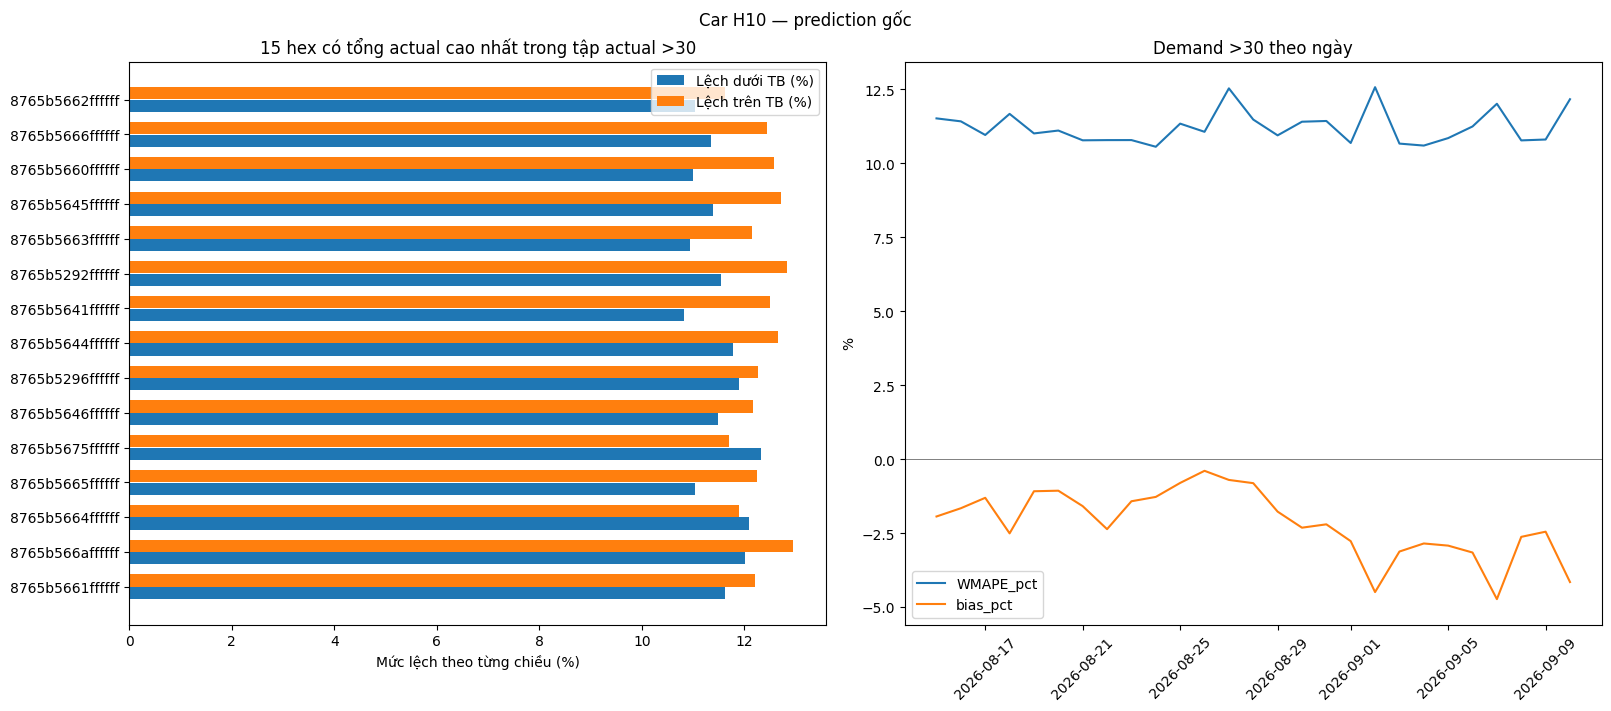

Car H30: 149,767 dòng demand >30, 186 hex; 164 hex đạt tối thiểu 20 dòng/3 ngày. Trong các lần dự đoán dư, lệch trung bình 12.53%; trong các lần dự đoán thiếu, lệch trung bình 11.52%. Tần suất dư/thiếu/đúng: 44.36%/51.17%/4.47%. WMAPE 11.13%, bias -1.51%, tỷ lệ trong ±15% 71.30%. 



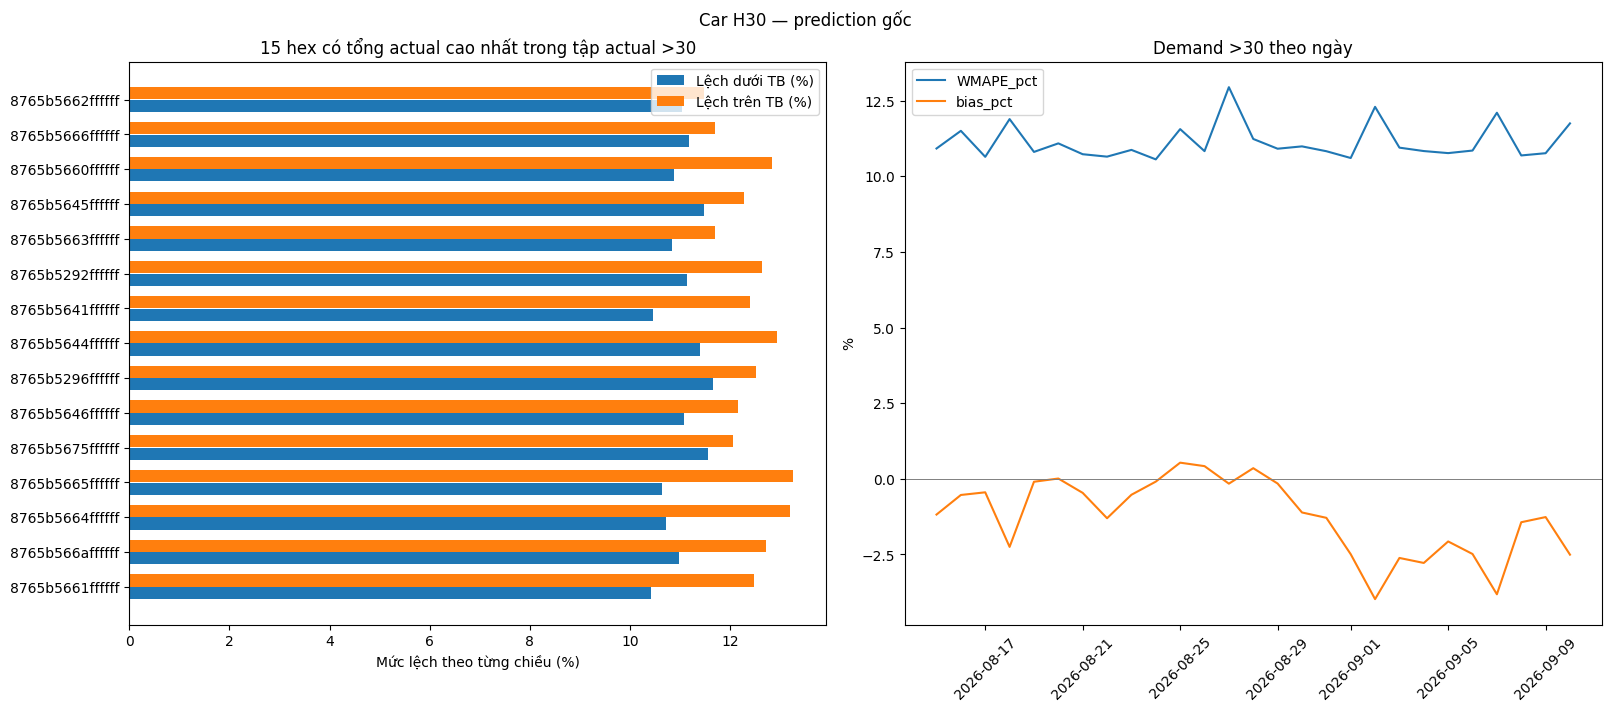

Car H60: 260,689 dòng demand >30, 188 hex; 178 hex đạt tối thiểu 20 dòng/3 ngày. Trong các lần dự đoán dư, lệch trung bình 16.18%; trong các lần dự đoán thiếu, lệch trung bình 13.75%. Tần suất dư/thiếu/đúng: 47.28%/49.16%/3.56%. WMAPE 14.11%, bias -1.36%, tỷ lệ trong ±15% 60.98%. 



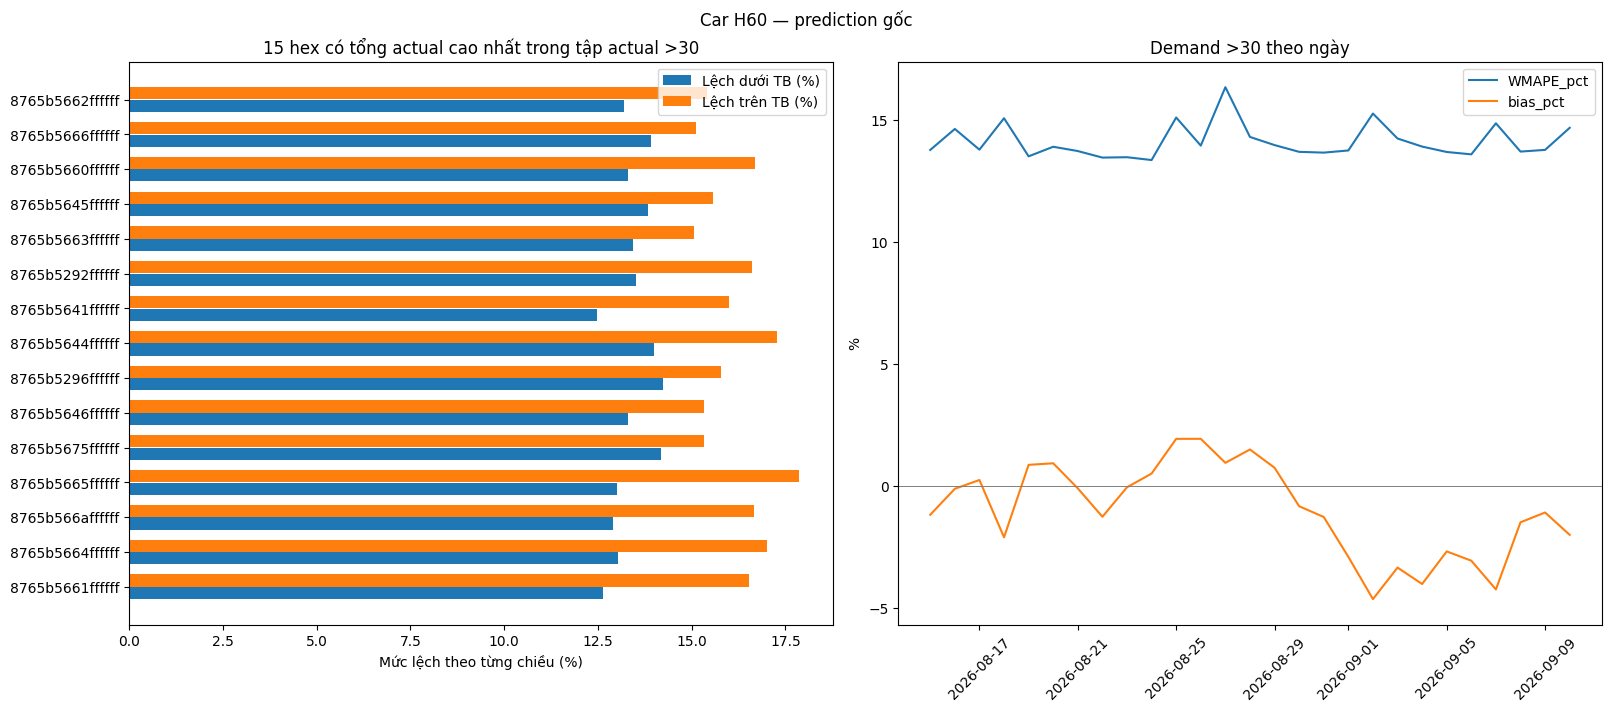

Motorcycle H10: 89,214 dòng demand >30, 161 hex; 130 hex đạt tối thiểu 20 dòng/3 ngày. Trong các lần dự đoán dư, lệch trung bình 12.14%; trong các lần dự đoán thiếu, lệch trung bình 11.10%. Tần suất dư/thiếu/đúng: 42.50%/52.29%/5.21%. WMAPE 10.34%, bias -1.48%, tỷ lệ trong ±15% 73.06%. 



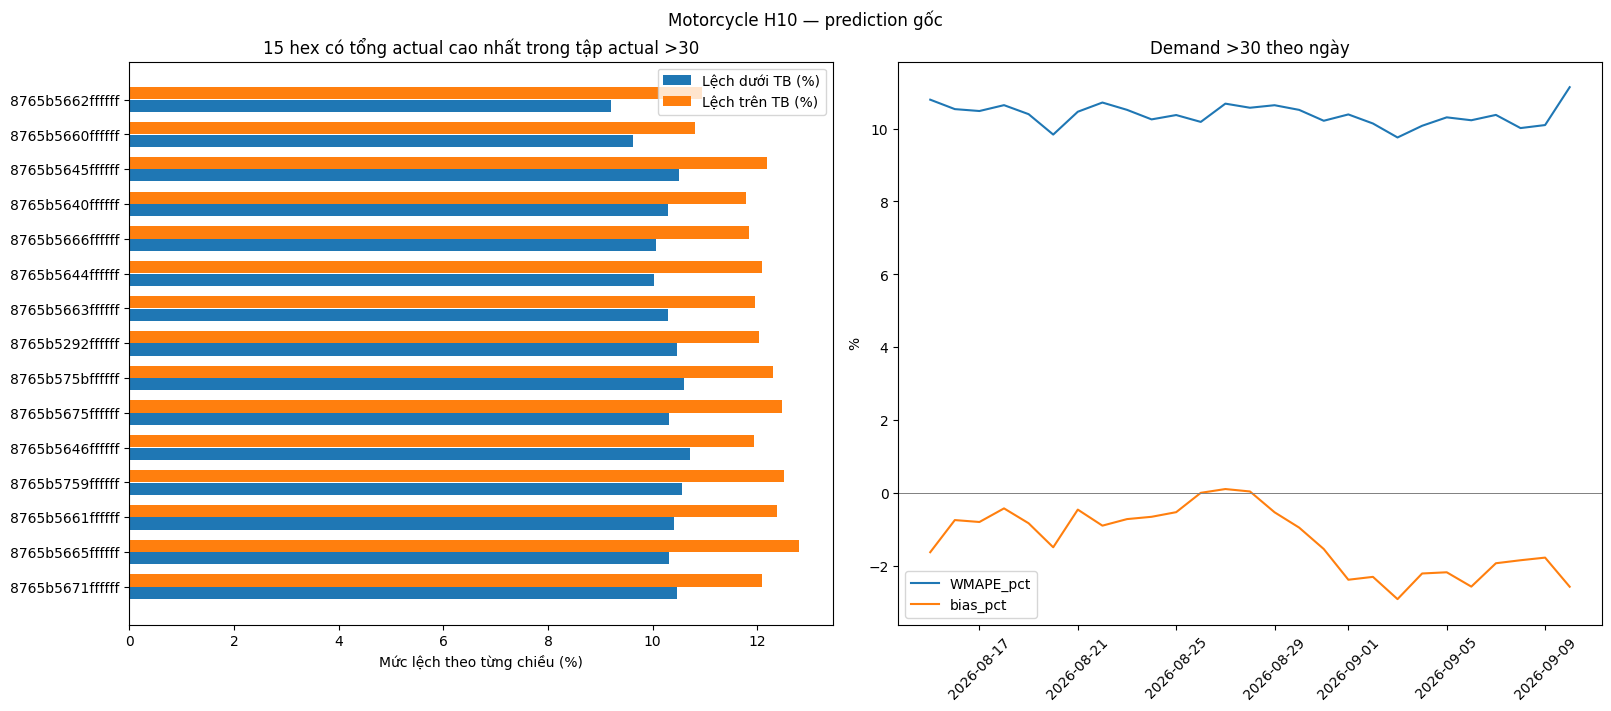

Motorcycle H30: 209,706 dòng demand >30, 170 hex; 164 hex đạt tối thiểu 20 dòng/3 ngày. Trong các lần dự đoán dư, lệch trung bình 12.16%; trong các lần dự đoán thiếu, lệch trung bình 10.97%. Tần suất dư/thiếu/đúng: 45.67%/50.40%/3.93%. WMAPE 10.22%, bias -0.84%, tỷ lệ trong ±15% 72.73%. 



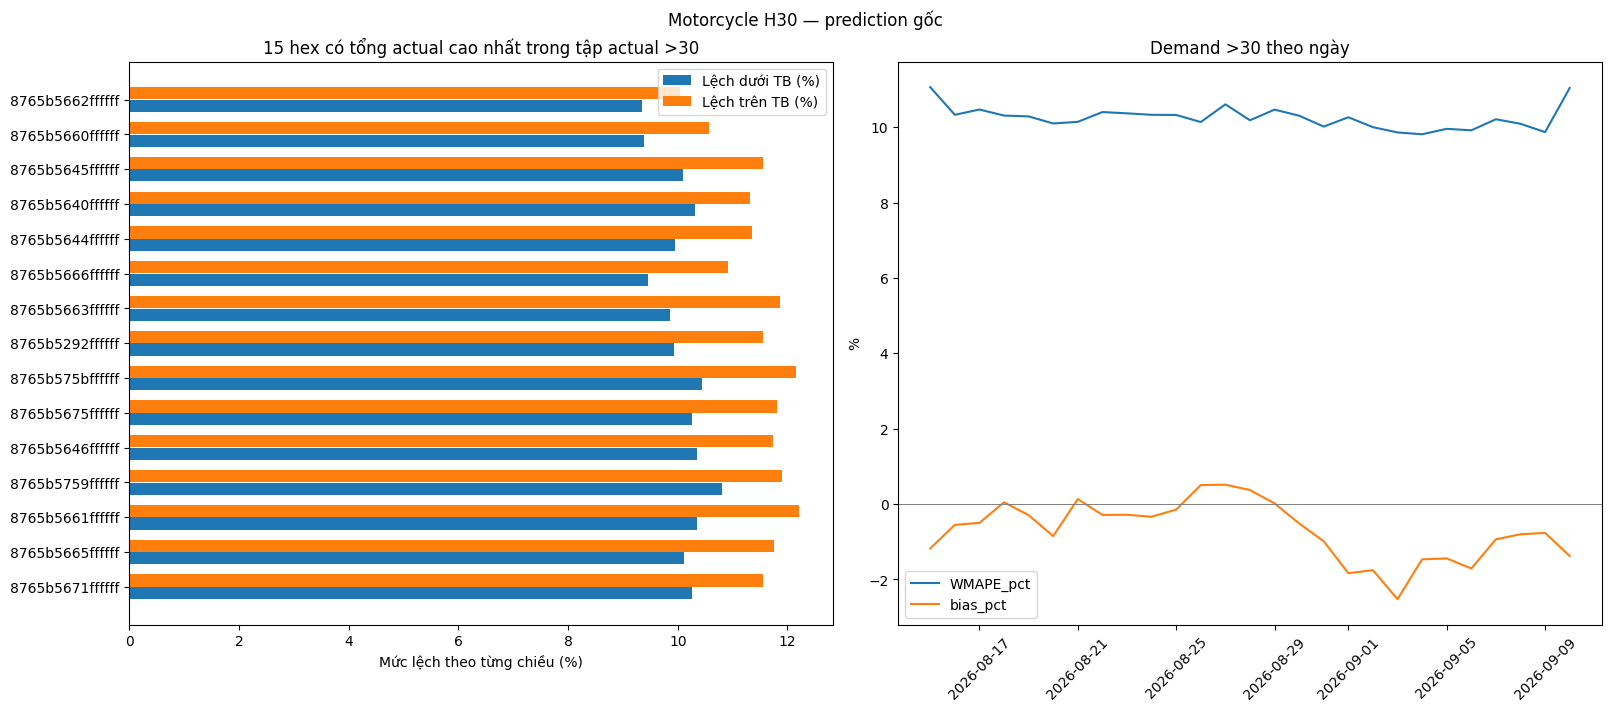

Motorcycle H60: 287,624 dòng demand >30, 171 hex; 166 hex đạt tối thiểu 20 dòng/3 ngày. Trong các lần dự đoán dư, lệch trung bình 16.92%; trong các lần dự đoán thiếu, lệch trung bình 14.04%. Tần suất dư/thiếu/đúng: 48.58%/49.18%/2.24%. WMAPE 13.23%, bias -0.76%, tỷ lệ trong ±15% 58.77%. 



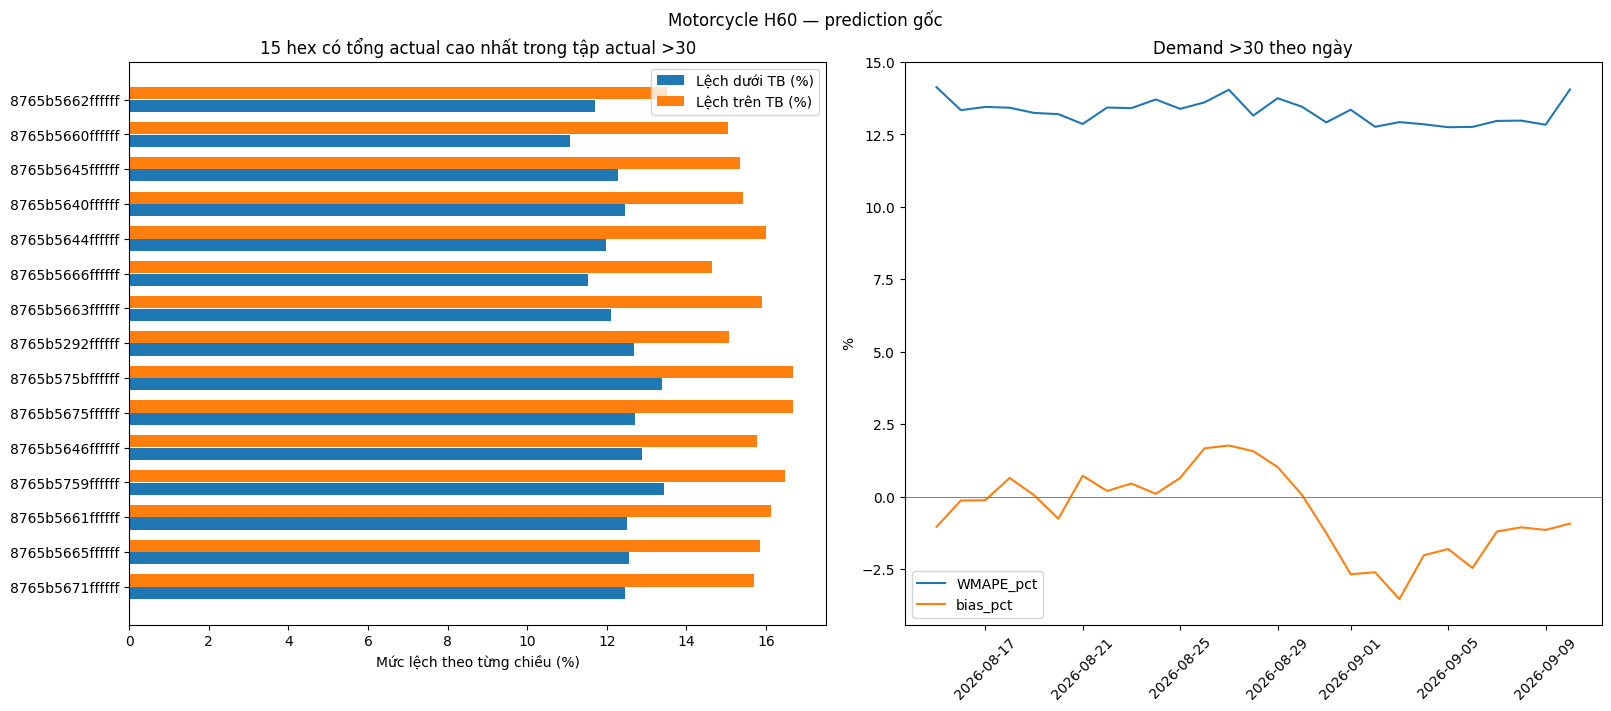

Quyết định: giữ prediction gốc, chưa áp dụng hiệu chỉnh. Các thống kê trên là bằng chứng mô tả, không chứng minh hiệu chỉnh không bao giờ hữu ích. Bias nhỏ cần đọc cùng WMAPE, sai số hai chiều, từng hex và theo ngày. Chưa đặt ngưỡng nghiệm thu nghiệp vụ nên không tự kết luận đạt production. Dữ liệu hiện tại là giả lập.


In [16]:
notes=[]
def fmt(x):return 'không có mẫu/không xác định' if pd.isna(x) else f'{x:.2f}%'
for mode,h in CASES:
    t=TABLES['hex_high_demand']
    t=t.loc[(t['mode']==mode)&(t.horizon==h)]
    r=TABLES['overall'].query('mode == @mode and horizon == @h and scope == "demand_gt30"').iloc[0]
    if r.rows==0:
        notes.append(f'{mode} H{h}: không có dòng actual >30.');continue
    text=(f'{mode} H{h}: {int(r.rows):,} dòng demand >30, {len(t)} hex; '
        f'{int(t.enough_samples.sum())} hex đạt tối thiểu {MIN_GROUP_ROWS} dòng/{MIN_GROUP_DAYS} ngày. '
        f'Trong các lần dự đoán dư, lệch trung bình {fmt(r.mean_over_pct)}; '
        f'trong các lần dự đoán thiếu, lệch trung bình {fmt(r.mean_under_pct)}. '
        f'Tần suất dư/thiếu/đúng: {fmt(r.over_rate_pct)}/{fmt(r.under_rate_pct)}/{fmt(r.exact_rate_pct)}. '
        f'WMAPE {fmt(r.WMAPE_pct)}, bias {fmt(r.bias_pct)}, tỷ lệ trong ±15% {fmt(r.within_15pct)}.')
    notes.append(text);print(text,'\n')
    top=t.sort_values('actual_volume',ascending=False).head(15).sort_values('actual_volume')
    fig,axes=plt.subplots(1,2,figsize=(16,7),constrained_layout=True)
    y=np.arange(len(top))
    axes[0].barh(y-.18,top.mean_under_pct,height=.35,label='Lệch dưới TB (%)')
    axes[0].barh(y+.18,top.mean_over_pct,height=.35,label='Lệch trên TB (%)')
    axes[0].set_yticks(y,top.hex_id_7);axes[0].legend();axes[0].set_xlabel('Mức lệch theo từng chiều (%)')
    axes[0].set_title('15 hex có tổng actual cao nhất trong tập actual >30')
    daily=TABLES['daily_high_demand']
    daily=daily.loc[(daily['mode']==mode)&(daily.horizon==h)].sort_values('day')
    for col in ['WMAPE_pct','bias_pct']:axes[1].plot(pd.to_datetime(daily.day),daily[col],label=col)
    axes[1].axhline(0,color='gray',lw=.7);axes[1].legend();axes[1].tick_params(axis='x',rotation=45)
    axes[1].set_title('Demand >30 theo ngày');axes[1].set_ylabel('%')
    fig.suptitle(f'{mode} H{h} — prediction gốc')
    fig.savefig(REPORT_DIR/f'{mode.lower()}_h{h}_evidence.png',dpi=140)
    plt.show();plt.close(fig)
notes.append('Quyết định: giữ prediction gốc, chưa áp dụng hiệu chỉnh. Các thống kê trên là bằng chứng mô tả, không chứng minh hiệu chỉnh không bao giờ hữu ích. Bias nhỏ cần đọc cùng WMAPE, sai số hai chiều, từng hex và theo ngày. Chưa đặt ngưỡng nghiệm thu nghiệp vụ nên không tự kết luận đạt production. Dữ liệu hiện tại là giả lập.')
(REPORT_DIR/'nhan_xet_tuan4.txt').write_text('\n\n'.join(notes),encoding='utf-8')
print(notes[-1])


## 8. Đóng gói kết quả gửi lại

In [17]:
import hashlib, platform, importlib.metadata, shutil
manifest=dict(calibration_enabled=False,fitted_on='TRAIN_ONLY',test_usage='EVALUATION_ONLY',
    data_source='synthetic_generator_preserved_from_uploaded_notebook',
    generator_sha256=SOURCE_GENERATOR_SHA256,
    demand_threshold=DEMAND_THRESHOLD,high_demand_rule='actual > threshold per row',
    min_rows=MIN_GROUP_ROWS,min_days=MIN_GROUP_DAYS,
    train_end=str(VAL_START),test_start=str(TEST_START),test_end_exclusive=str(HOLDOUT_START),
    holdout_start=str(HOLDOUT_START),holdout_end_exclusive=str(HOLDOUT_END),
    holdout_generation=HOLDOUT_MANIFEST,
    prediction_rule='rint(clip(model_prediction,0,None))',
    params=[dict(mode=m,horizon=h,leaves=LOCKED[(m,h)][0],trees=LOCKED[(m,h)][1],features=FEATURE_COLUMNS[(m,h)]) for m,h in CASES],
    python=platform.python_version(),
    versions={p:importlib.metadata.version(p) for p in ['numpy','pandas','lightgbm','h3','holidays','pyarrow','scipy']})
(REPORT_DIR/'manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
archive=shutil.make_archive(str(RUN_DIR/'tuan4_ketqua_bao_cao'),'zip',root_dir=REPORT_DIR)
print('Gửi lại file:',archive)
print('Và notebook đã Save kèm output sau Run All.')
print('Toàn bộ prediction TEST lưu riêng tại:',PREDICTION_DIR)


Gửi lại file: /kaggle/working/tuan4_khong_hieu_chinh/tuan4_ketqua_bao_cao.zip
Và notebook đã Save kèm output sau Run All.
Toàn bộ prediction TEST lưu riêng tại: /kaggle/working/tuan4_khong_hieu_chinh/predictions


### Audit 01

In [18]:
# Chạy sau các cell model chính.
import gc, json, hashlib, shutil, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DA_MODES = ('Car', 'Motorcycle')
DA_HORIZONS = (10, 30, 60)
DA_SPLITS = ('TRAIN', 'VALIDATION', 'TEST', 'HOLDOUT')
DA_WEEKDAYS = ['Thứ 2', 'Thứ 3', 'Thứ 4', 'Thứ 5', 'Thứ 6', 'Thứ 7', 'Chủ nhật']
DA_HOLDOUT_DAYS = HOLDOUT_DAYS
DA_HOLDOUT_START = HOLDOUT_START  # 14 ngày fake mới sau dữ liệu gốc.
DA_BATCH_ROWS = 100_000
DA_CURVE_SAMPLE_ROWS = 50_000  # CHỈ đường học dùng mẫu cố định; metric chính chấm toàn bộ.
DA_THREADS = 4
DA_SEED = 20261012
DA_GAP_PP = 3.0        # Ngưỡng cảnh báo tham khảo, không phải chuẩn nghiệm thu.
DA_GAP_RATIO = 1.25
DA_MIN_GROUP_ROWS = 100
DA_MIN_GROUP_DAYS = 3
DA_BOOTSTRAP_REPEATS = 500
DA_ROOT = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path.cwd()
DA_OUT = DA_ROOT / 'demand_trend_overfit_audit'
DA_OUT.mkdir(parents=True, exist_ok=True)
DA_TABLES, DA_FIGURES = {}, []
assert set(MODELS)=={(m,h) for m in DA_MODES for h in DA_HORIZONS}

def da_local_time(values):
    s = pd.to_datetime(values)
    return s.dt.tz_localize('Asia/Ho_Chi_Minh') if s.dt.tz is None else s.dt.tz_convert('Asia/Ho_Chi_Minh')

def da_local_stamp(value):
    t = pd.Timestamp(value)
    return t.tz_localize('Asia/Ho_Chi_Minh') if t.tzinfo is None else t.tz_convert('Asia/Ho_Chi_Minh')

DA_VAL_START, DA_TEST_START = map(da_local_stamp, (VAL_START, TEST_START))
DA_HOLDOUT_START, DA_END = map(da_local_stamp, (HOLDOUT_START, HOLDOUT_END))
if not DA_VAL_START < DA_TEST_START < DA_HOLDOUT_START < DA_END:
    raise ValueError('Cần TRAIN < VAL < TEST < HOLDOUT < END.')
assert DA_END - DA_HOLDOUT_START == pd.Timedelta(days=14)
DA_HOLDOUT_STATUS = 'NEW_SYNTHETIC_14_DAY_HOLDOUT'
assert HOLDOUT_MANIFEST['historical_values_unchanged']
print('Mốc giờ Việt Nam:', DA_VAL_START, '|', DA_TEST_START, '|', DA_HOLDOUT_START, '|', DA_END)
print('HOLDOUT là 14 ngày fake mới; không nằm trong TRAIN/VAL/TEST và không dùng chọn model.')
print('Dùng lại MODELS chính đã fit TRAIN_ONLY, không train thêm.')


Mốc giờ Việt Nam: 2026-07-16 09:40:00+07:00 | 2026-08-15 09:40:00+07:00 | 2026-09-11 00:00:00+07:00 | 2026-09-25 00:00:00+07:00
HOLDOUT là 14 ngày fake mới; không nằm trong TRAIN/VAL/TEST và không dùng chọn model.
Dùng lại MODELS chính đã fit TRAIN_ONLY, không train thêm.


### Audit 02

In [19]:
def da_indices(frame, horizon):
    ts = da_local_time(frame.bucket_start)
    end = ts + pd.Timedelta(minutes=horizon)
    conditions = {
        'TRAIN': (ts < DA_VAL_START) & (end <= DA_VAL_START),
        'VALIDATION': (ts >= DA_VAL_START) & (ts < DA_TEST_START) & (end <= DA_TEST_START),
        'TEST': (ts >= DA_TEST_START) & (ts < DA_HOLDOUT_START) & (end <= DA_HOLDOUT_START),
        'HOLDOUT': (ts >= DA_HOLDOUT_START) & (ts < DA_END) & (end <= DA_END),
    }
    ans = {k: np.flatnonzero(v.to_numpy()) for k,v in conditions.items()}
    joined = np.concatenate(list(ans.values()))
    if len(np.unique(joined)) != len(joined):
        raise AssertionError('Trùng dòng giữa các tập.')
    if any(len(v) == 0 for v in ans.values()):
        raise ValueError(f'H{horizon}: có tập rỗng; kiểm tra mốc thời gian.')
    for left,right in zip(DA_SPLITS[:-1],DA_SPLITS[1:]):
        if end.iloc[ans[left]].max() > ts.iloc[ans[right]].min():
            raise AssertionError('Target vượt ranh giới split.')
    return ans

def da_metrics(y, p):
    y,p = np.asarray(y,dtype=float),np.asarray(p,dtype=float)
    if not len(y) or y.shape != p.shape or not (np.isfinite(y).all() and np.isfinite(p).all()):
        raise ValueError('Actual/prediction rỗng, lệch dòng hoặc không hữu hạn.')
    if (y < 0).any(): raise ValueError('Demand không được âm.')
    err = p-y; absolute=np.abs(err); volume=y.sum()
    high=y>30
    return dict(rows=len(y), actual_sum=volume, prediction_sum=p.sum(),
                actual_mean=y.mean(), prediction_mean=p.mean(),
                WMAPE_pct=100*absolute.sum()/volume if volume>0 else np.nan,
                bias_pct=100*err.sum()/volume if volume>0 else np.nan,
                MAE=absolute.mean(), RMSE=np.sqrt(np.mean(err**2)),
                P95_abs_error=np.quantile(absolute,.95),
                high_demand_rows=int(high.sum()),
                within15_actual_gt30_pct=100*np.mean(absolute[high]/y[high]<=.15) if high.any() else np.nan)

def da_group_metrics(data, keys):
    x=data.groupby(keys,observed=True,dropna=False).agg(
        rows=('actual','size'), days=('date','nunique'), actual_sum=('actual','sum'),
        prediction_sum=('prediction','sum'), abs_sum=('absolute','sum'),
        error_sum=('error','sum'), squared_sum=('squared','sum')).reset_index()
    den=x.actual_sum.where(x.actual_sum>0)
    x['WMAPE_pct']=100*x.abs_sum/den; x['bias_pct']=100*x.error_sum/den
    x['MAE']=x.abs_sum/x.rows; x['RMSE']=np.sqrt(x.squared_sum/x.rows)
    x['actual_mean']=x.actual_sum/x.rows; x['prediction_mean']=x.prediction_sum/x.rows
    x['low_support']=(x.rows<DA_MIN_GROUP_ROWS)|(x.days<DA_MIN_GROUP_DAYS)
    return x

def da_table(name, data):
    DA_TABLES[name]=data
    data.to_csv(DA_OUT/f'{name}.csv', index=False, encoding='utf-8-sig')
    return data

def da_figure(name, fig):
    path=DA_OUT/f'{name}.png';fig.savefig(path,dpi=150,bbox_inches='tight')
    DA_FIGURES.append(path.name);plt.show();plt.close(fig)

def da_input(mode,horizon,frame,columns,indices,variant):
    return build_input((mode,horizon),indices)

def da_predict(model, mode,horizon,frame,columns,indices,variant,iteration=None):
    result=np.empty(len(indices),dtype=np.float64)
    for start in range(0,len(indices),DA_BATCH_ROWS):
        ix=indices[start:start+DA_BATCH_ROWS]
        x=da_input(mode,horizon,frame,columns,ix,variant)
        if x.shape[1]!=model.n_features_in_:raise AssertionError('Sai số cột feature.')
        # Cùng hậu xử lý cho mọi model/split, không ép int32 để tránh overflow.
        pred=np.asarray(model.predict(x,num_iteration=iteration),dtype=np.float64)
        if not np.isfinite(pred).all():raise ValueError('Prediction không hữu hạn.')
        result[start:start+len(ix)]=np.rint(np.clip(pred,0,None))
        del x
    return result

def da_boot_ci(daily):
    a=daily.actual_sum.to_numpy(float); e=daily.abs_sum.to_numpy(float)
    if len(a)<7:return (np.nan,np.nan)
    rng=np.random.default_rng(DA_SEED)
    take=rng.integers(0,len(a),size=(DA_BOOTSTRAP_REPEATS,len(a)))
    den=a[take].sum(axis=1);num=e[take].sum(axis=1)
    scores=np.divide(100*num,den,out=np.full(len(den),np.nan),where=den>0)
    return tuple(np.nanquantile(scores,[.025,.975]))


### Audit 03

In [20]:
# Đọc RAW H10 để EDA không bị lệch do lọc lag/target của model.
# Nếu file gốc không còn, MODE_FRAMES chỉ là fallback và được ghi rõ phạm vi.
if 'DA_RAW_OVERRIDE' in globals():
    _raw=DA_RAW_OVERRIDE.copy();DA_RAW_SOURCE='provided_override'
elif 'DEMAND_PATH' in globals() and Path(DEMAND_PATH).is_file():
    _raw=pd.read_parquet(DEMAND_PATH,columns=['period_datetime_utc','hex_id_7','travel_mode','total_demand'])
    _raw['bucket_start']=pd.to_datetime(_raw.pop('period_datetime_utc'),utc=True).dt.tz_convert('Asia/Ho_Chi_Minh')
    _raw=_raw.rename(columns={'total_demand':'demand_h10'})
    DA_RAW_SOURCE='raw_parquet_before_feature_filter'
else:
    _raw=pd.concat([MODE_FRAMES[m][['bucket_start','hex_id_7','demand_h10']].assign(travel_mode=m)
                    for m in DA_MODES],ignore_index=True)
    DA_RAW_SOURCE='MODE_FRAMES_after_feature_filter'
    warnings.warn('Không còn parquet gốc: EDA chỉ trên dòng còn sau lọc feature; xem coverage.csv.')
_raw=_raw.loc[_raw.travel_mode.isin(DA_MODES)].copy()
_raw['bucket_start']=da_local_time(_raw.bucket_start)
if _raw.duplicated(['travel_mode','hex_id_7','bucket_start']).any():raise ValueError('Trùng khóa RAW.')
if not np.isfinite(_raw.demand_h10).all() or (_raw.demand_h10<0).any():raise ValueError('Demand RAW không hợp lệ.')
if ((_raw.bucket_start.dt.minute%10!=0)|(_raw.bucket_start.dt.second!=0)).any():raise ValueError('Bucket không ở lưới 10 phút.')
_raw['split']='PURGED'
for split,ix in da_indices(_raw,10).items():_raw.iloc[ix,_raw.columns.get_loc('split')]=split
_raw=_raw.loc[_raw.split!='PURGED'].copy()
_raw['date']=_raw.bucket_start.dt.floor('D');_raw['hour']=_raw.bucket_start.dt.hour
_raw['weekday']=_raw.bucket_start.dt.dayofweek
_cov=[]
for (mode,split),g in _raw.groupby(['travel_mode','split'],observed=True):
    lo,hi=g.bucket_start.min(),g.bucket_start.max()
    grid_slots=int((hi-lo)/pd.Timedelta(minutes=10))+1
    _cov.append(dict(mode=mode,split=split,rows=len(g),days=g.date.nunique(),hexes=g.hex_id_7.nunique(),
                     start=str(lo),end=str(hi),demand_sum=g.demand_h10.sum(),demand_per_observed_bucket=g.demand_h10.mean(),
                     observed_grid_pct=100*len(g)/(grid_slots*g.hex_id_7.nunique()),source=DA_RAW_SOURCE))
DA_COVERAGE=da_table('coverage',pd.DataFrame(_cov))
# Một hex-hour chỉ hợp lệ khi đủ 6 bucket 10 phút trong CÙNG split.
_hour=(_raw.assign(hour_start=_raw.bucket_start.dt.floor('h'))
       .groupby(['travel_mode','split','hex_id_7','hour_start'],observed=True)
       .agg(demand=('demand_h10','sum'),buckets=('bucket_start','nunique')).reset_index())
_hour['complete_hour']=_hour.buckets.eq(6)
da_table('hour_coverage',_hour.groupby(['travel_mode','split'],observed=True).agg(
    observed_hex_hours=('buckets','size'),complete_hex_hours=('complete_hour','sum')).reset_index())
DA_HOURLY=_hour.loc[_hour.complete_hour].copy()
DA_HOURLY['date']=DA_HOURLY.hour_start.dt.floor('D')
DA_HOURLY['hour']=DA_HOURLY.hour_start.dt.hour;DA_HOURLY['weekday']=DA_HOURLY.hour_start.dt.dayofweek
DA_COMMON_HEX={}
for mode in DA_MODES:
    sets=[set(DA_HOURLY.loc[(DA_HOURLY.travel_mode==mode)&(DA_HOURLY.split==s),'hex_id_7']) for s in DA_SPLITS]
    DA_COMMON_HEX[mode]=set.intersection(*sets)
    if not DA_COMMON_HEX[mode]:warnings.warn(f'{mode}: không có hex chung; không dùng fixed-hex để kết luận.')
_profile_parts=[]
for mode in DA_MODES:
    for view in ['observed','common_hex_equal_weight']:
        g=DA_HOURLY.loc[DA_HOURLY.travel_mode==mode]
        if view=='common_hex_equal_weight':g=g.loc[g.hex_id_7.isin(DA_COMMON_HEX[mode])]
        for grain,keys in [('hour',['hour']),('weekday',['weekday']),('weekday_hour',['weekday','hour'])]:
            if g.empty:continue
            byhex=g.groupby(['split','hex_id_7']+keys,observed=True).demand.mean().reset_index()
            # observed = mỗi hex-hour cùng trọng số; common = mỗi hex trong nhóm cùng trọng số.
            base=(byhex.groupby(['split']+keys,observed=True).demand.mean() if view!='observed'
                  else g.groupby(['split']+keys,observed=True).demand.mean()).rename('mean_demand').reset_index()
            support=g.groupby(['split']+keys,observed=True).agg(
                hex_hours=('demand','size'),days=('date','nunique'),hexes=('hex_id_7','nunique')).reset_index()
            base=base.merge(support,on=['split']+keys,validate='one_to_one')
            base['mode']=mode;base['view']=view;base['grain']=grain
            base['low_support']=base.days<DA_MIN_GROUP_DAYS
            _profile_parts.append(base)
DA_PROFILES=da_table('demand_profiles',pd.concat(_profile_parts,ignore_index=True))
DA_DAILY=da_table('demand_daily',_raw.groupby(['travel_mode','split','date'],observed=True).agg(
    demand_sum=('demand_h10','sum'),demand_per_bucket=('demand_h10','mean'),
    observed_rows=('demand_h10','size'),hexes=('hex_id_7','nunique'),time_slots=('bucket_start','nunique')).reset_index())
DA_DAILY['complete_clock_day']=DA_DAILY.time_slots.eq(144)
da_table('demand_daily',DA_DAILY)
display(DA_COVERAGE.round(3));display(DA_TABLES['hour_coverage'])
print('observed_grid_pct là độ phủ lưới tiềm năng, không tự kết luận dữ liệu thiếu: hex có thể không hoạt động.')
print('Tổng ngày dùng RAW H10 không chồng lấn. Profile là demand/hex/giờ trên giờ đủ 6 bucket.')
print('Common-hex cân bằng trọng số hex; hỗ trợ theo thứ/giờ vẫn có thể khác. Cần đọc days, hexes, low_support.')
del _raw,_hour;gc.collect()


,mode,split,rows,days,hexes,start,end,demand_sum,demand_per_observed_bucket,observed_grid_pct,source
0,Car,HOLDOUT,293616,14,159,2026-09-11 00:00:00+07:00,2026-09-24 23:50:00+07:00,3182161,10.838,91.599,raw_parquet_before_feature_filter
1,Car,TEST,567406,27,188,2026-08-15 09:40:00+07:00,2026-09-10 23:50:00+07:00,6121221,10.788,78.802,raw_parquet_before_feature_filter
2,Car,TRAIN,1649638,77,217,2026-05-01 00:00:00+07:00,2026-07-16 09:30:00+07:00,15853982,9.611,69.097,raw_parquet_before_feature_filter
3,Car,VALIDATION,646674,31,185,2026-07-16 09:40:00+07:00,2026-08-15 09:30:00+07:00,5946047,9.195,80.915,raw_parquet_before_feature_filter
4,Motorcycle,HOLDOUT,263232,14,152,2026-09-11 00:00:00+07:00,2026-09-24 23:50:00+07:00,4935699,18.750,85.902,raw_parquet_before_feature_filter
5,Motorcycle,TEST,507218,27,171,2026-08-15 09:40:00+07:00,2026-09-10 23:50:00+07:00,9566149,18.860,77.446,raw_parquet_before_feature_filter
6,Motorcycle,TRAIN,1442360,77,217,2026-05-01 00:00:00+07:00,2026-07-16 09:30:00+07:00,24297176,16.845,60.415,raw_parquet_before_feature_filter
7,Motorcycle,VALIDATION,591234,31,182,2026-07-16 09:40:00+07:00,2026-08-15 09:30:00+07:00,9228847,15.609,75.198,raw_parquet_before_feature_filter


,travel_mode,split,observed_hex_hours,complete_hex_hours
0,Car,HOLDOUT,48936,48936
1,Car,TEST,94667,94518
2,Car,TRAIN,274990,274839
3,Car,VALIDATION,107929,107630
4,Motorcycle,HOLDOUT,43872,43872
5,Motorcycle,TEST,84628,84490
6,Motorcycle,TRAIN,240440,240300
7,Motorcycle,VALIDATION,98678,98401


observed_grid_pct là độ phủ lưới tiềm năng, không tự kết luận dữ liệu thiếu: hex có thể không hoạt động.
Tổng ngày dùng RAW H10 không chồng lấn. Profile là demand/hex/giờ trên giờ đủ 6 bucket.
Common-hex cân bằng trọng số hex; hỗ trợ theo thứ/giờ vẫn có thể khác. Cần đọc days, hexes, low_support.


17782

### Audit 04

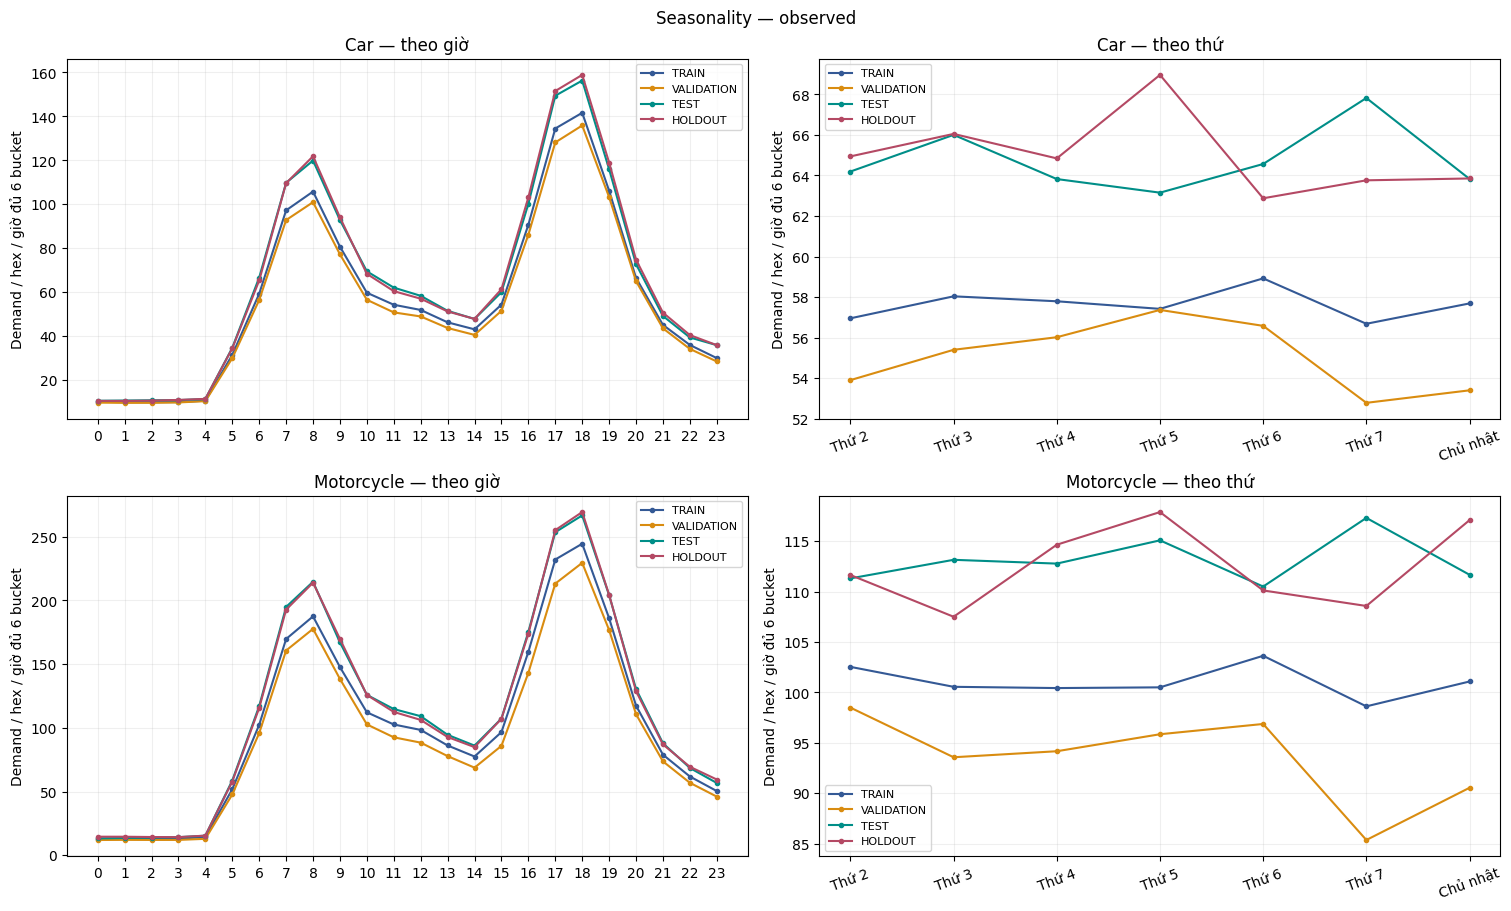

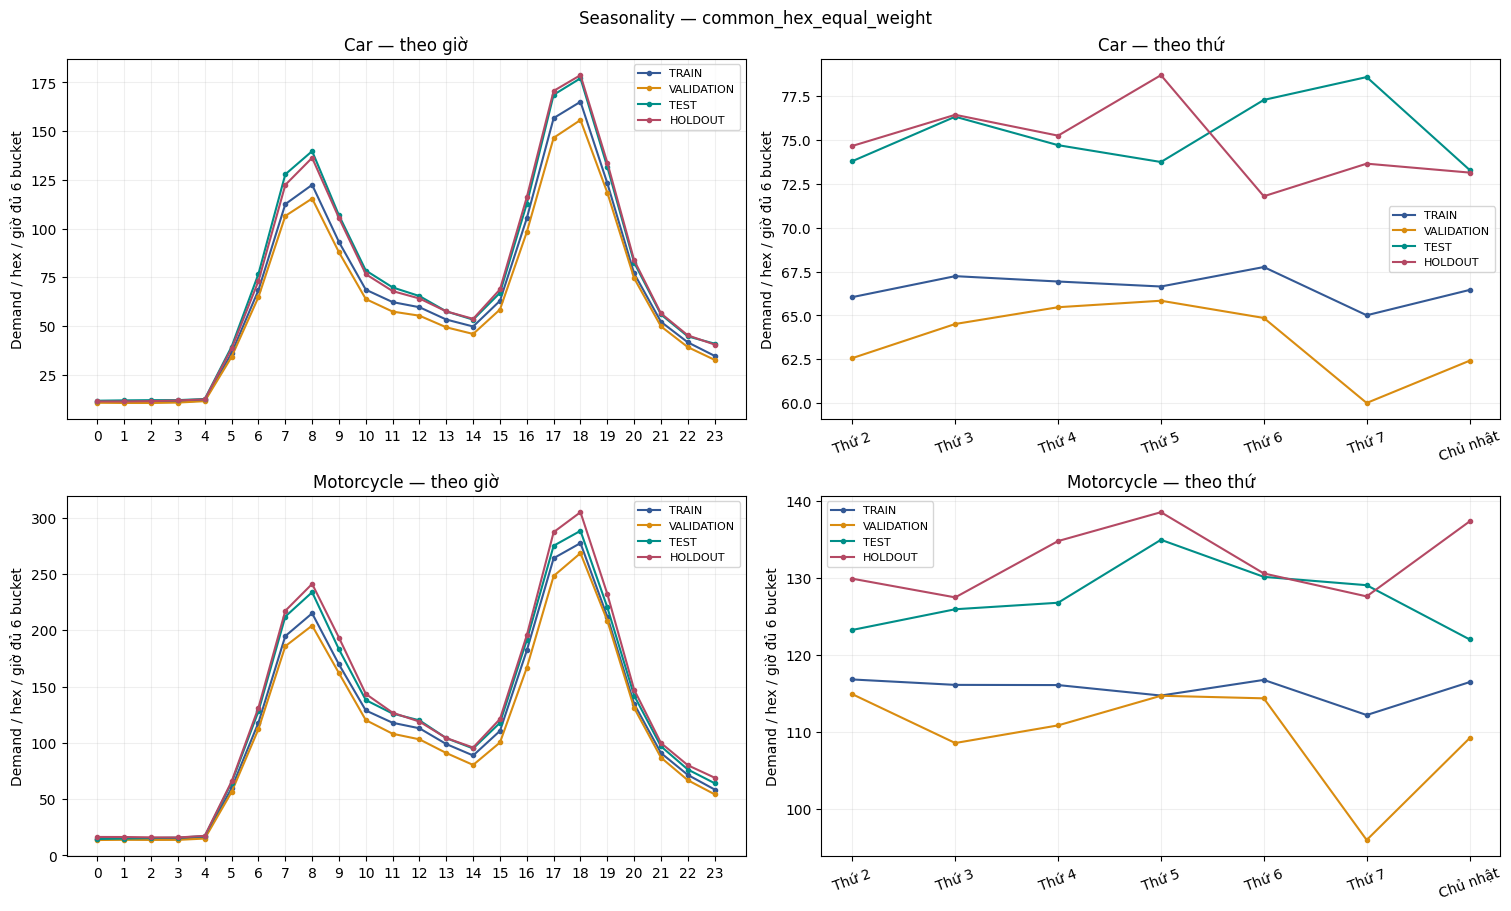

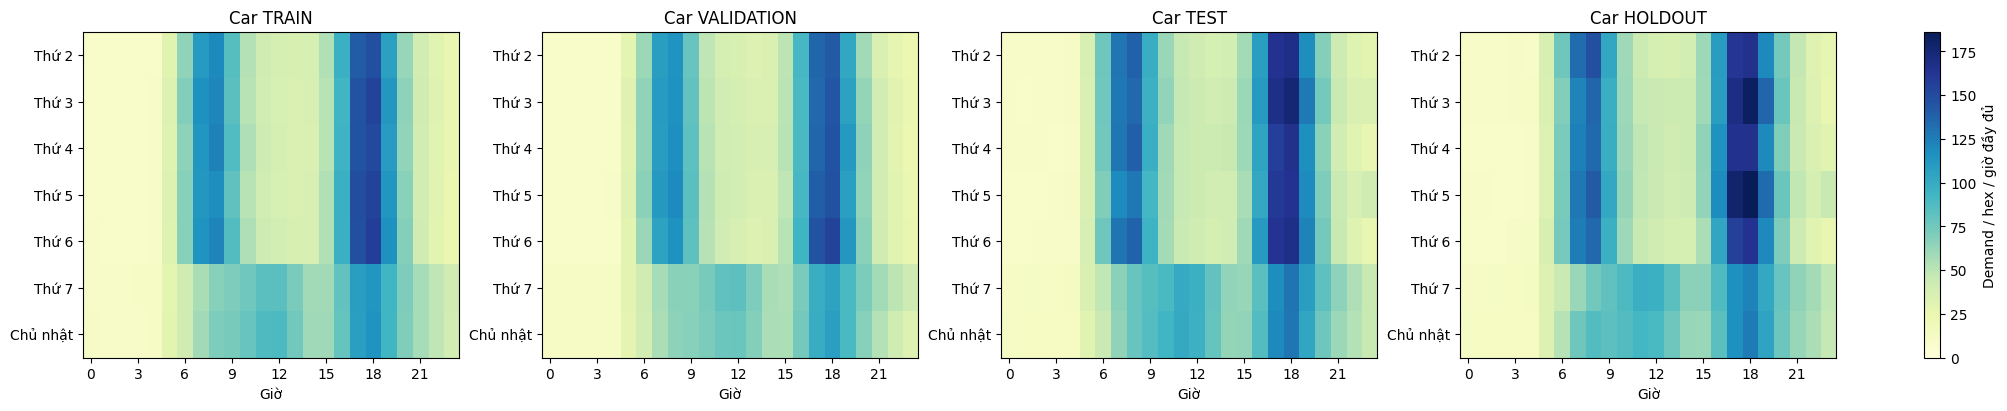

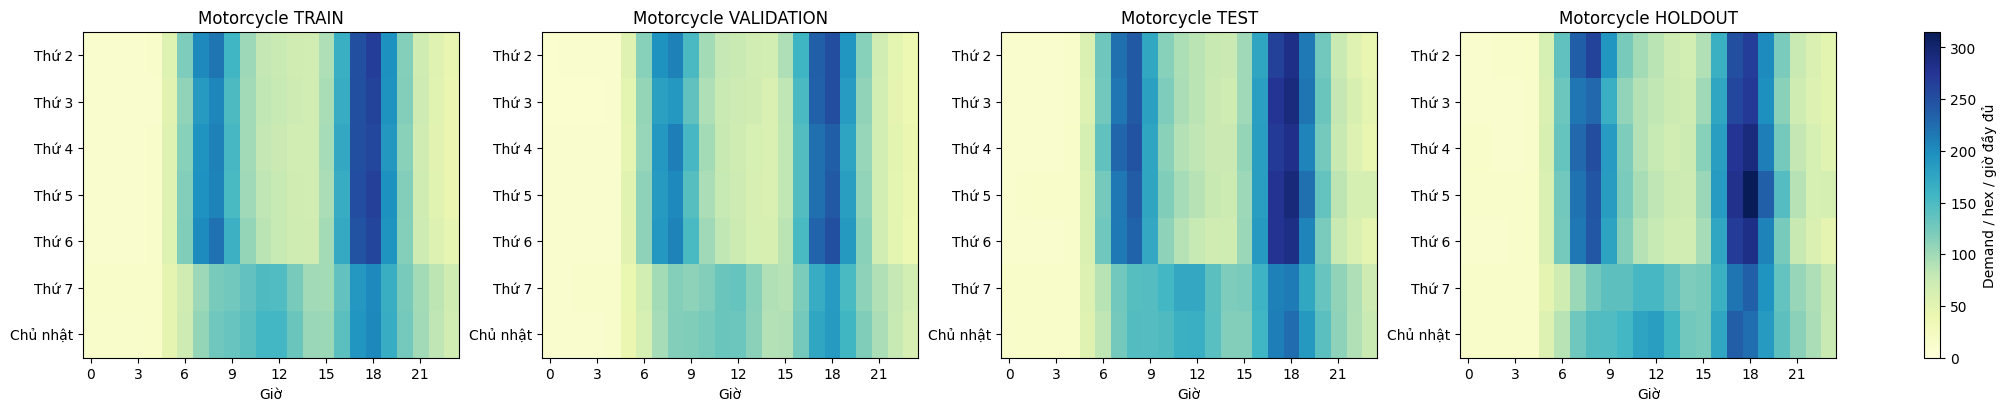

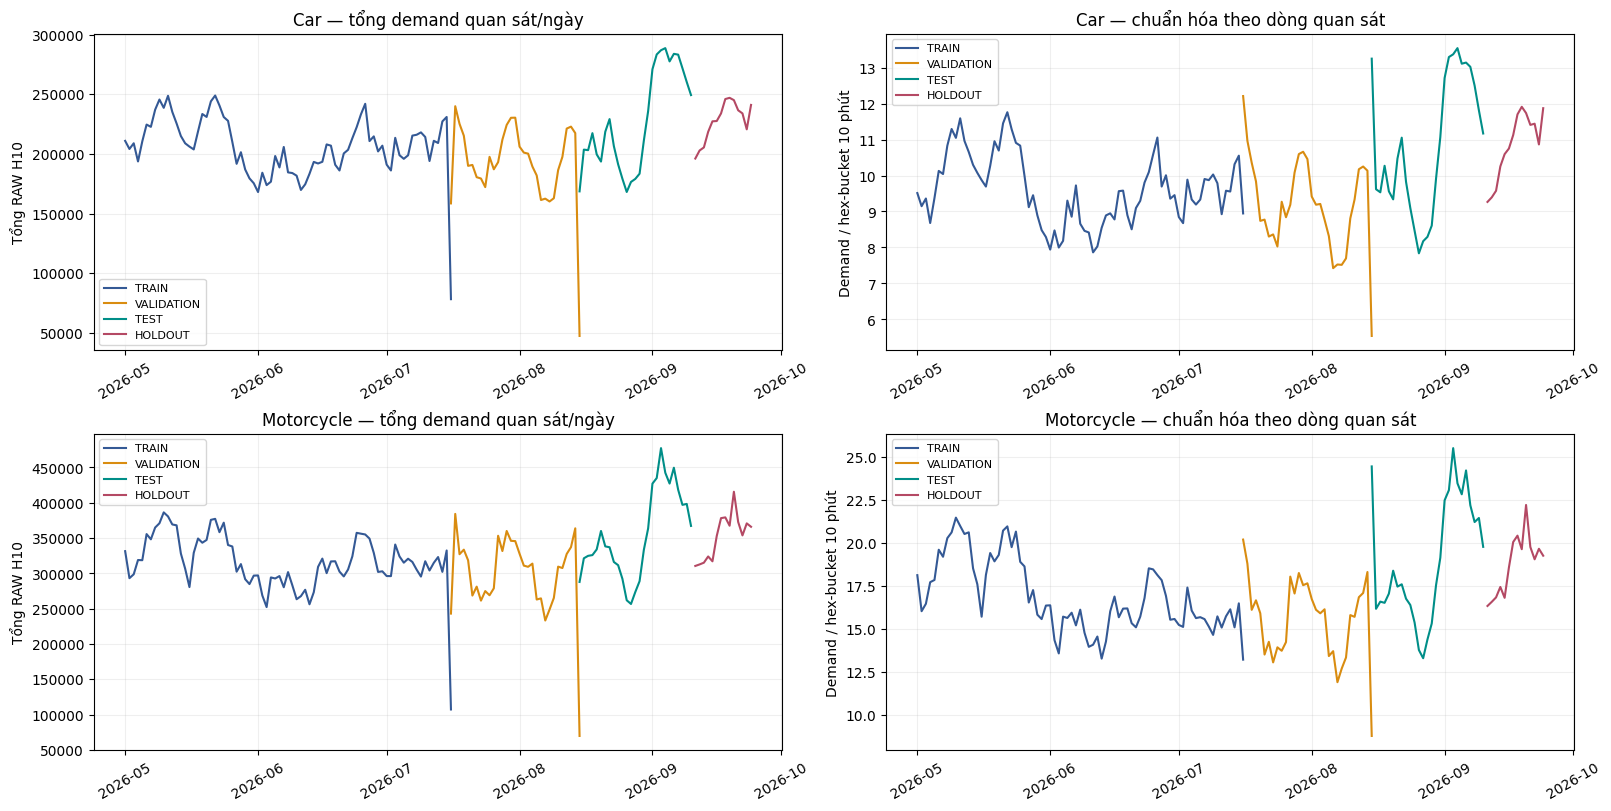

,mode,split,grain,peak_group,peak_mean,peak_days,low_group,low_mean
0,Car,HOLDOUT,hour,18,158.863,14,1,10.558
1,Car,HOLDOUT,weekday,3,68.959,2,4,62.876
2,Car,TEST,hour,18,156.283,27,0,10.631
3,Car,TEST,weekday,5,67.820,4,3,63.152
4,Car,TRAIN,hour,18,141.620,76,1,9.971
5,Car,TRAIN,weekday,4,58.925,11,5,56.687
6,Car,VALIDATION,hour,18,135.859,30,1,9.690
7,Car,VALIDATION,weekday,3,57.371,5,5,52.789
8,Motorcycle,HOLDOUT,hour,18,269.312,14,3,14.248
9,Motorcycle,HOLDOUT,weekday,3,117.888,2,1,107.502


In [21]:
_da_colors={'TRAIN':'#345995','VALIDATION':'#d98c10','TEST':'#008e88','HOLDOUT':'#b44964'}
for view in ['observed','common_hex_equal_weight']:
    fig,axes=plt.subplots(2,2,figsize=(15,9),constrained_layout=True)
    for r,mode in enumerate(DA_MODES):
        for c,grain in enumerate(['hour','weekday']):
            ax=axes[r,c]
            for split in DA_SPLITS:
                v=DA_PROFILES.query('mode == @mode and view == @view and grain == @grain and split == @split').sort_values(grain)
                ax.plot(v[grain],v.mean_demand,marker='o',markersize=3,label=split,color=_da_colors[split])
            ax.set(title=f'{mode} — theo {"giờ" if grain=="hour" else "thứ"}',ylabel='Demand / hex / giờ đủ 6 bucket')
            ticks=list(range(24)) if grain=='hour' else list(range(7))
            ax.set_xticks(ticks, ticks if grain=='hour' else DA_WEEKDAYS,rotation=0 if grain=='hour' else 20)
            ax.grid(alpha=.2);ax.legend(fontsize=8)
    fig.suptitle('Seasonality — '+view)
    da_figure('demand_profiles_'+view,fig)
# Heatmap cùng thang màu cho 4 split của từng phương tiện; ô thiếu giữ NaN.
for mode in DA_MODES:
    sub=DA_PROFILES.query('mode == @mode and view == "observed" and grain == "weekday_hour"')
    vmax=sub.mean_demand.max()
    fig,axes=plt.subplots(1,4,figsize=(20,4),constrained_layout=True)
    for ax,split in zip(axes,DA_SPLITS):
        z=sub.query('split == @split').pivot(index='weekday',columns='hour',values='mean_demand').reindex(index=range(7),columns=range(24))
        im=ax.imshow(z,aspect='auto',vmin=0,vmax=vmax,cmap='YlGnBu')
        ax.set(title=f'{mode} {split}',xlabel='Giờ');ax.set_yticks(range(7),DA_WEEKDAYS);ax.set_xticks(range(0,24,3))
    fig.colorbar(im,ax=list(axes),label='Demand / hex / giờ đầy đủ')
    da_figure('weekday_hour_'+mode,fig)
fig,axes=plt.subplots(2,2,figsize=(16,8),constrained_layout=True)
for r,mode in enumerate(DA_MODES):
    for split in DA_SPLITS:
        v=DA_DAILY.query('travel_mode == @mode and split == @split').sort_values('date')
        axes[r,0].plot(v.date,v.demand_sum,label=split,color=_da_colors[split])
        axes[r,1].plot(v.date,v.demand_per_bucket,label=split,color=_da_colors[split])
    axes[r,0].set(title=f'{mode} — tổng demand quan sát/ngày',ylabel='Tổng RAW H10')
    axes[r,1].set(title=f'{mode} — chuẩn hóa theo dòng quan sát',ylabel='Demand / hex-bucket 10 phút')
    for ax in axes[r]:ax.tick_params(axis='x',rotation=30);ax.legend(fontsize=8);ax.grid(alpha=.2)
da_figure('daily_demand',fig)
# Đỉnh/đáy theo nhóm; số ngày ít (đặc biệt HOLDOUT 14 ngày) là mô tả, chưa chứng minh seasonality ổn định.
_peak=[]
for key,g in DA_PROFILES.query('view == "observed" and grain != "weekday_hour"').groupby(['mode','split','grain'],observed=True):
    hi=g.loc[g.mean_demand.idxmax()];lo=g.loc[g.mean_demand.idxmin()];grain=key[2]
    _peak.append(dict(mode=key[0],split=key[1],grain=grain,peak_group=int(hi[grain]),
                     peak_mean=hi.mean_demand,peak_days=int(hi.days),low_group=int(lo[grain]),low_mean=lo.mean_demand))
display(da_table('seasonal_peaks',pd.DataFrame(_peak)).round(3))


### Audit 05

In [22]:
# Cạnh phải được tính vào bin: (a,b]. [0] là bin riêng. Có thể đổi các mốc trước khi chạy cell đánh giá.
DA_ABS_EDGES=[-np.inf,0,1,2,3,5,10,20,50,100,np.inf]
DA_ABS_LABELS=['0','(0,1]','(1,2]','(2,3]','(3,5]','(5,10]','(10,20]','(20,50]','(50,100]','>100']
DA_APE_EDGES=[-np.inf,0,5,10,15,20,30,50,100,np.inf]
DA_APE_LABELS=['0%','(0,5]%','(5,10]%','(10,15]%','(15,20]%','(20,30]%','(30,50]%','(50,100]%','>100%']

def da_error_bins(y,p):
    y,p=np.asarray(y,float),np.asarray(p,float)
    ae=np.abs(p-y);err=p-y;total_ae=ae.sum();total_y=y.sum();out=[]
    scopes={'all_rows':np.ones(len(y),bool),'actual_1_to_3':(y>0)&(y<=3),
            'actual_gt3_to30':(y>3)&(y<=30),'actual_gt30':y>30}
    for kind,edges,labels in [('absolute',DA_ABS_EDGES,DA_ABS_LABELS),('percentage',DA_APE_EDGES,DA_APE_LABELS)]:
        for scope,mask0 in scopes.items():
            mask=mask0 & ((y>0) if kind=='percentage' else np.ones(len(y),bool))
            sy,sp=y[mask],p[mask];sa=ae[mask];se=err[mask]
            values=sa if kind=='absolute' else 100*sa/sy
            bins=pd.cut(values,bins=edges,labels=labels,right=True)
            scope_abs=sa.sum();scope_n=len(sy)
            for idx,label in enumerate(labels):
                b=np.asarray(bins==label);n=int(b.sum());abs_sum=sa[b].sum()
                out.append(dict(error_type=kind,scope=scope,bin_order=idx,bin=str(label),rows=n,
                    eligible_rows=scope_n,rows_pct=100*n/scope_n if scope_n else np.nan,
                    all_rows_pct=100*n/len(y),actual_sum=sy[b].sum(),prediction_sum=sp[b].sum(),
                    abs_error_sum=abs_sum,mean_abs_error=sa[b].mean() if n else np.nan,
                    mean_APE_pct=(100*sa[b][sy[b]>0]/sy[b][sy[b]>0]).mean() if np.any(sy[b]>0) else np.nan,
                    under_rows=int((se[b]<0).sum()),exact_rows=int((se[b]==0).sum()),over_rows=int((se[b]>0).sum()),
                    error_share_scope_pct=100*abs_sum/scope_abs if scope_abs else np.nan,
                    error_share_all_pct=100*abs_sum/total_ae if total_ae else np.nan,
                    WMAPE_contribution_all_pp=100*abs_sum/total_y if total_y else np.nan))
    zero=y==0
    zero_row=dict(rows=int(zero.sum()),all_rows_pct=100*zero.mean(),
        correct_zero_rows=int((zero&(p==0)).sum()),false_positive_rows=int((zero&(p>0)).sum()),
        prediction_sum=p[zero].sum(),abs_error_sum=ae[zero].sum(),
        error_share_all_pct=100*ae[zero].sum()/total_ae if total_ae else np.nan,
        WMAPE_contribution_all_pp=100*ae[zero].sum()/total_y if total_y else np.nan,
        note='APE không xác định khi actual=0; không đặt bằng 0% và không bỏ khỏi WMAPE tổng.')
    result=pd.DataFrame(out)
    for kind in ['absolute','percentage']:
        v=result.query('error_type == @kind and scope == "all_rows"')
        expected=len(y) if kind=='absolute' else int((y>0).sum())
        if v.rows.sum()!=expected:raise AssertionError('Bins không bảo toàn số dòng.')
    return result,zero_row
print('Absolute bins:',DA_ABS_LABELS,'| APE bins:',DA_APE_LABELS)
print('H30/H60 là tổng 30/60 phút: sai số tuyệt đối cùng giá trị không mang cùng ý nghĩa giữa các horizon.')


Absolute bins: ['0', '(0,1]', '(1,2]', '(2,3]', '(3,5]', '(5,10]', '(10,20]', '(20,50]', '(50,100]', '>100'] | APE bins: ['0%', '(0,5]%', '(5,10]%', '(10,15]%', '(15,20]%', '(20,30]%', '(30,50]%', '(50,100]%', '>100%']
H30/H60 là tổng 30/60 phút: sai số tuyệt đối cùng giá trị không mang cùng ý nghĩa giữa các horizon.


### Audit 06

In [23]:
DA_METRIC_ROWS=[];DA_BIN_PARTS=[];DA_ZERO_ROWS=[];DA_GROUP_PARTS=[];DA_CURVE_RECORDS=[];DA_MODEL_MANIFEST=[];DA_SPLIT_ROWS=[]
for mode in DA_MODES:
    for horizon in DA_HORIZONS:
        key=(mode,horizon)
        frame=CASE_DATA[key]['frame'];base_columns=CASE_DATA[key]['features'];target=CASE_DATA[key]['target']
        variant=FEATURE_POLICY[key];columns=list(FEATURE_COLUMNS[key]);final=MODELS[key]
        if frame.duplicated(['hex_id_7','bucket_start']).any():raise ValueError('Trùng khóa model frame.')
        splits=da_indices(frame,horizon)
        for split,ix in splits.items():
            times=da_local_time(frame.iloc[ix].bucket_start)
            DA_SPLIT_ROWS.append(dict(mode=mode,horizon=horizon,split=split,rows=len(ix),
                start=str(times.min()),target_end=str(times.max()+pd.Timedelta(minutes=horizon)),
                removed_or_outside_rows=len(frame)-sum(len(v) for v in splits.values())))
        params=final.get_params().copy()
        trees=int(final.booster_.current_iteration())
        params.update(n_estimators=trees,n_jobs=DA_THREADS)
        DA_MODEL_MANIFEST.append(dict(mode=mode,horizon=horizon,variant=variant,features=columns,
                                      n_trees=trees,params=params,source='MODELS chính TRAIN_ONLY'))
        probe=final
        for role,model in [('TRAIN_ONLY',probe)]:
            for split,ix in splits.items():
                y=frame.iloc[ix][target].to_numpy(dtype=np.float64)
                p=da_predict(model,mode,horizon,frame,base_columns,ix,variant)
                meta=dict(mode=mode,horizon=horizon,model_role=role,split=split)
                metrics=da_metrics(y,p)
                times=da_local_time(frame.iloc[ix].bucket_start).reset_index(drop=True)
                detailed=pd.DataFrame({'hex_id_7':frame.iloc[ix].hex_id_7.astype(str).to_numpy(),
                    'date':times.dt.floor('D'),'hour':times.dt.hour,'weekday':times.dt.dayofweek,
                    'actual':y,'prediction':p,'absolute':np.abs(p-y),'error':p-y,'squared':(p-y)**2})
                daily=da_group_metrics(detailed,['date'])
                low,high=da_boot_ci(daily)
                metrics.update(WMAPE_day_boot_ci_low=low,WMAPE_day_boot_ci_high=high,
                               days=times.dt.floor('D').nunique(),
                               fit_overlap=(split=='TRAIN' or (role=='FINAL_TRAIN_VAL' and split=='VALIDATION')))
                DA_METRIC_ROWS.append({**meta,**metrics})
                for grain,keys in [('daily',['date']),('hour',['hour']),('weekday',['weekday']),
                                   ('weekday_hour',['weekday','hour']),('hex_hour',['hex_id_7','hour'])]:
                    group=daily.copy() if grain=='daily' else da_group_metrics(detailed,keys)
                    for k,v in meta.items():group[k]=v
                    group['grain']=grain;DA_GROUP_PARTS.append(group)
                bins,zero=da_error_bins(y,p)
                for k,v in meta.items():bins[k]=v
                DA_BIN_PARTS.append(bins);DA_ZERO_ROWS.append({**meta,**zero})
                print(f'  {role} {split}: WMAPE={metrics["WMAPE_pct"]:.3f}% bias={metrics["bias_pct"]:+.3f}%',flush=True)
                del detailed,y,p,bins;gc.collect()
        # Đường học theo số cây của TRAIN_ONLY. Cùng mẫu cố định ở mọi checkpoint.
        # Chỉ TRAIN/VALIDATION, không dùng TEST/HOLDOUT để tìm iteration.
        rng=np.random.default_rng(DA_SEED)
        checkpoints=sorted(set(max(1,int(probe.booster_.current_iteration()*v)) for v in [.1,.25,.5,.75,1.]))
        for split in ['TRAIN','VALIDATION']:
            ix=splits[split]
            sampled=np.sort(rng.choice(ix,size=min(DA_CURVE_SAMPLE_ROWS,len(ix)),replace=False))
            truth=frame.iloc[sampled][target].to_numpy(float)
            for iteration in checkpoints:
                pred=da_predict(probe,mode,horizon,frame,base_columns,sampled,variant,iteration)
                DA_CURVE_RECORDS.append(dict(mode=mode,horizon=horizon,split=split,iteration=iteration,
                                         sample_rows=len(sampled),**da_metrics(truth,pred)))
        del probe,truth,pred;gc.collect()
        # Checkpoint theo case để không mất bảng đã chạy nếu case kế tiếp lỗi.
        da_table('metrics',pd.DataFrame(DA_METRIC_ROWS))
        da_table('split_audit',pd.DataFrame(DA_SPLIT_ROWS))
        da_table('error_bins',pd.concat(DA_BIN_PARTS,ignore_index=True))
        da_table('zero_actual',pd.DataFrame(DA_ZERO_ROWS))
DA_METRICS=da_table('metrics',pd.DataFrame(DA_METRIC_ROWS))
DA_GROUPS=da_table('group_metrics',pd.concat(DA_GROUP_PARTS,ignore_index=True))
DA_CURVES=da_table('tree_learning_curves',pd.DataFrame(DA_CURVE_RECORDS))
DA_ERROR_BINS=DA_TABLES['error_bins'];DA_ZERO_ACTUAL=DA_TABLES['zero_actual']
display(DA_METRICS[['mode','horizon','model_role','split','rows','fit_overlap','WMAPE_pct','bias_pct','MAE','P95_abs_error']].round(3))
print('VALIDATION đã dùng chọn cấu hình, không là đánh giá độc lập cuối cùng.')
print('CI bootstrap theo ngày là mô tả; ít ngày và tự tương quan theo thời gian làm CI kém chắc chắn.')


  TRAIN_ONLY TRAIN: WMAPE=11.013% bias=-0.077%
  TRAIN_ONLY VALIDATION: WMAPE=11.356% bias=+0.281%
  TRAIN_ONLY TEST: WMAPE=11.471% bias=-0.638%
  TRAIN_ONLY HOLDOUT: WMAPE=11.656% bias=-0.601%


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

  TRAIN_ONLY TRAIN: WMAPE=10.202% bias=+0.017%


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

  TRAIN_ONLY VALIDATION: WMAPE=11.060% bias=+0.390%


...

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


  TRAIN_ONLY HOLDOUT: WMAPE=13.641% bias=-0.650%


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

,mode,horizon,model_role,split,rows,fit_overlap,WMAPE_pct,bias_pct,MAE,P95_abs_error
0,Car,10,TRAIN_ONLY,TRAIN,1648849,True,11.013,-0.077,1.059,5.0
1,Car,10,TRAIN_ONLY,VALIDATION,646554,False,11.356,0.281,1.044,5.0
2,Car,10,TRAIN_ONLY,TEST,567283,False,11.471,-0.638,1.238,5.0
3,Car,10,TRAIN_ONLY,HOLDOUT,293493,False,11.656,-0.601,1.264,6.0
4,Car,30,TRAIN_ONLY,TRAIN,1647008,True,10.202,0.017,2.945,13.0
5,Car,30,TRAIN_ONLY,VALIDATION,645972,False,11.060,0.390,3.052,13.0
6,Car,30,TRAIN_ONLY,TEST,566700,False,11.278,-0.665,3.651,16.0
7,Car,30,TRAIN_ONLY,HOLDOUT,292970,False,11.388,-0.316,3.708,16.0
8,Car,60,TRAIN_ONLY,TRAIN,1645430,True,12.579,0.010,7.265,31.0
9,Car,60,TRAIN_ONLY,VALIDATION,645279,False,13.988,0.883,7.721,33.0


VALIDATION đã dùng chọn cấu hình, không là đánh giá độc lập cuối cùng.
CI bootstrap theo ngày là mô tả; ít ngày và tự tương quan theo thời gian làm CI kém chắc chắn.


### Audit 07

,mode,horizon,model_role,split,train_WMAPE_pct,eval_WMAPE_pct,gap_pp,ratio,train_mean,eval_mean,actual_mean_shift_pct,status,holdout_status
0,Car,10,TRAIN_ONLY,VALIDATION,11.013,11.356,0.344,1.031,9.613,9.196,-4.337,NO_LARGE_GAP_AT_CONFIGURED_THRESHOLD,
1,Car,10,TRAIN_ONLY,TEST,11.013,11.471,0.459,1.042,9.613,10.790,12.242,NO_LARGE_GAP_AT_CONFIGURED_THRESHOLD,
2,Car,10,TRAIN_ONLY,HOLDOUT,11.013,11.656,0.643,1.058,9.613,10.842,12.781,NO_LARGE_GAP_AT_CONFIGURED_THRESHOLD,NEW_SYNTHETIC_14_DAY_HOLDOUT
3,Car,30,TRAIN_ONLY,VALIDATION,10.202,11.060,0.858,1.084,28.862,27.594,-4.393,NO_LARGE_GAP_AT_CONFIGURED_THRESHOLD,
4,Car,30,TRAIN_ONLY,TEST,10.202,11.278,1.075,1.105,28.862,32.377,12.178,NO_LARGE_GAP_AT_CONFIGURED_THRESHOLD,
5,Car,30,TRAIN_ONLY,HOLDOUT,10.202,11.388,1.185,1.116,28.862,32.559,12.809,NO_LARGE_GAP_AT_CONFIGURED_THRESHOLD,NEW_SYNTHETIC_14_DAY_HOLDOUT
6,Car,60,TRAIN_ONLY,VALIDATION,12.579,13.988,1.409,1.112,57.758,55.195,-4.438,NO_LARGE_GAP_AT_CONFIGURED_THRESHOLD,
7,Car,60,TRAIN_ONLY,TEST,12.579,14.220,1.641,1.130,57.758,64.767,12.135,NO_LARGE_GAP_AT_CONFIGURED_THRESHOLD,
8,Car,60,TRAIN_ONLY,HOLDOUT,12.579,14.374,1.795,1.143,57.758,65.195,12.876,NO_LARGE_GAP_AT_CONFIGURED_THRESHOLD,NEW_SYNTHETIC_14_DAY_HOLDOUT
9,Motorcycle,10,TRAIN_ONLY,VALIDATION,10.673,11.161,0.487,1.046,16.852,15.613,-7.358,NO_LARGE_GAP_AT_CONFIGURED_THRESHOLD,


,mode,horizon,sampled_rows_train,sampled_rows_validation,best_checkpoint,last_iteration,val_WMAPE_best,val_WMAPE_last,val_increase_from_best_pp,train_decrease_after_best_pp,late_tree_overfit_signal,note
0,Car,10,50000,50000,633,633,11.286,11.286,0.0,0.0,False,Chỉ các checkpoint đã đo; không chọn lại model...
1,Car,30,50000,50000,763,763,11.098,11.098,0.0,0.0,False,Chỉ các checkpoint đã đo; không chọn lại model...
2,Car,60,50000,50000,799,799,13.934,13.934,0.0,0.0,False,Chỉ các checkpoint đã đo; không chọn lại model...
3,Motorcycle,10,50000,50000,762,762,11.119,11.119,0.0,0.0,False,Chỉ các checkpoint đã đo; không chọn lại model...
4,Motorcycle,30,50000,50000,795,795,10.757,10.757,0.0,0.0,False,Chỉ các checkpoint đã đo; không chọn lại model...
5,Motorcycle,60,50000,50000,792,792,13.625,13.625,0.0,0.0,False,Chỉ các checkpoint đã đo; không chọn lại model...


,mode,horizon,model_role,split,common_weekday_hour_cells,WMAPE_standardized_pct,train_actual_coverage_pct
0,Car,10,TRAIN_ONLY,TRAIN,168,11.013,100.0
1,Car,10,TRAIN_ONLY,VALIDATION,168,11.365,100.0
2,Car,10,TRAIN_ONLY,TEST,168,11.444,100.0
3,Car,10,TRAIN_ONLY,HOLDOUT,168,11.639,100.0
4,Car,30,TRAIN_ONLY,TRAIN,168,10.202,100.0
5,Car,30,TRAIN_ONLY,VALIDATION,168,11.065,100.0
6,Car,30,TRAIN_ONLY,TEST,168,11.257,100.0
7,Car,30,TRAIN_ONLY,HOLDOUT,168,11.372,100.0
8,Car,60,TRAIN_ONLY,TRAIN,168,12.579,100.0
9,Car,60,TRAIN_ONLY,VALIDATION,168,13.993,100.0


Gap TRAIN→VAL/TEST/HOLDOUT là dấu hiệu cần điều tra, không tự chứng minh overfit: có thể có drift, thay thành phần hex/giờ và nhiễu.
Không có gap lớn cũng KHÔNG chứng minh không overfit. HOLDOUT gồm 14 ngày giả lập mới cùng cơ chế sinh; không chứng minh tổng quát hóa trên dữ liệu thực.


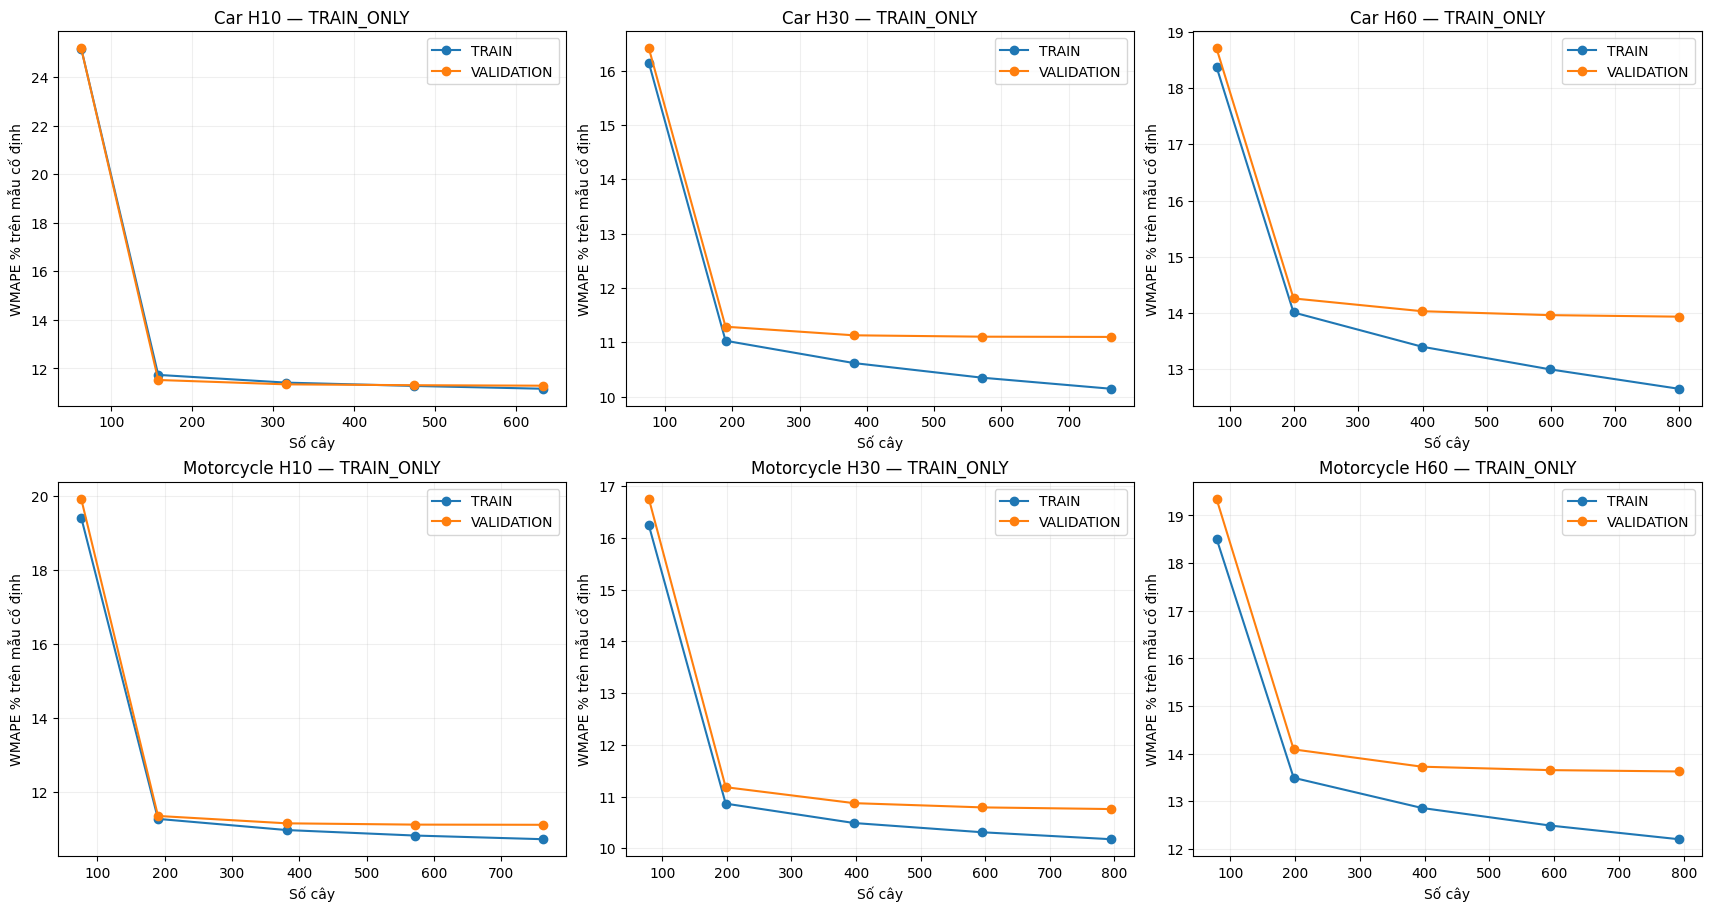

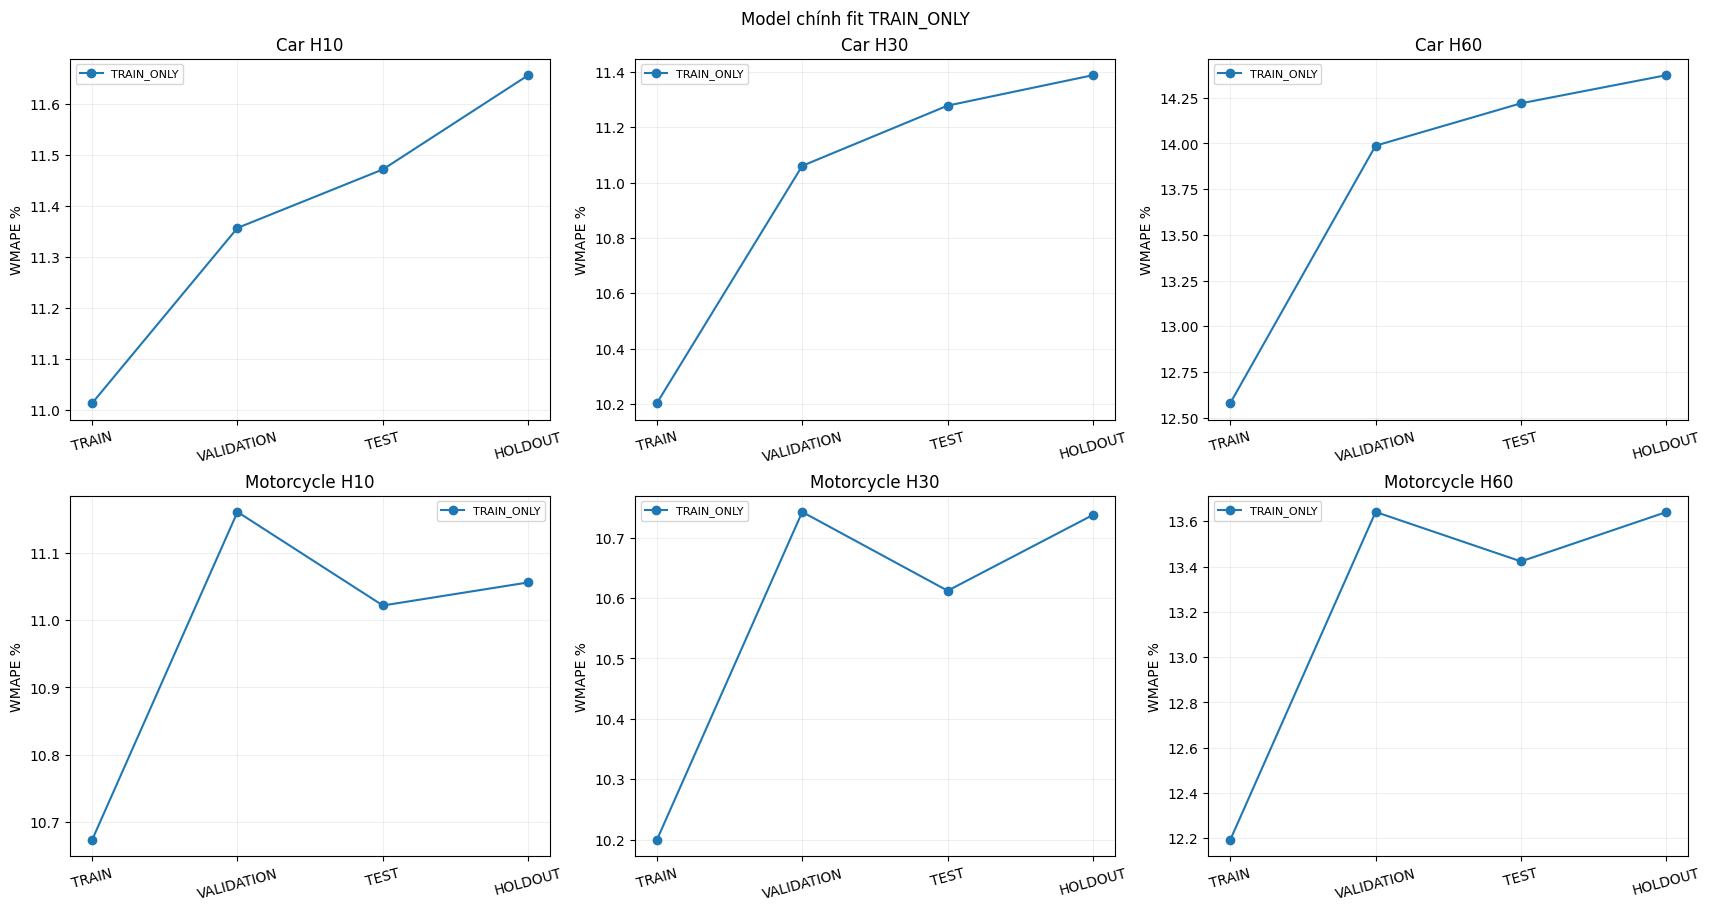

In [24]:
DA_GAP_ROWS=[]
for (mode,horizon,role),g in DA_METRICS.groupby(['mode','horizon','model_role'],observed=True):
    train=g.loc[g.split=='TRAIN'].iloc[0]
    for split in ['VALIDATION','TEST','HOLDOUT']:
        row=g.loc[g.split==split].iloc[0]
        gap=row.WMAPE_pct-train.WMAPE_pct
        ratio=row.WMAPE_pct/train.WMAPE_pct if train.WMAPE_pct>0 else np.nan
        warn=(gap>=DA_GAP_PP) and (ratio>=DA_GAP_RATIO if np.isfinite(ratio) else gap>0)
        status=('IN_SAMPLE_DO_NOT_USE_FOR_GENERALIZATION' if row.fit_overlap
                else 'LARGE_GAP_CHECK_OVERFIT_AND_DRIFT' if warn else 'NO_LARGE_GAP_AT_CONFIGURED_THRESHOLD')
        DA_GAP_ROWS.append(dict(mode=mode,horizon=horizon,model_role=role,split=split,
            train_WMAPE_pct=train.WMAPE_pct,eval_WMAPE_pct=row.WMAPE_pct,gap_pp=gap,ratio=ratio,
            train_mean=train.actual_mean,eval_mean=row.actual_mean,
            actual_mean_shift_pct=100*(row.actual_mean/train.actual_mean-1) if train.actual_mean>0 else np.nan,
            status=status,holdout_status=DA_HOLDOUT_STATUS if split=='HOLDOUT' else ''))
DA_GAPS=da_table('generalization_gaps',pd.DataFrame(DA_GAP_ROWS))
# Chuẩn hóa thành phần thứ-giờ: dùng cùng các ô và trọng số actual TRAIN.
# WMAPE sau chuẩn hóa là chỉ số chẩn đoán, không thay WMAPE toàn tập.
_std=[]
for (mode,horizon,role),g in DA_GROUPS.query('grain == "weekday_hour"').groupby(['mode','horizon','model_role'],observed=True):
    eligible=g.loc[(g.actual_sum>0)&(g.rows>=DA_MIN_GROUP_ROWS)].copy()
    w=eligible.pivot(index=['weekday','hour'],columns='split',values='WMAPE_pct').reindex(columns=DA_SPLITS).dropna()
    train=eligible.query('split == "TRAIN"').set_index(['weekday','hour'])
    weights=train.actual_sum.reindex(w.index)
    if len(w)==0 or weights.sum()<=0:continue
    weights=weights/weights.sum()
    for split in DA_SPLITS:
        _std.append(dict(mode=mode,horizon=horizon,model_role=role,split=split,common_weekday_hour_cells=len(w),
                         WMAPE_standardized_pct=np.sum(w[split]*weights),
                         train_actual_coverage_pct=100*train.actual_sum.reindex(w.index).sum()/train.actual_sum.sum()))
DA_STANDARDIZED=da_table('standardized_weekday_hour_WMAPE',pd.DataFrame(_std))
_curve_summary=[]
for (mode,horizon),g in DA_CURVES.groupby(['mode','horizon'],observed=True):
    tr=g.query('split == "TRAIN"').sort_values('iteration')
    va=g.query('split == "VALIDATION"').sort_values('iteration')
    best=va.loc[va.WMAPE_pct.idxmin()];last=va.iloc[-1]
    tr_at_best=tr.loc[tr.iteration==best.iteration].iloc[0]
    val_rise=last.WMAPE_pct-best.WMAPE_pct
    train_drop=tr_at_best.WMAPE_pct-tr.iloc[-1].WMAPE_pct
    _curve_summary.append(dict(mode=mode,horizon=horizon,sampled_rows_train=int(tr.iloc[0].rows),
        sampled_rows_validation=int(va.iloc[0].rows),best_checkpoint=int(best.iteration),last_iteration=int(last.iteration),
        val_WMAPE_best=best.WMAPE_pct,val_WMAPE_last=last.WMAPE_pct,val_increase_from_best_pp=val_rise,
        train_decrease_after_best_pp=train_drop,
        late_tree_overfit_signal=bool(val_rise>=.5 and train_drop>=.5),
        note='Chỉ các checkpoint đã đo; không chọn lại model theo audit này.'))
DA_CURVE_SUMMARY=da_table('tree_overfit_signals',pd.DataFrame(_curve_summary))
display(DA_GAPS.round(3));display(DA_CURVE_SUMMARY.round(3));display(DA_STANDARDIZED.round(3))
print('Gap TRAIN→VAL/TEST/HOLDOUT là dấu hiệu cần điều tra, không tự chứng minh overfit: có thể có drift, thay thành phần hex/giờ và nhiễu.')
print('Không có gap lớn cũng KHÔNG chứng minh không overfit. HOLDOUT gồm 14 ngày giả lập mới cùng cơ chế sinh; không chứng minh tổng quát hóa trên dữ liệu thực.')
fig,axes=plt.subplots(2,3,figsize=(17,9),constrained_layout=True)
for r,mode in enumerate(DA_MODES):
    for c,horizon in enumerate(DA_HORIZONS):
        ax=axes[r,c]
        for split in ['TRAIN','VALIDATION']:
            z=DA_CURVES.query('mode == @mode and horizon == @horizon and split == @split').sort_values('iteration')
            ax.plot(z.iteration,z.WMAPE_pct,marker='o',label=split)
        ax.set(title=f'{mode} H{horizon} — TRAIN_ONLY',xlabel='Số cây',ylabel='WMAPE % trên mẫu cố định');ax.legend();ax.grid(alpha=.2)
da_figure('tree_learning_curves',fig)
fig,axes=plt.subplots(2,3,figsize=(17,9),constrained_layout=True)
for r,mode in enumerate(DA_MODES):
    for c,horizon in enumerate(DA_HORIZONS):
        ax=axes[r,c]
        for role in ['TRAIN_ONLY']:
            z=DA_METRICS.query('mode == @mode and horizon == @horizon and model_role == @role').set_index('split').reindex(DA_SPLITS)
            ax.plot(range(4),z.WMAPE_pct,marker='o',label=role)
        ax.set(title=f'{mode} H{horizon}',ylabel='WMAPE %');ax.set_xticks(range(4),DA_SPLITS,rotation=15);ax.legend(fontsize=8);ax.grid(alpha=.2)
fig.suptitle('Model chính fit TRAIN_ONLY')
da_figure('split_WMAPE',fig)


### Audit 08

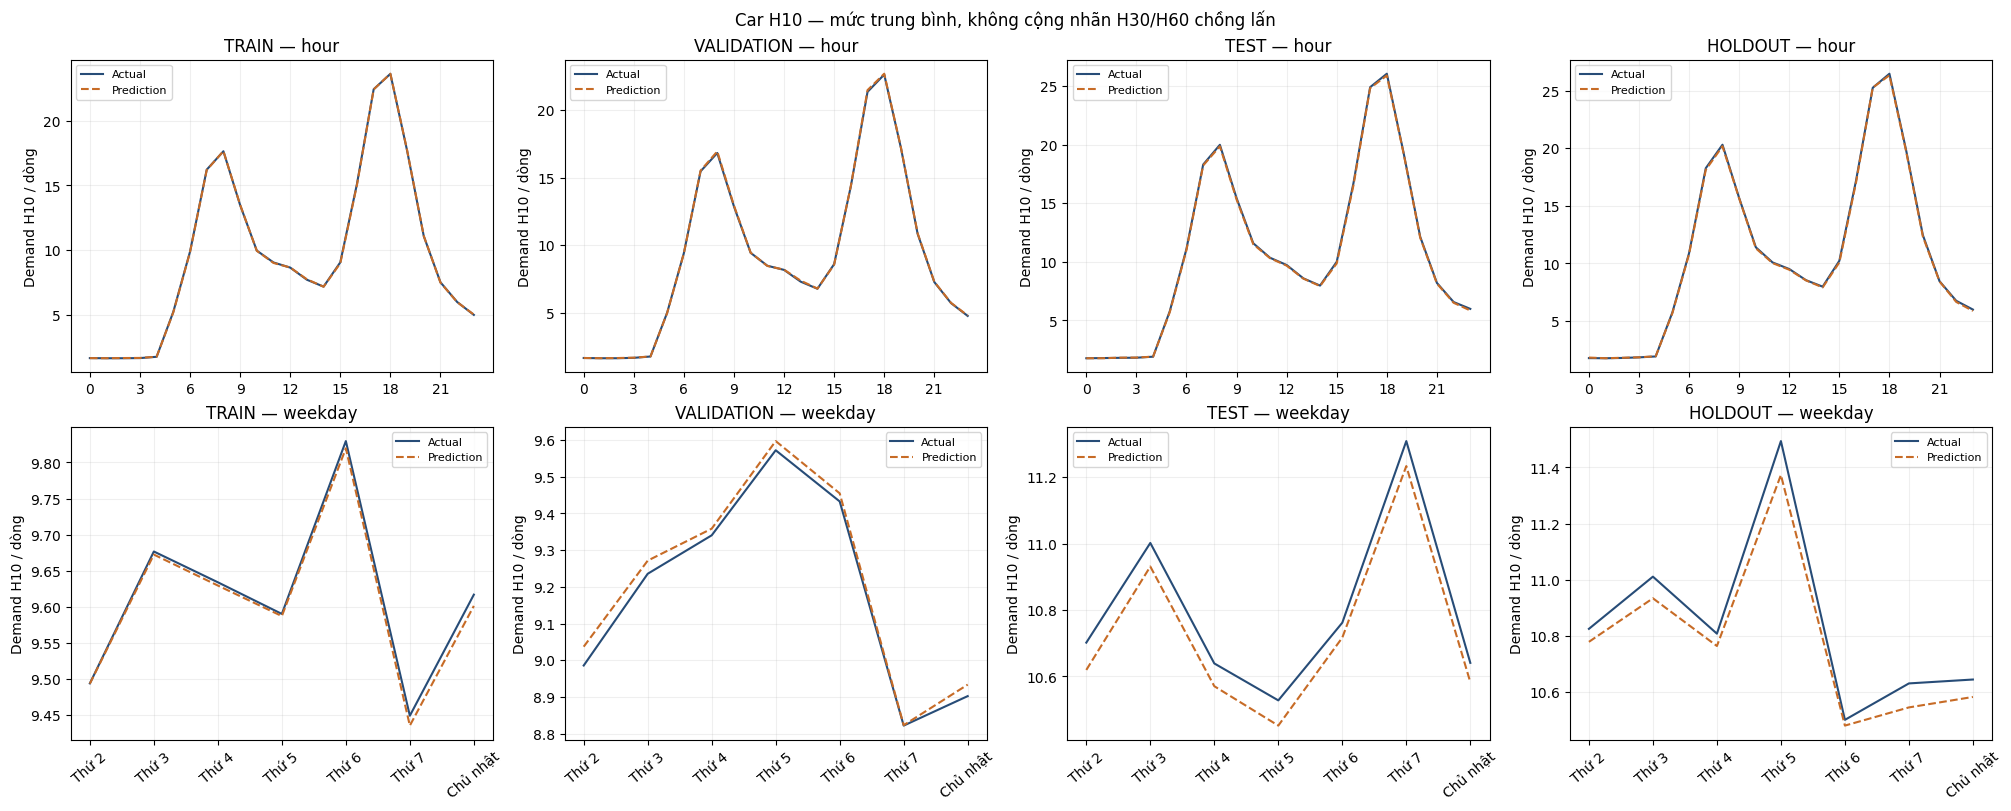

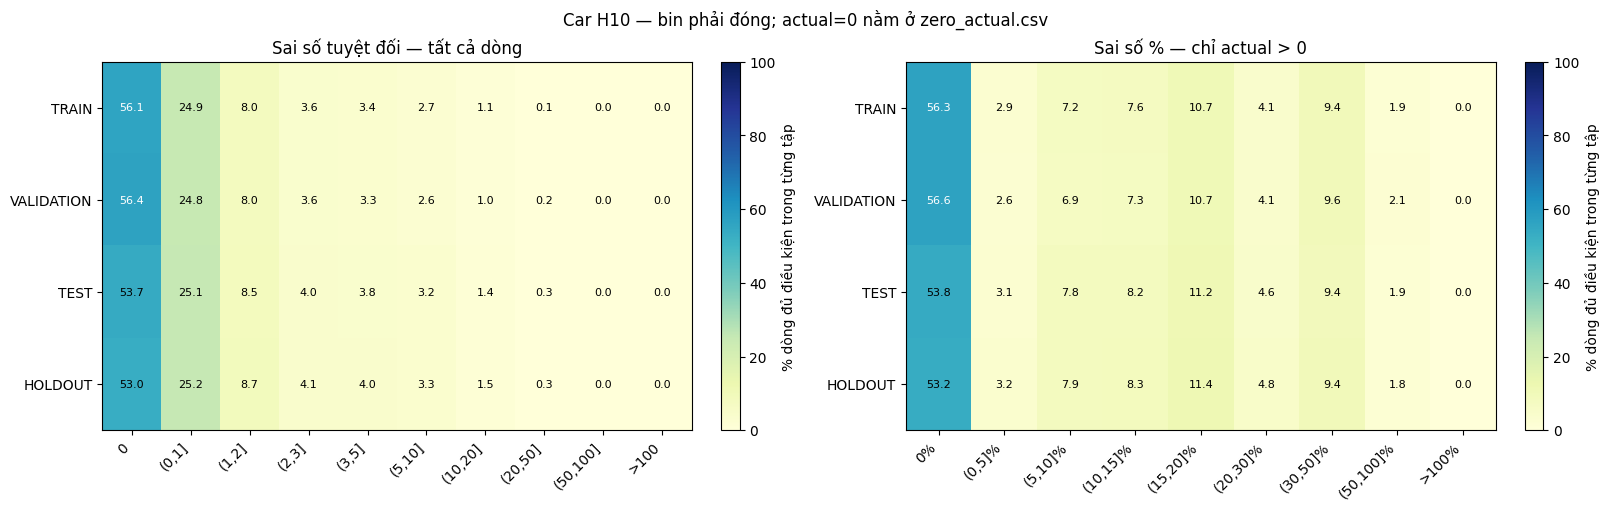

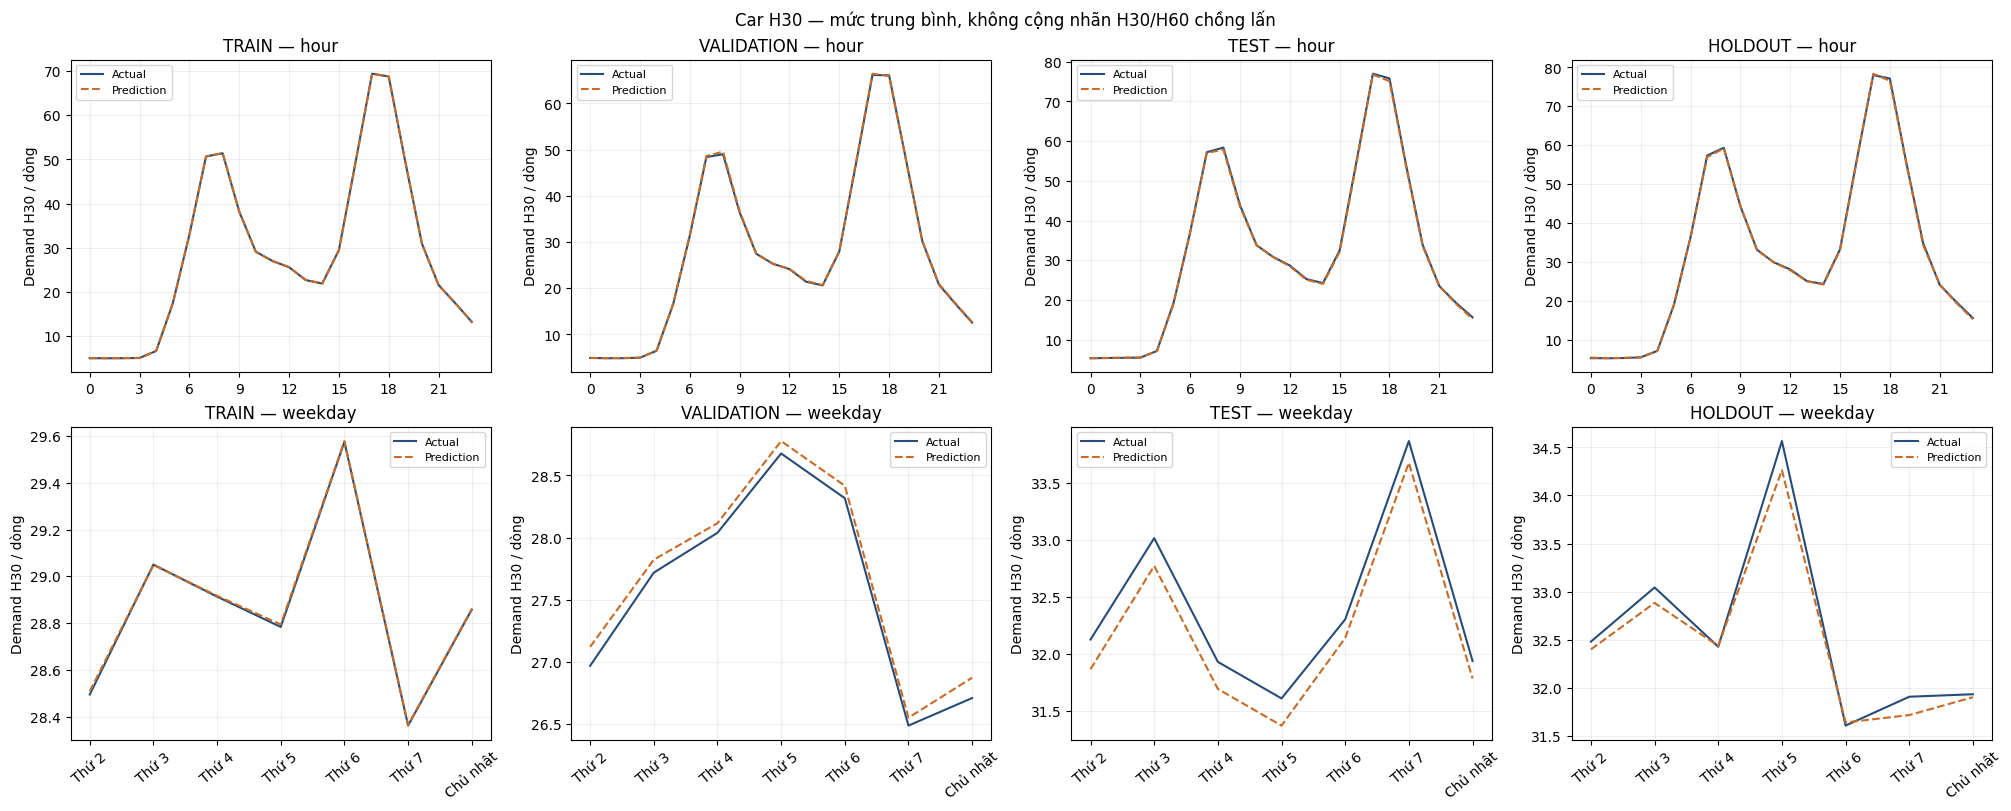

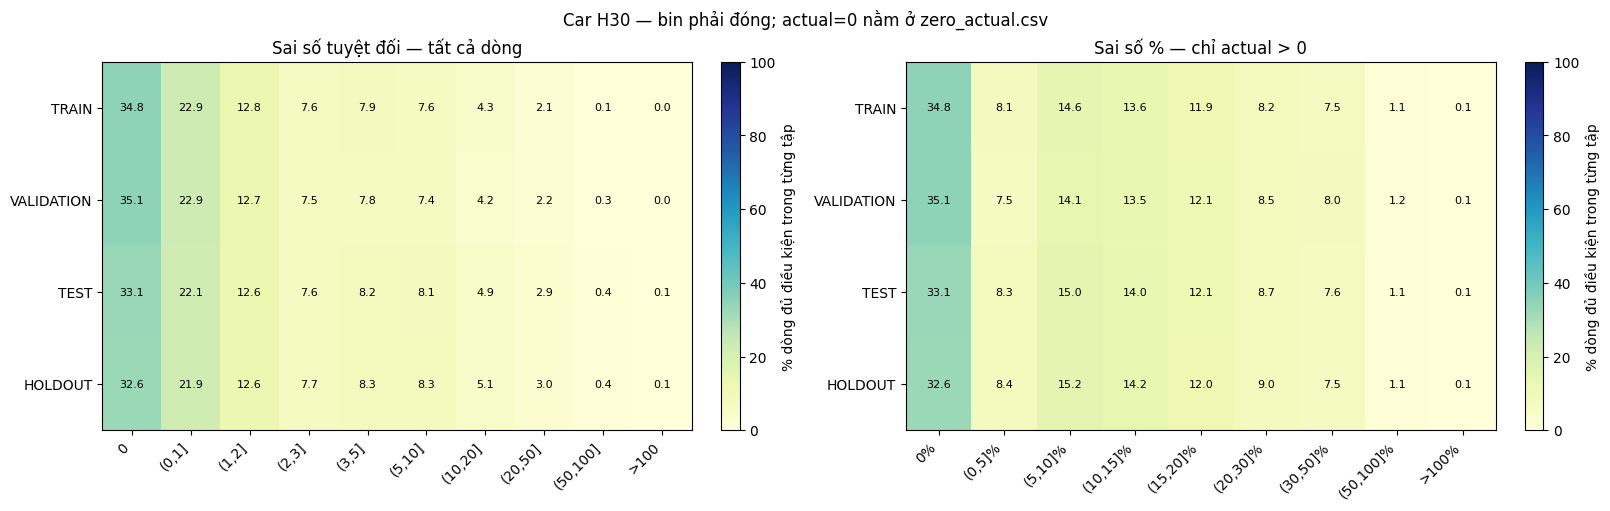

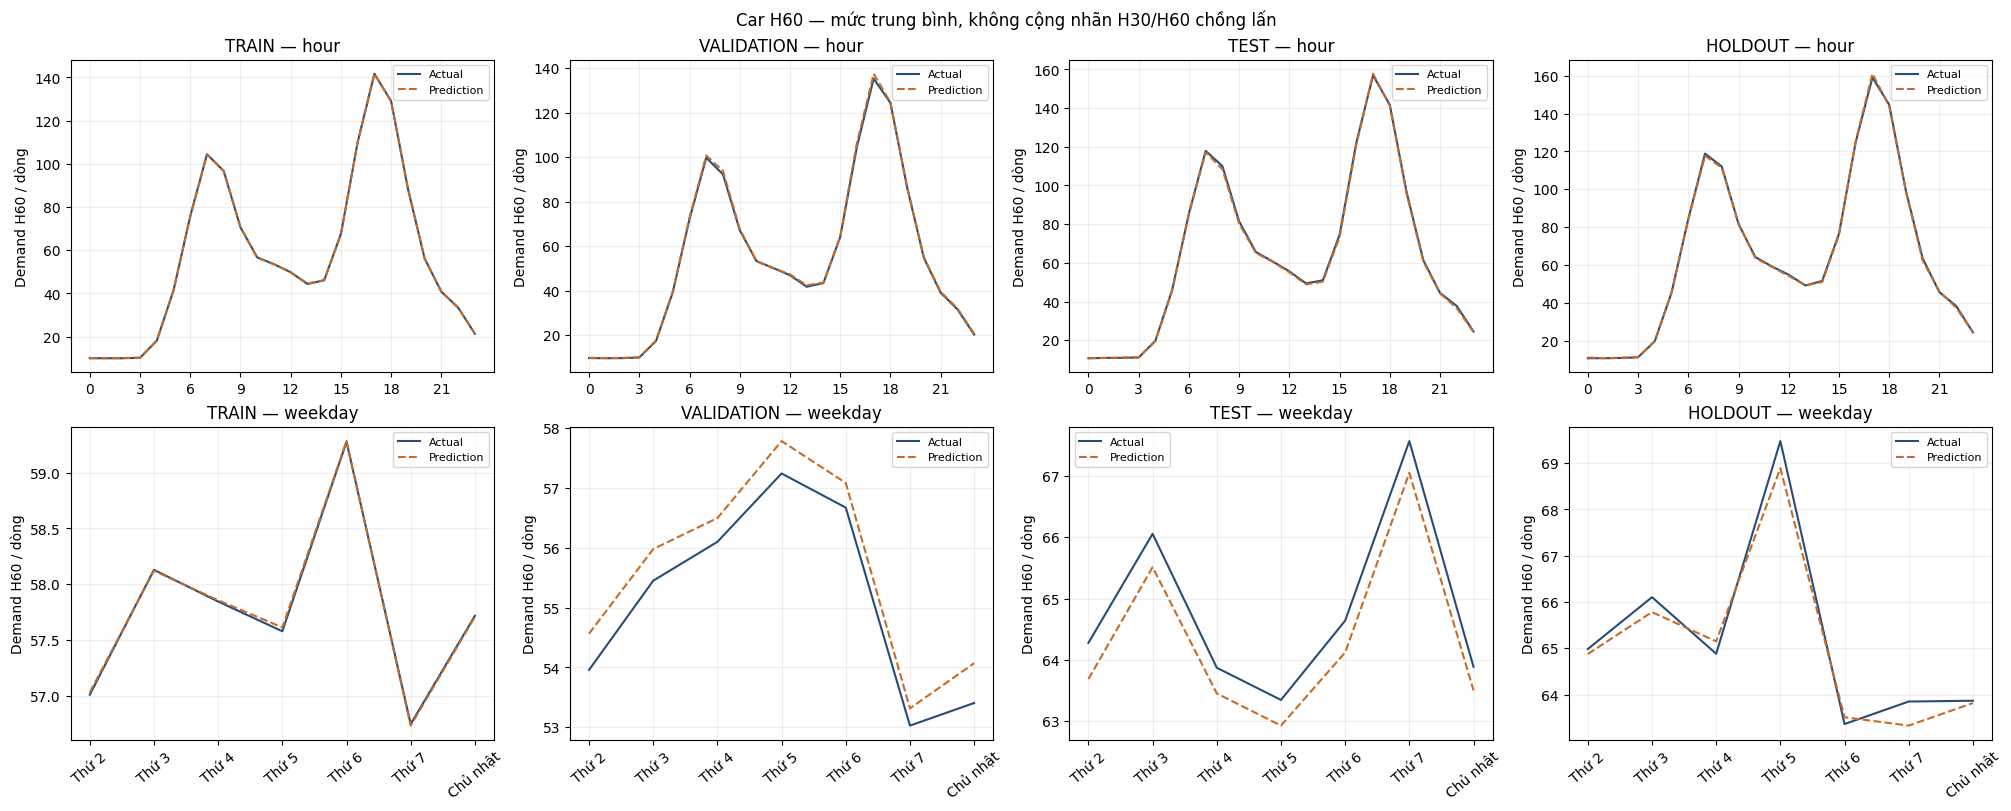

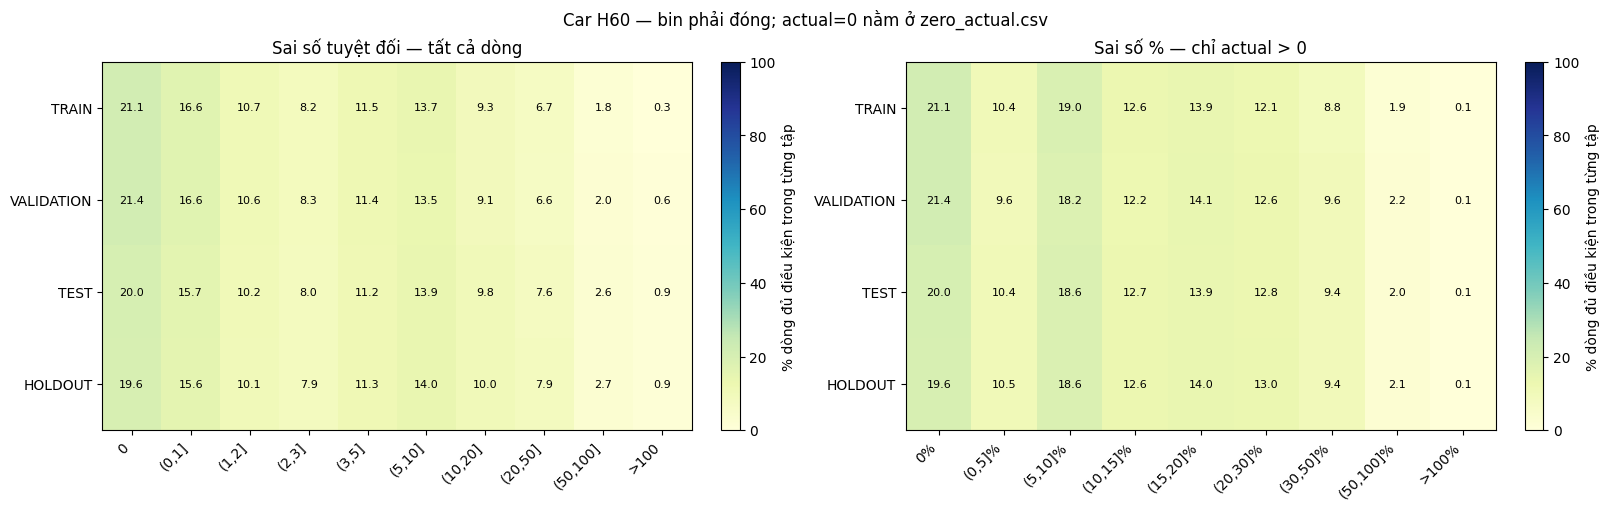

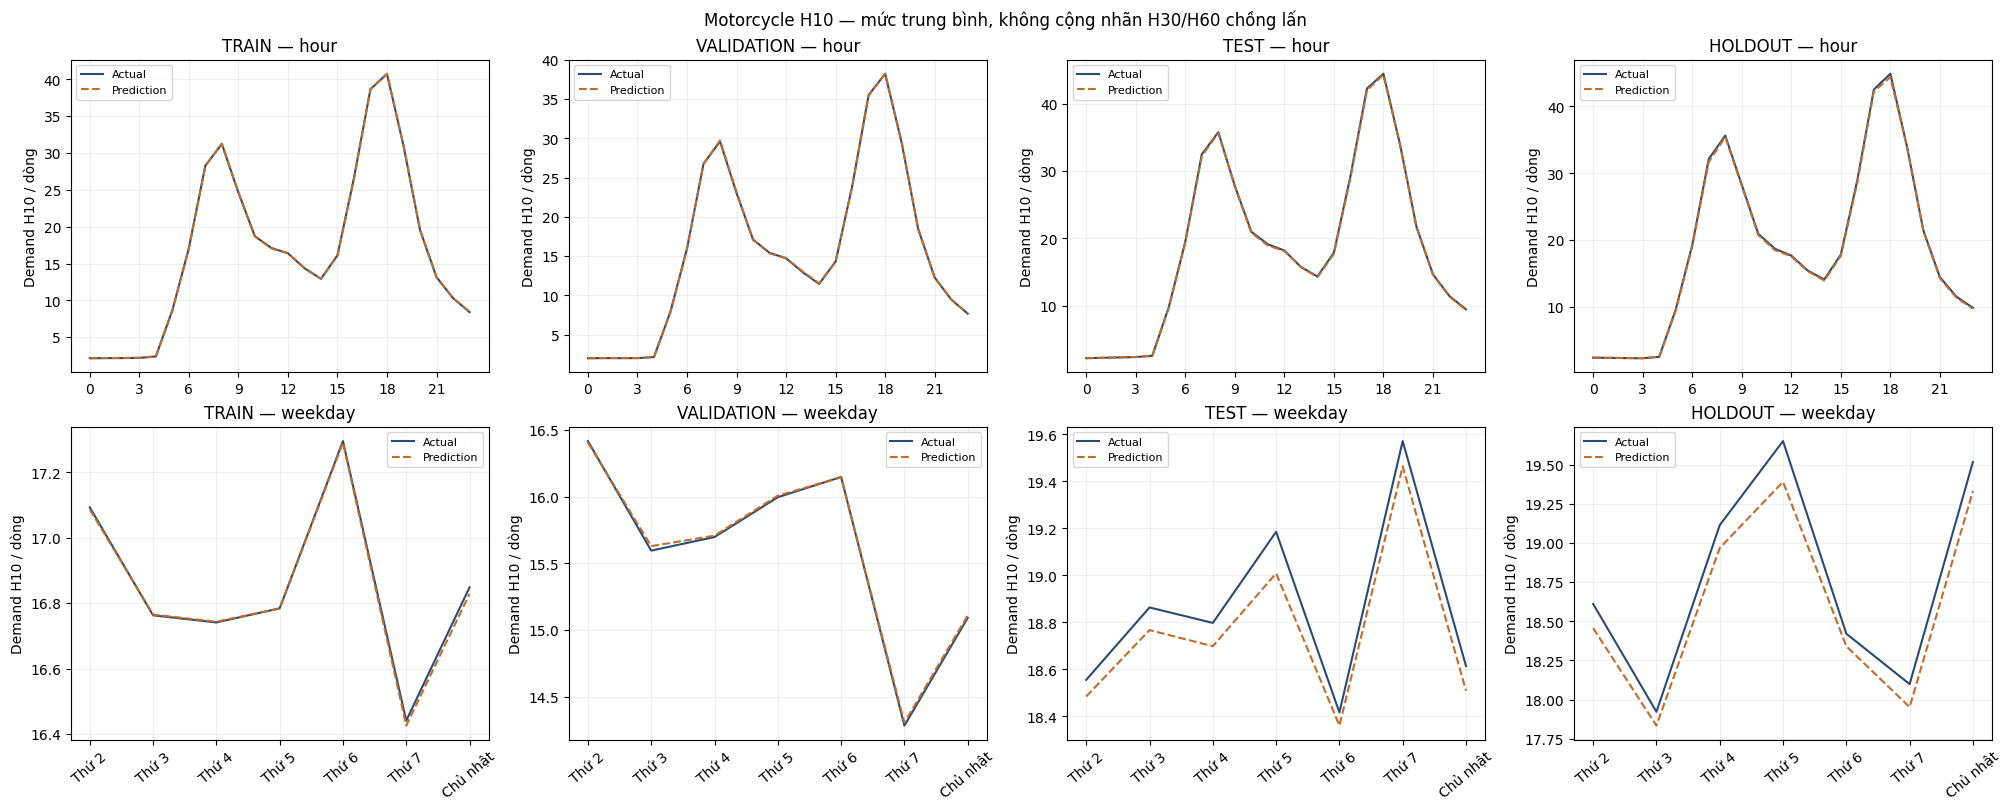

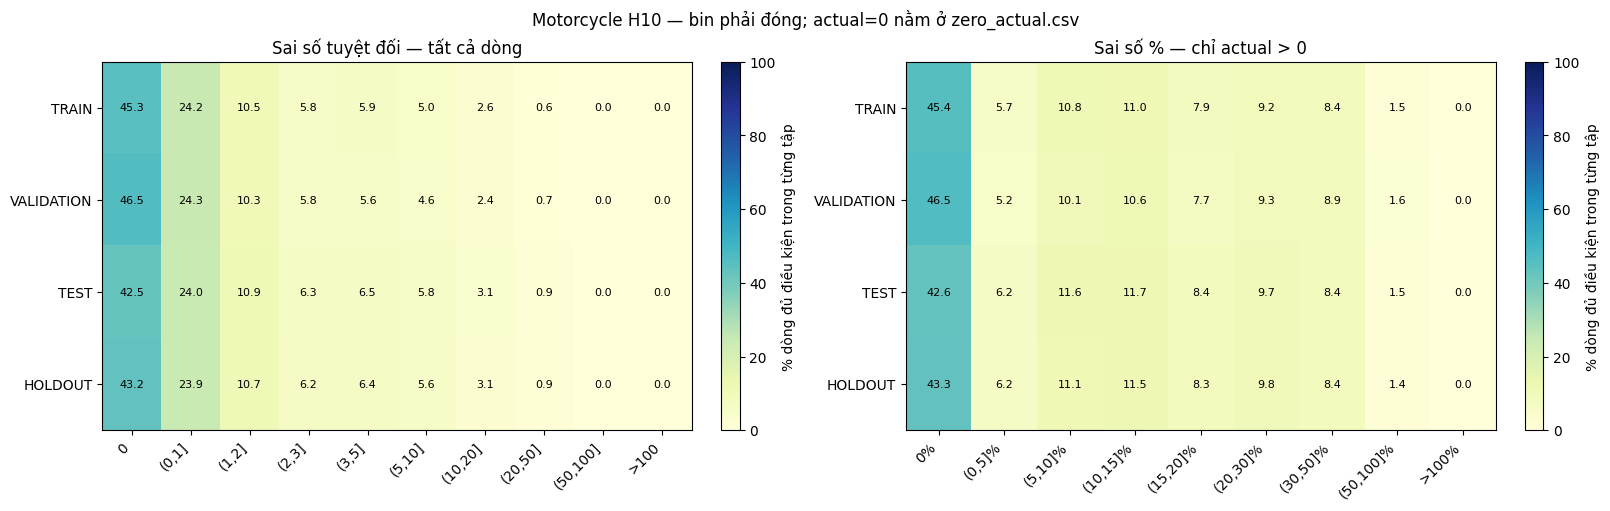

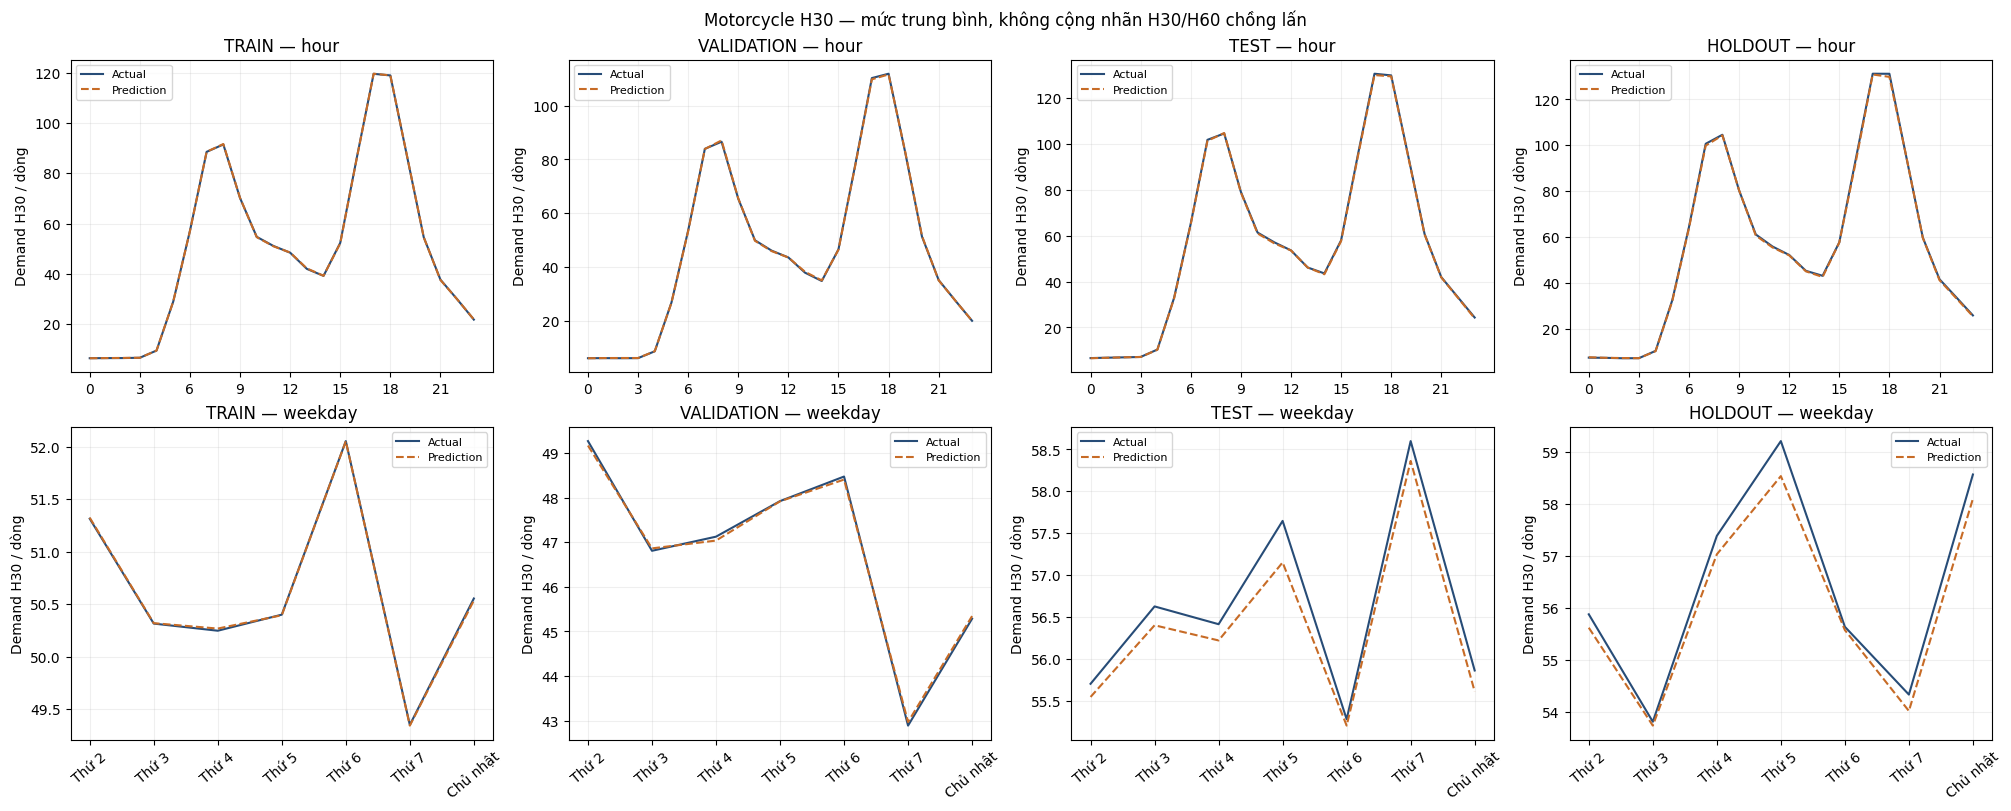

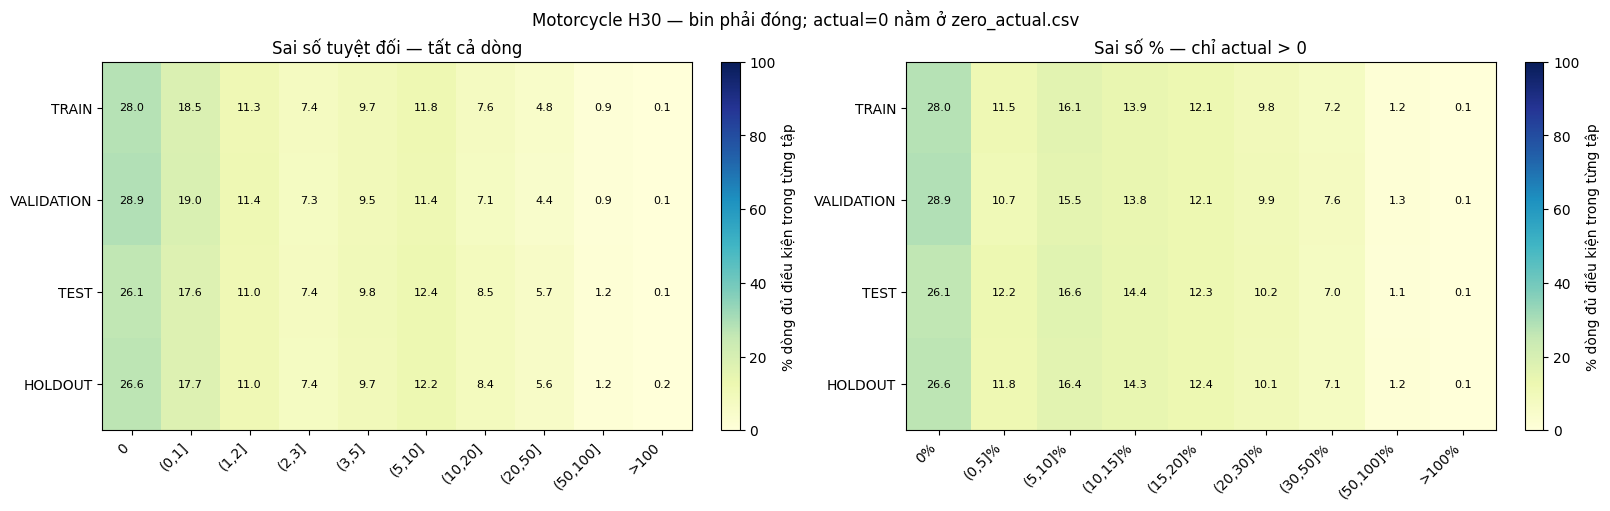

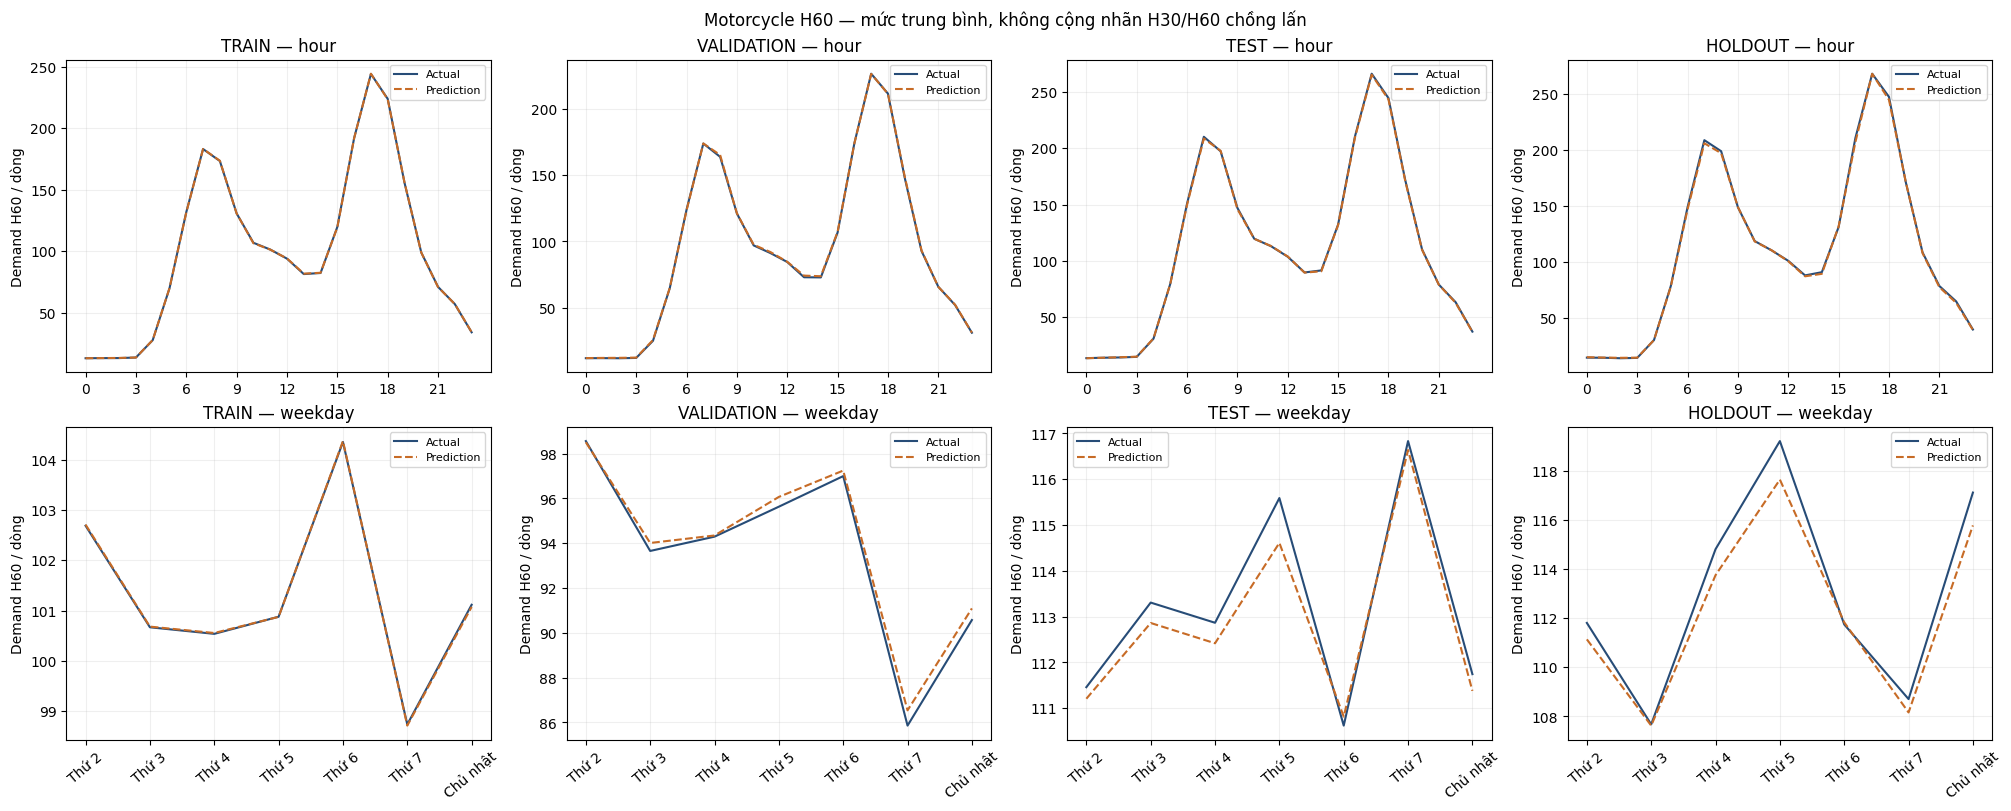

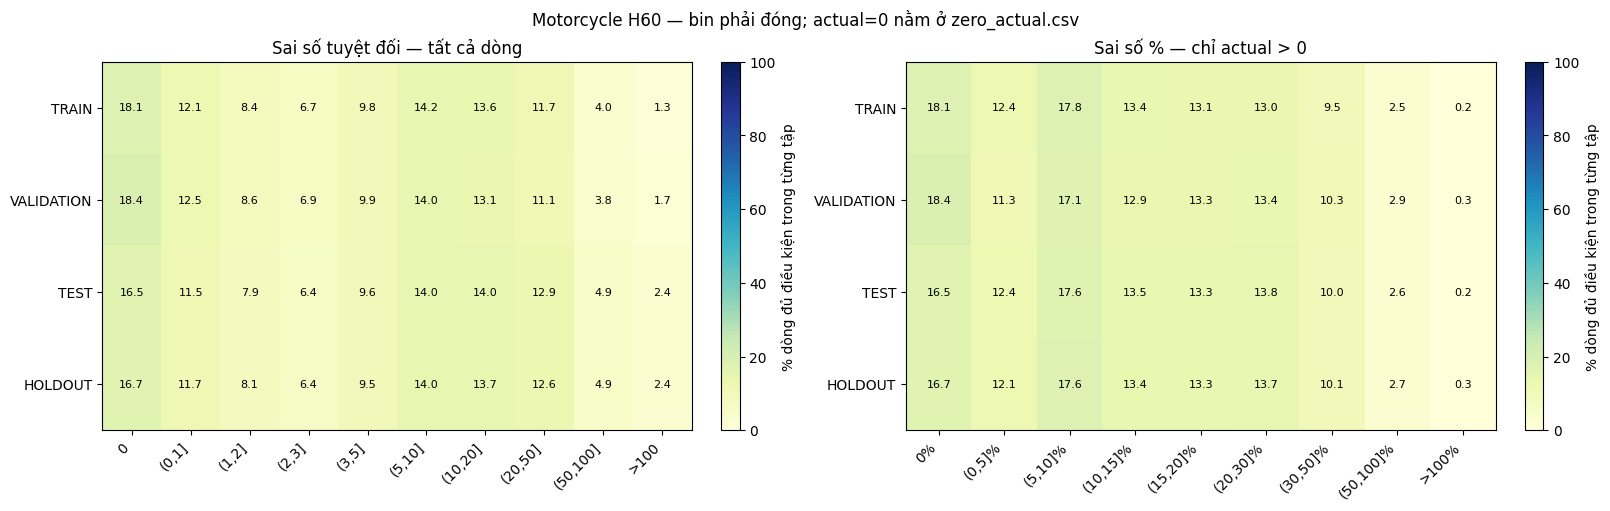

,mode,horizon,model_role,split,rows,all_rows_pct,correct_zero_rows,false_positive_rows,prediction_sum,abs_error_sum,error_share_all_pct,WMAPE_contribution_all_pp,note
0,Car,10,TRAIN_ONLY,TRAIN,4905,0.297,0,4905,5505.0,5505.0,0.315,0.035,APE không xác định khi actual=0; không đặt bằn...
1,Car,10,TRAIN_ONLY,VALIDATION,2038,0.315,0,2038,2310.0,2310.0,0.342,0.039,APE không xác định khi actual=0; không đặt bằn...
2,Car,10,TRAIN_ONLY,TEST,1633,0.288,0,1633,1832.0,1832.0,0.261,0.030,APE không xác định khi actual=0; không đặt bằn...
3,Car,10,TRAIN_ONLY,HOLDOUT,827,0.282,0,827,932.0,932.0,0.251,0.029,APE không xác định khi actual=0; không đặt bằn...
4,Car,30,TRAIN_ONLY,TRAIN,0,0.000,0,0,0.0,0.0,0.000,0.000,APE không xác định khi actual=0; không đặt bằn...
5,Car,30,TRAIN_ONLY,VALIDATION,0,0.000,0,0,0.0,0.0,0.000,0.000,APE không xác định khi actual=0; không đặt bằn...
6,Car,30,TRAIN_ONLY,TEST,0,0.000,0,0,0.0,0.0,0.000,0.000,APE không xác định khi actual=0; không đặt bằn...
7,Car,30,TRAIN_ONLY,HOLDOUT,0,0.000,0,0,0.0,0.0,0.000,0.000,APE không xác định khi actual=0; không đặt bằn...
8,Car,60,TRAIN_ONLY,TRAIN,0,0.000,0,0,0.0,0.0,0.000,0.000,APE không xác định khi actual=0; không đặt bằn...
9,Car,60,TRAIN_ONLY,VALIDATION,0,0.000,0,0,0.0,0.0,0.000,0.000,APE không xác định khi actual=0; không đặt bằn...


,mode,horizon,split,bin,rows,rows_pct,error_share_all_pct,WMAPE_contribution_all_pp
67,Car,10,TRAIN,0%,6356,5.562,0.000,0.000
68,Car,10,TRAIN,"(0,5]%",25651,22.447,2.822,0.311
69,Car,10,TRAIN,"(5,10]%",29406,25.733,7.726,0.851
70,Car,10,TRAIN,"(10,15]%",20745,18.154,8.987,0.990
71,Car,10,TRAIN,"(15,20]%",15438,13.510,8.523,0.939
...,...,...,...,...,...,...,...,...
1819,Motorcycle,60,HOLDOUT,"(15,20]%",20114,13.732,16.603,2.265
1820,Motorcycle,60,HOLDOUT,"(20,30]%",24035,16.409,24.107,3.288
1821,Motorcycle,60,HOLDOUT,"(30,50]%",14251,9.729,16.389,2.236
1822,Motorcycle,60,HOLDOUT,"(50,100]%",2544,1.737,4.327,0.590


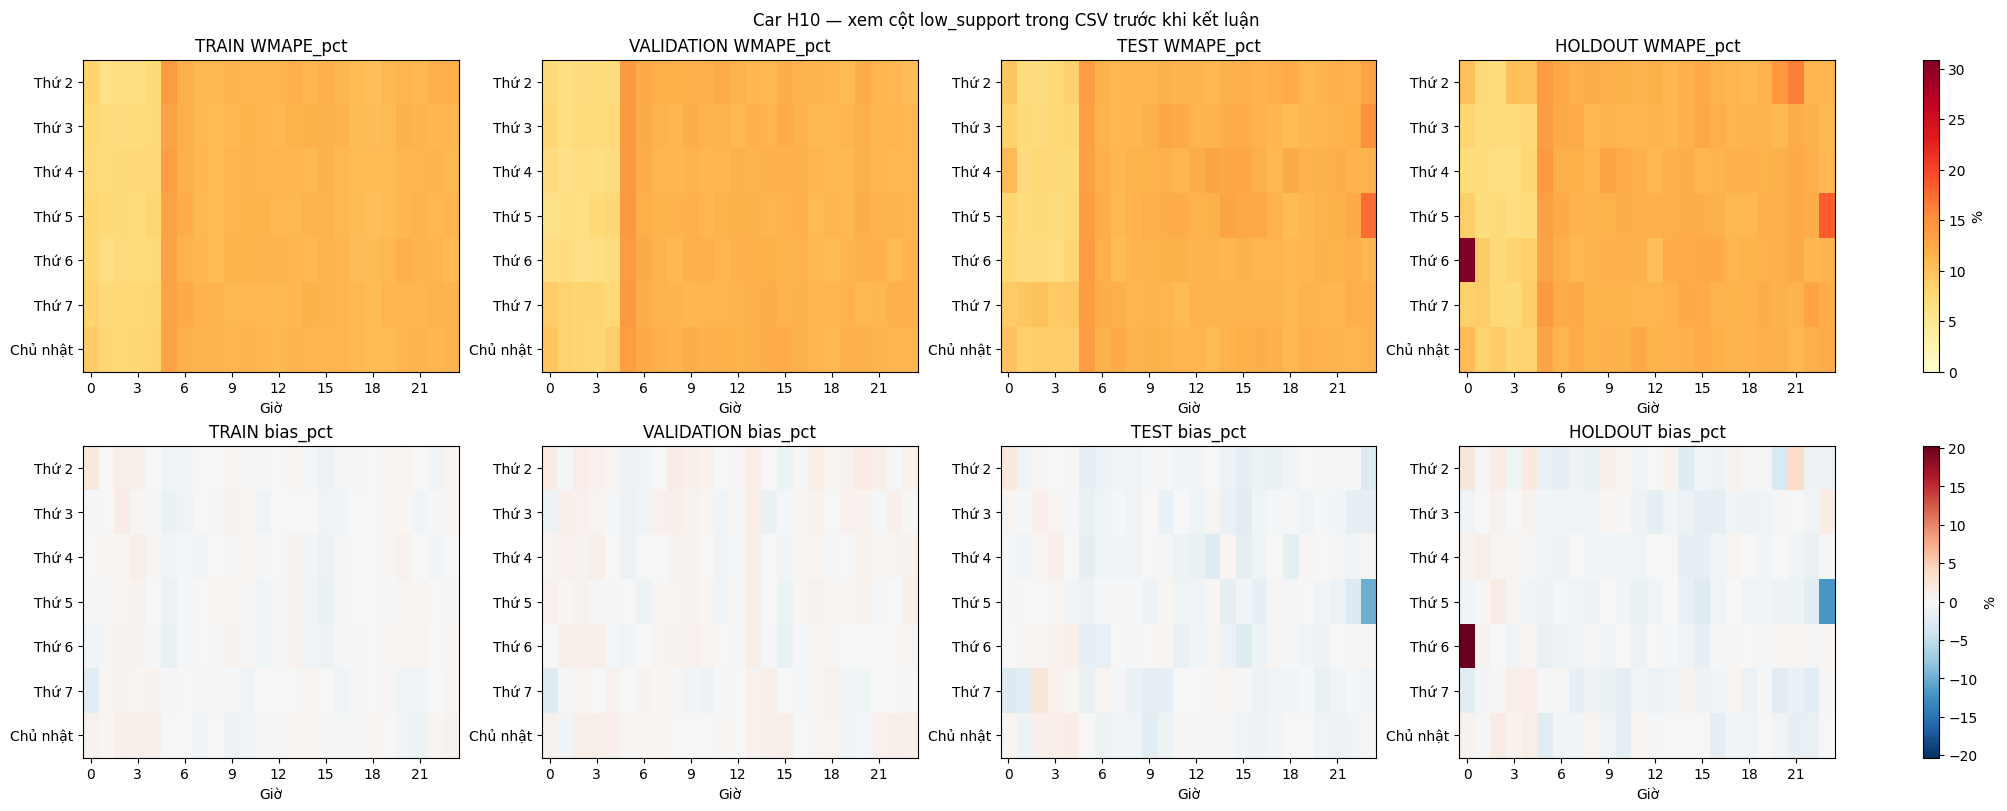

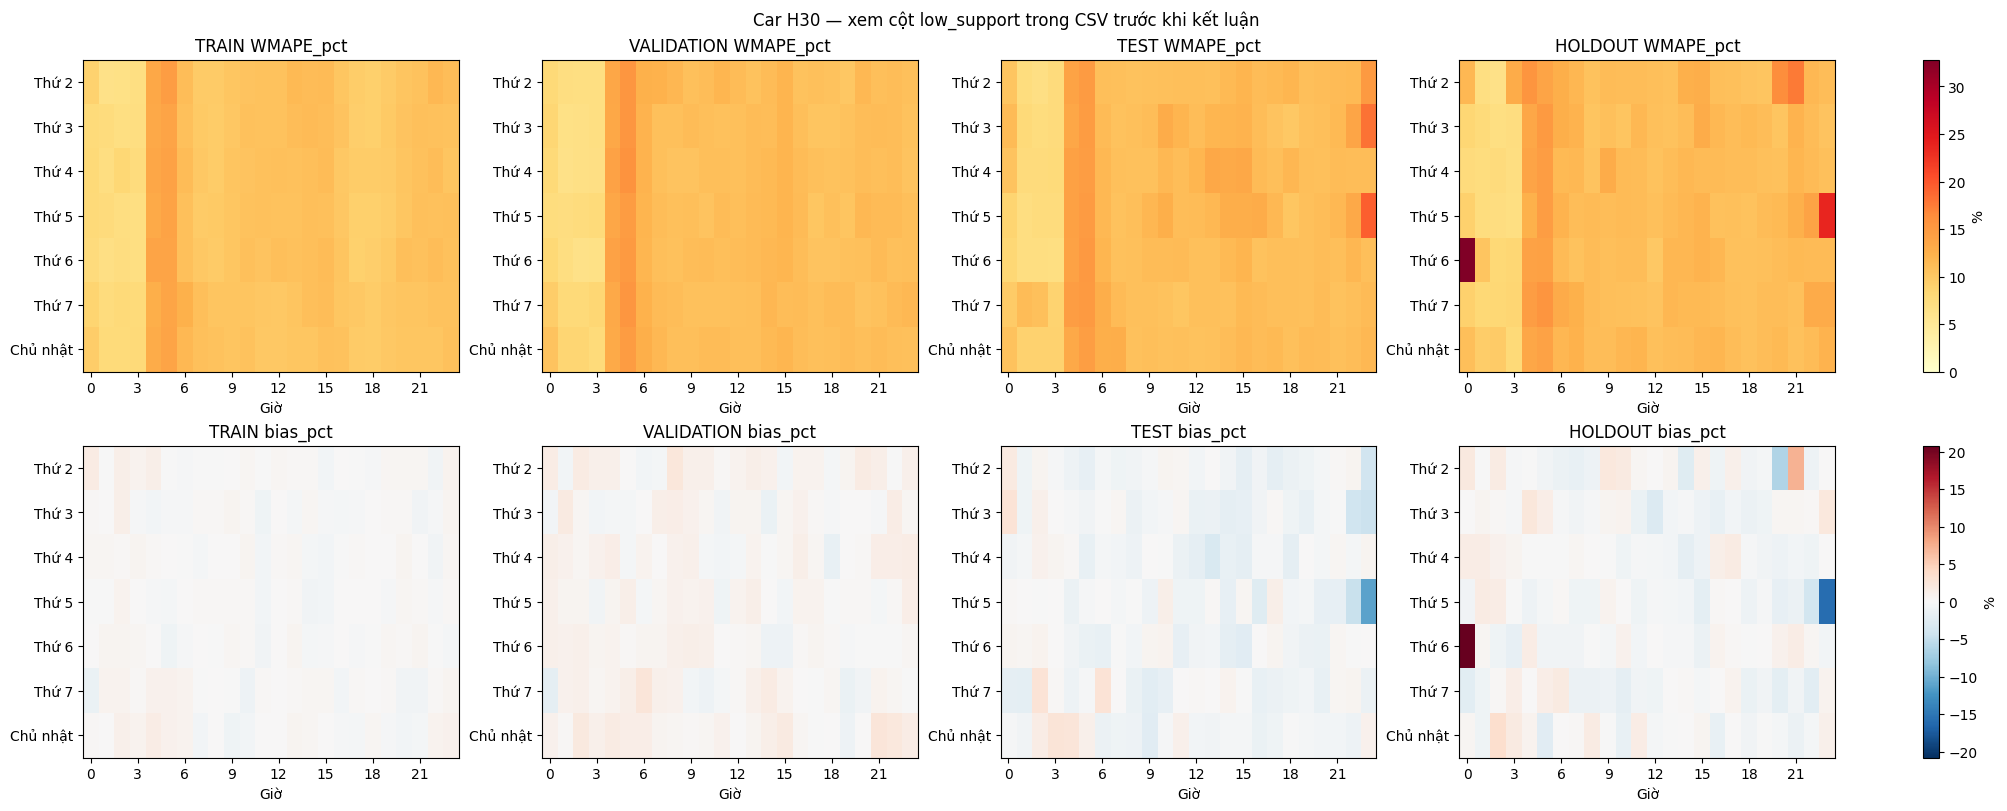

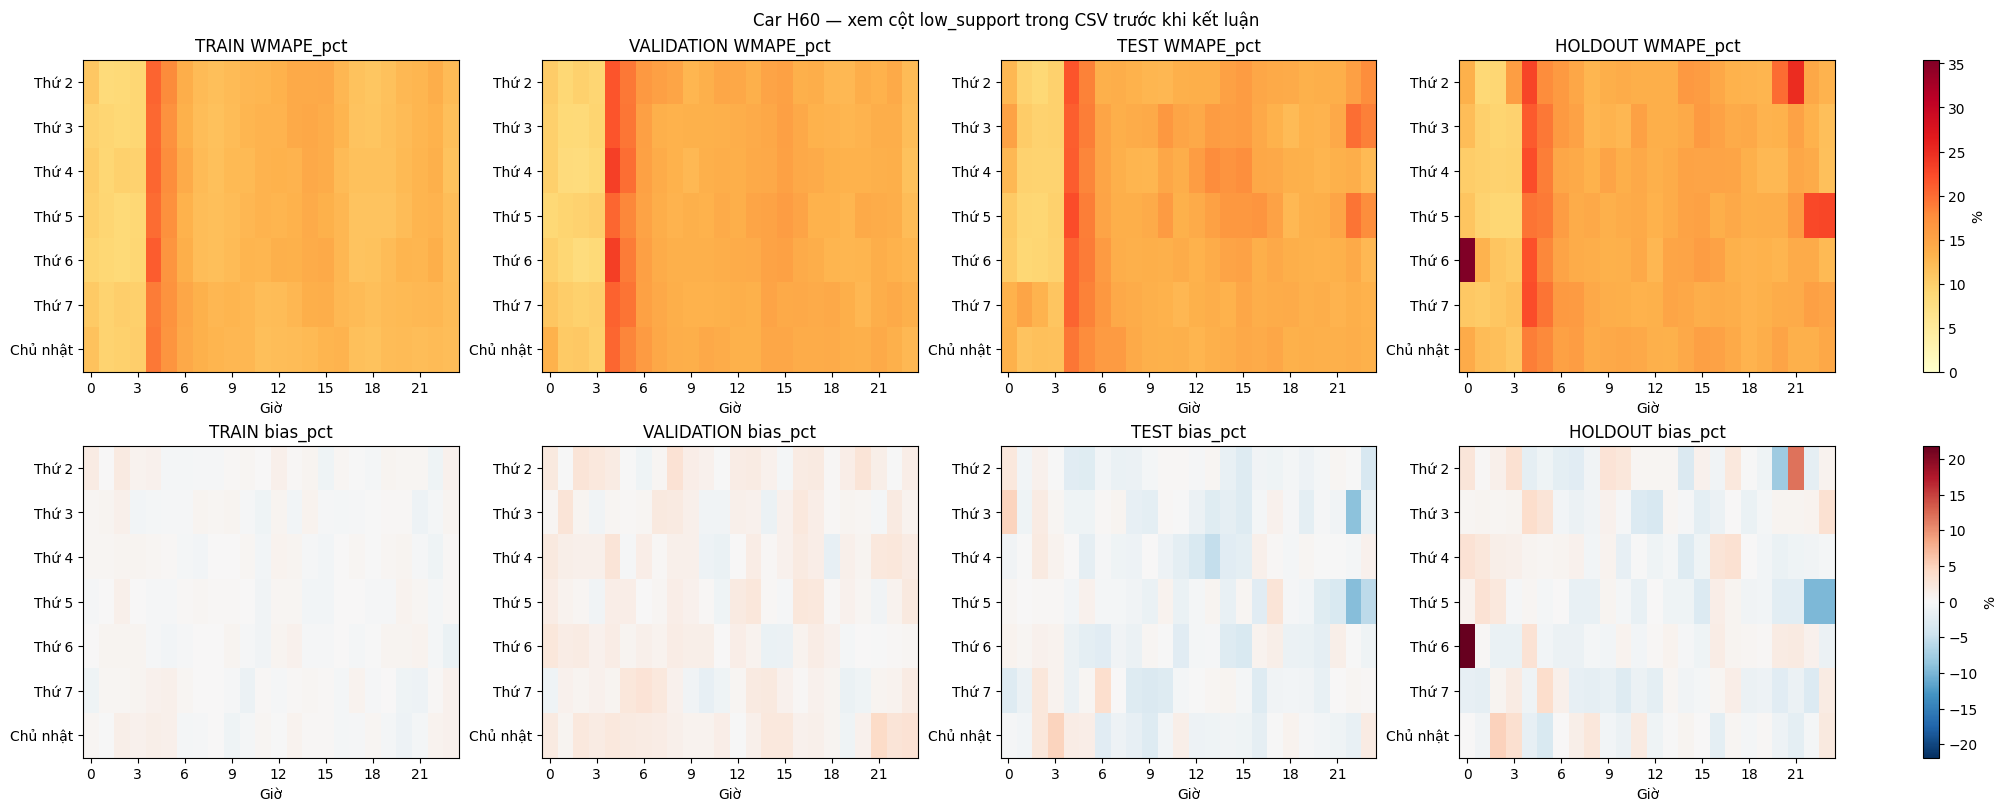

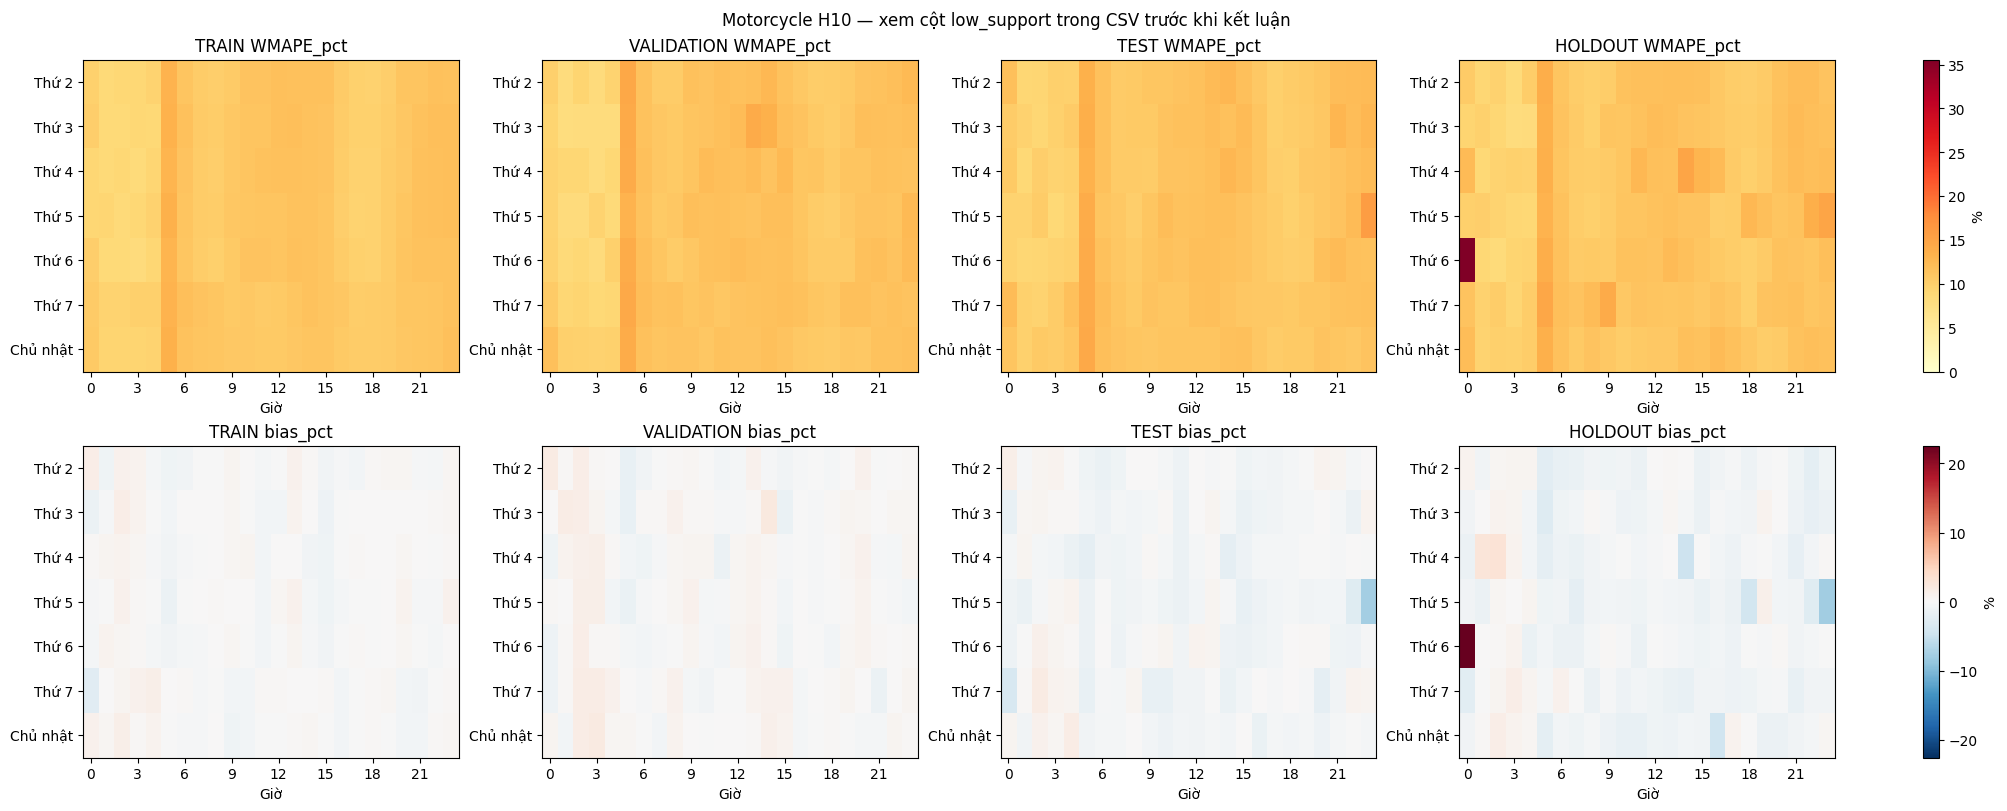

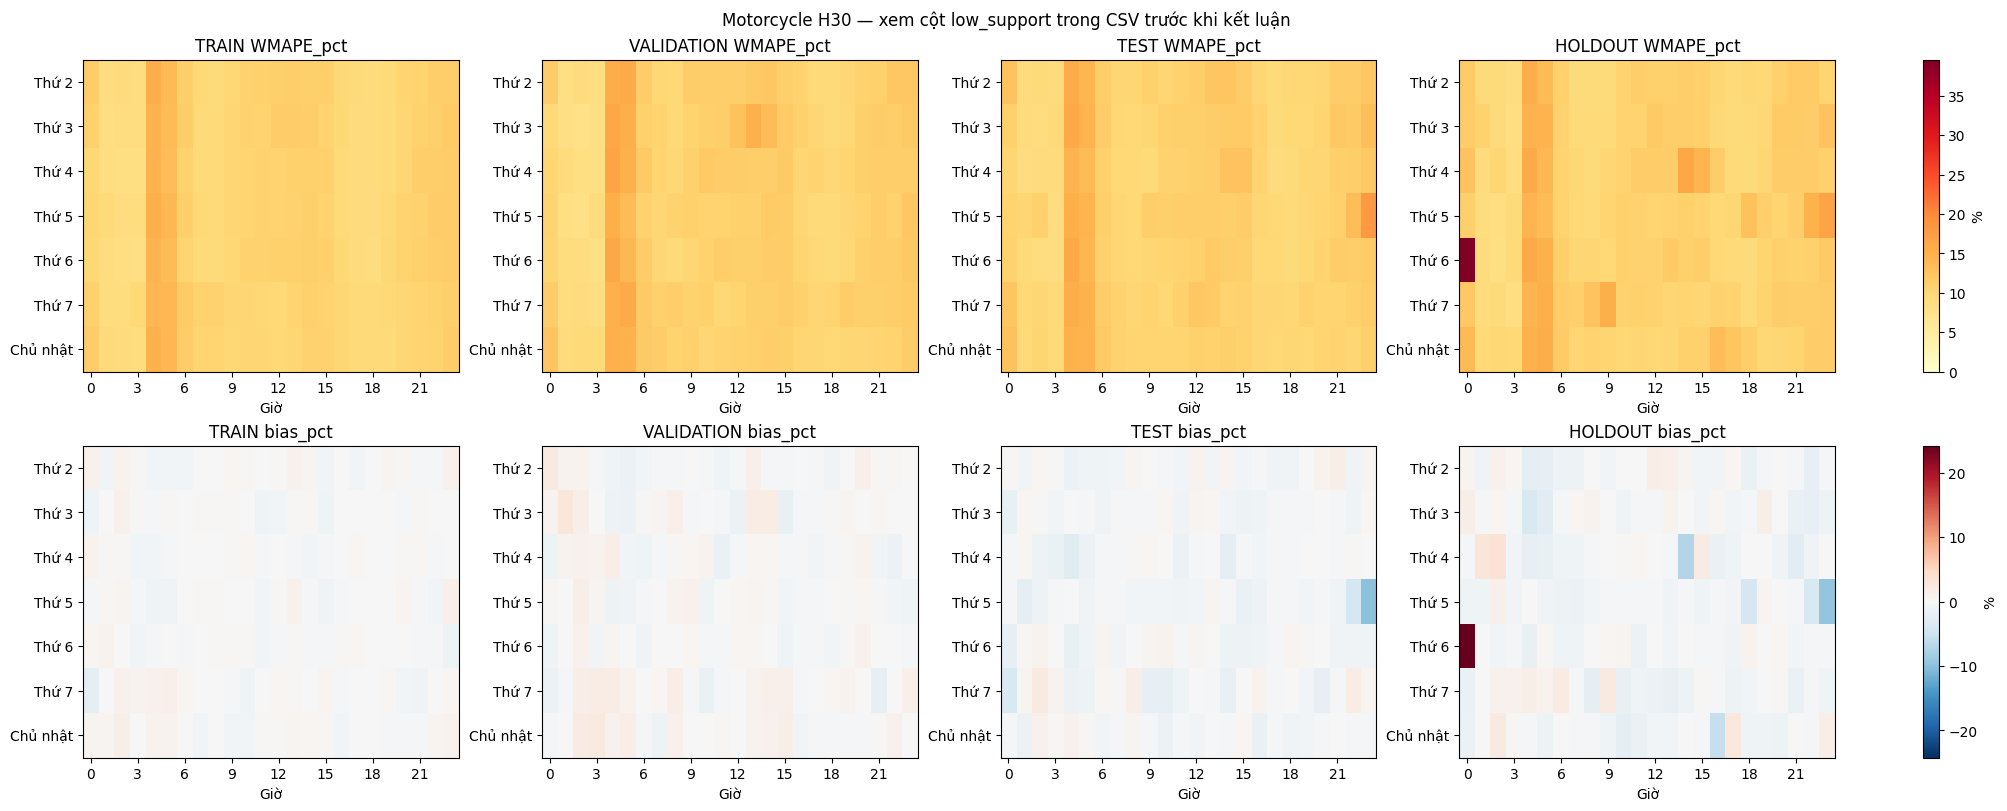

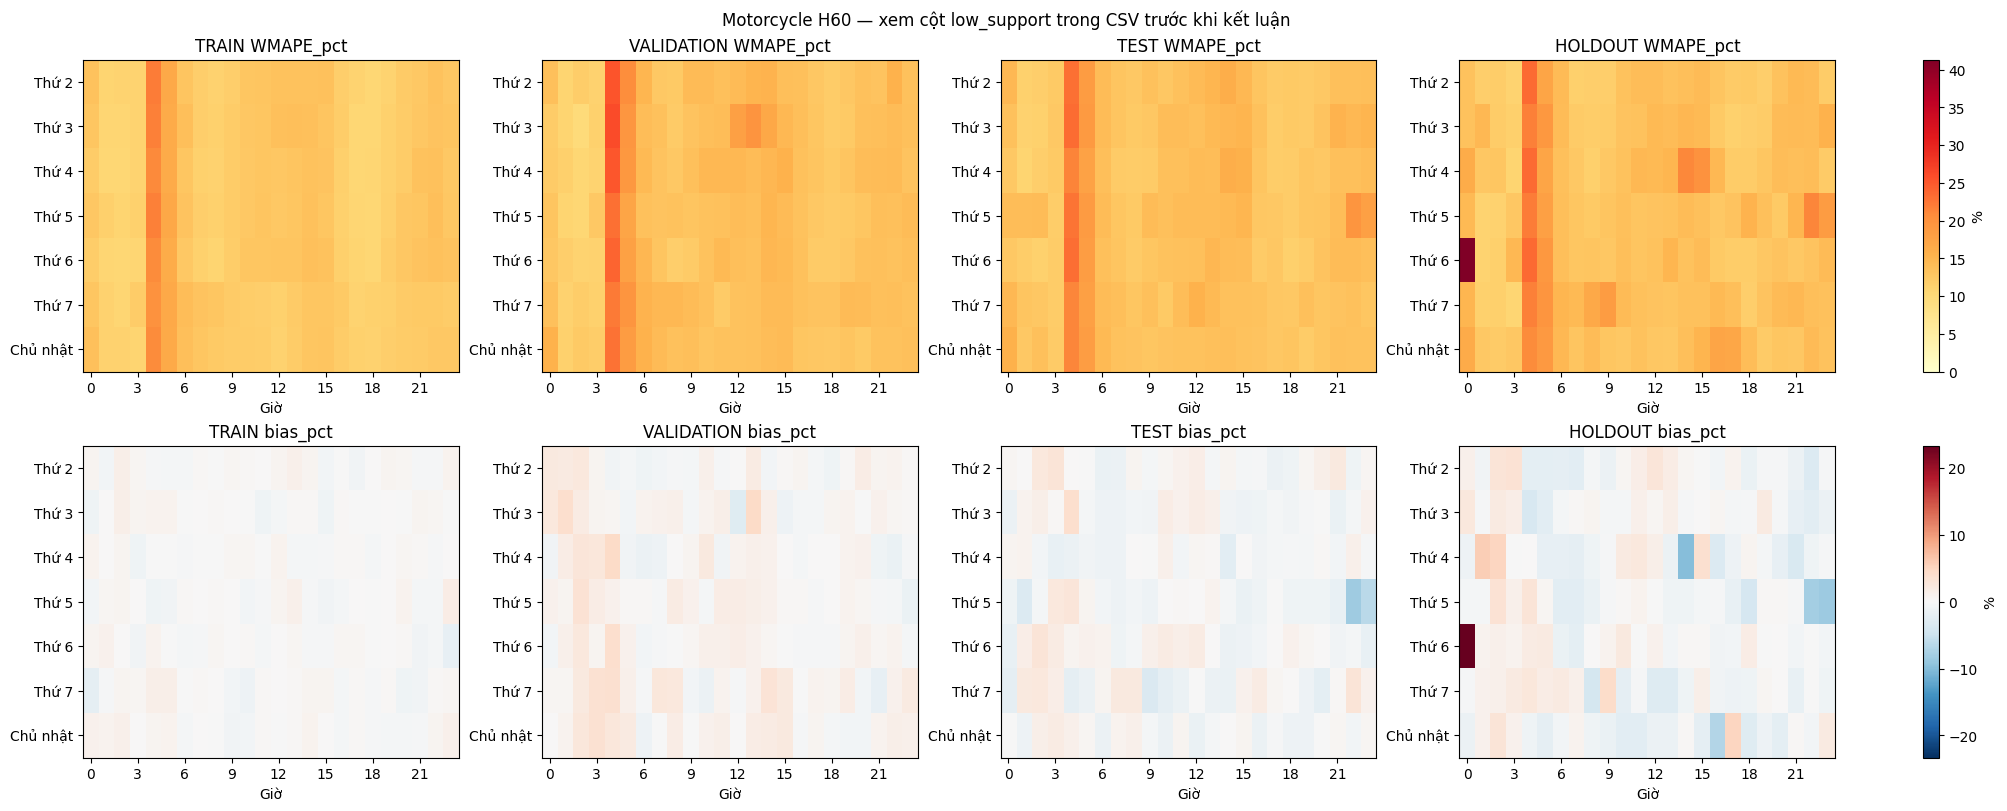

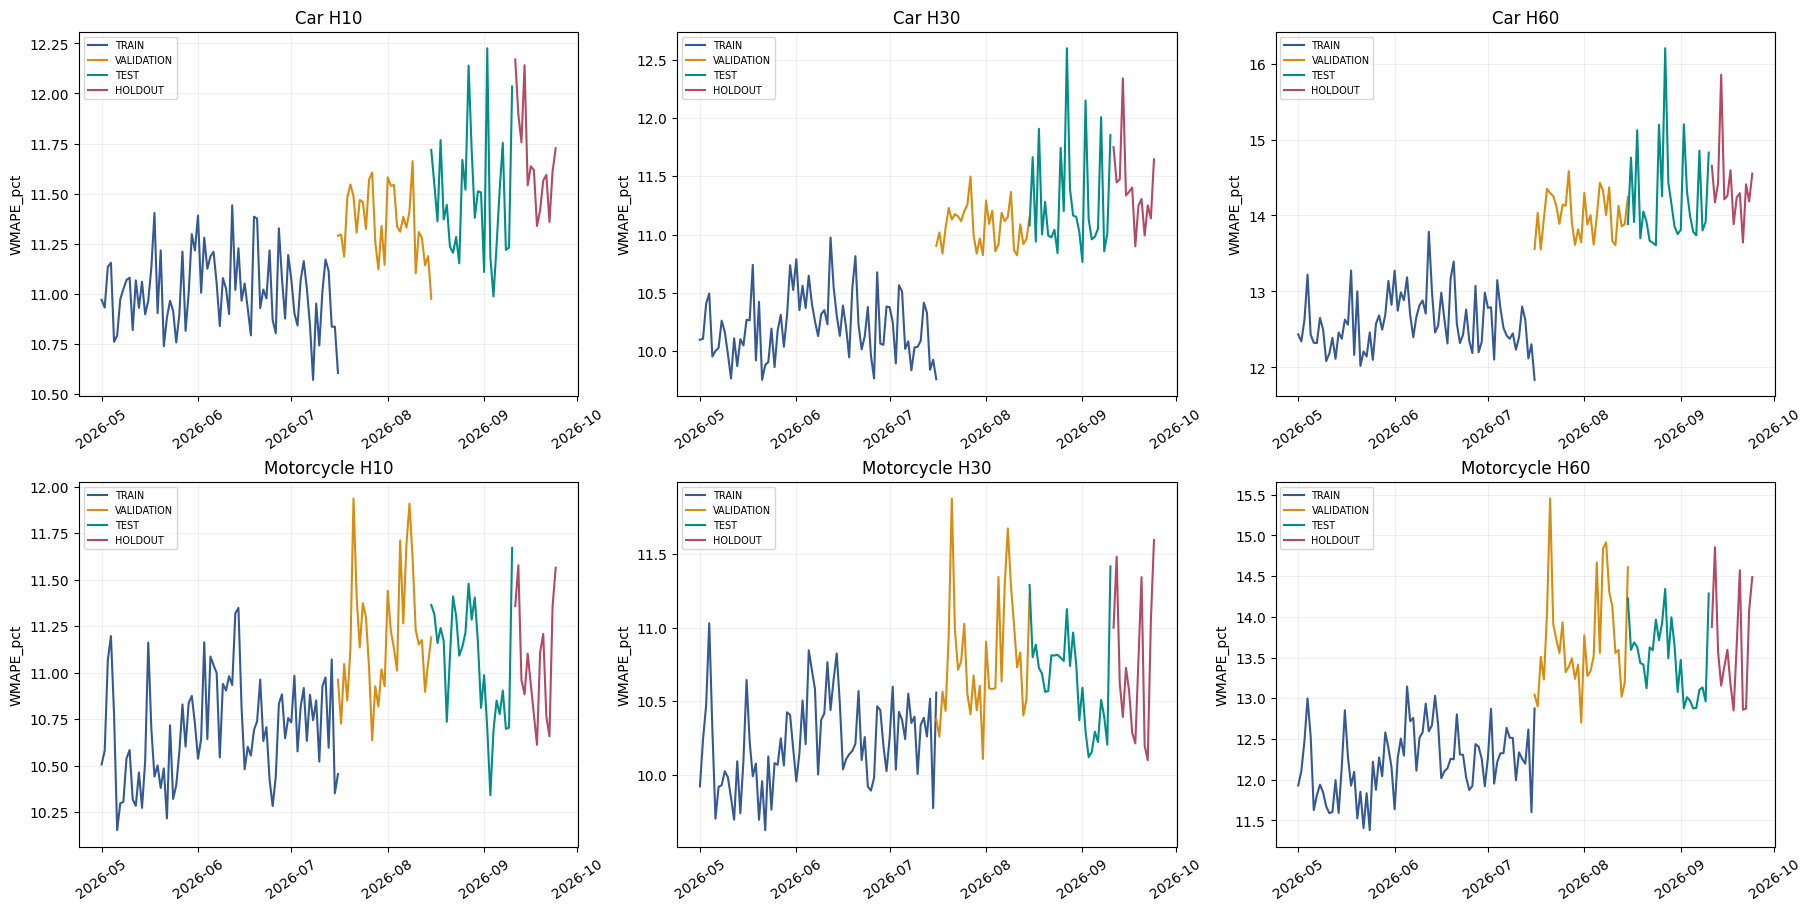

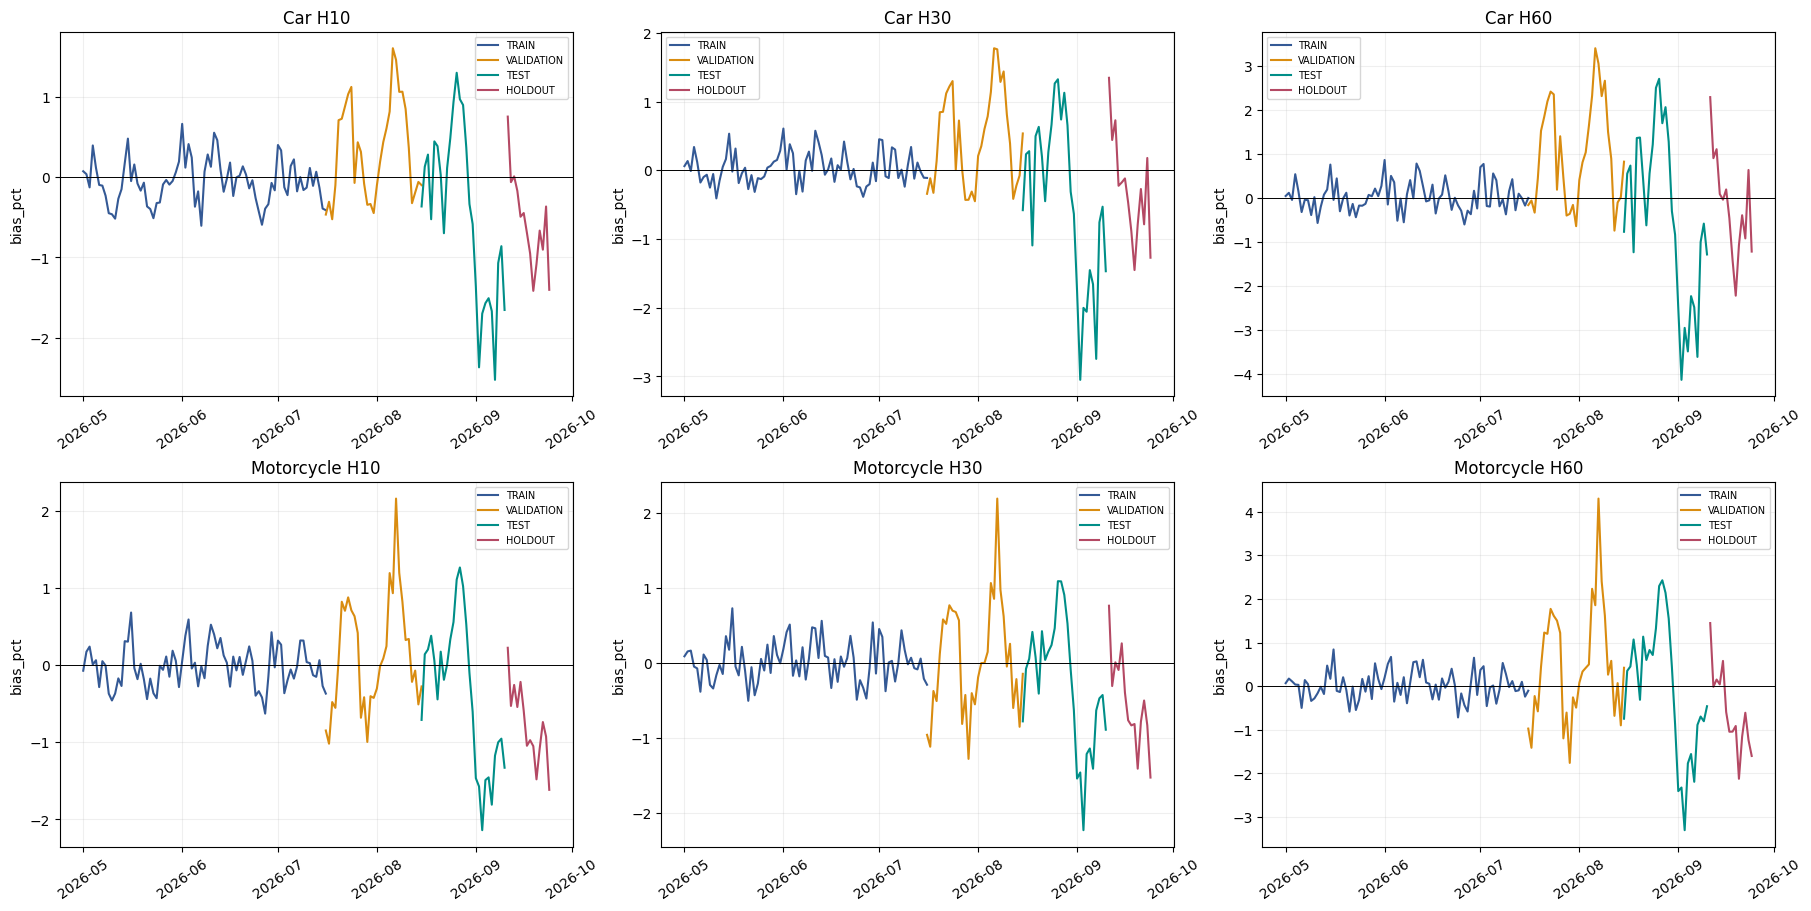

In [25]:
# Actual và prediction theo thứ/giờ, đủ 6 model × 4 split của candidate cuối.
for mode in DA_MODES:
    for horizon in DA_HORIZONS:
        fig,axes=plt.subplots(2,4,figsize=(20,8),constrained_layout=True)
        for c,split in enumerate(DA_SPLITS):
            for r,grain in enumerate(['hour','weekday']):
                z=DA_GROUPS.query('model_role == "TRAIN_ONLY" and mode == @mode and horizon == @horizon and split == @split and grain == @grain').sort_values(grain)
                ax=axes[r,c]
                ax.plot(z[grain],z.actual_mean,label='Actual',color='#274c77')
                ax.plot(z[grain],z.prediction_mean,label='Prediction',color='#c76b26',ls='--')
                ax.set(title=f'{split} — {grain}',ylabel=f'Demand H{horizon} / dòng');ax.legend(fontsize=8);ax.grid(alpha=.2)
                if grain=='weekday':ax.set_xticks(range(7),DA_WEEKDAYS,rotation=40)
                else:ax.set_xticks(range(0,24,3))
        fig.suptitle(f'{mode} H{horizon} — mức trung bình, không cộng nhãn H30/H60 chồng lấn')
        da_figure(f'actual_prediction_profile_{mode}_h{horizon}',fig)
        fig,axes=plt.subplots(1,2,figsize=(16,5),constrained_layout=True)
        for ax,kind,labels in zip(axes,['absolute','percentage'],[DA_ABS_LABELS,DA_APE_LABELS]):
            z=DA_ERROR_BINS.query('mode == @mode and horizon == @horizon and model_role == "TRAIN_ONLY" and scope == "all_rows" and error_type == @kind')
            matrix=z.pivot(index='split',columns='bin',values='rows_pct').reindex(index=DA_SPLITS,columns=labels)
            im=ax.imshow(matrix,aspect='auto',vmin=0,vmax=100,cmap='YlGnBu')
            ax.set_yticks(range(4),DA_SPLITS);ax.set_xticks(range(len(labels)),labels,rotation=45,ha='right')
            for y in range(4):
                for x in range(len(labels)):
                    val=matrix.iloc[y,x]
                    if np.isfinite(val):ax.text(x,y,f'{val:.1f}',ha='center',va='center',fontsize=8,color='white' if val>55 else 'black')
            ax.set_title('Sai số tuyệt đối — tất cả dòng' if kind=='absolute' else 'Sai số % — chỉ actual > 0')
            fig.colorbar(im,ax=ax,label='% dòng đủ điều kiện trong từng tập')
        fig.suptitle(f'{mode} H{horizon} — bin phải đóng; actual=0 nằm ở zero_actual.csv')
        da_figure(f'error_bins_{mode}_h{horizon}',fig)
# Nhóm hex-giờ sai nhiều: không lẫn với raw EDA và không dùng để fit hiệu chỉnh.
_bad=DA_GROUPS.query('grain == "hex_hour" and model_role == "TRAIN_ONLY" and split in ["TEST","HOLDOUT"] and low_support == False').copy()
_bad=_bad.sort_values(['mode','horizon','split','WMAPE_pct'],ascending=[True,True,True,False]).groupby(['mode','horizon','split'],observed=True).head(20)
da_table('top20_hex_hour_errors',_bad)
display(DA_ZERO_ACTUAL.query('model_role == "TRAIN_ONLY"').round(3))
display(DA_ERROR_BINS.query('model_role == "TRAIN_ONLY" and scope == "actual_gt30" and error_type == "percentage"')
        [['mode','horizon','split','bin','rows','rows_pct','error_share_all_pct','WMAPE_contribution_all_pp']].round(3))
# Bản đồ lỗi thứ × giờ: cùng scale trong một case, không lẫn WMAPE với bias.
for mode in DA_MODES:
    for horizon in DA_HORIZONS:
        subset=DA_GROUPS.query('mode == @mode and horizon == @horizon and model_role == "TRAIN_ONLY" and grain == "weekday_hour"')
        fig,axes=plt.subplots(2,4,figsize=(20,8),constrained_layout=True)
        for r,metric in enumerate(['WMAPE_pct','bias_pct']):
            vmax=max(float(subset[metric].abs().max()),1.)
            for c,split in enumerate(DA_SPLITS):
                matrix=subset.query('split == @split').pivot(index='weekday',columns='hour',values=metric).reindex(index=range(7),columns=range(24))
                im=axes[r,c].imshow(matrix,aspect='auto',vmin=-vmax if metric=='bias_pct' else 0,
                                    vmax=vmax,cmap='RdBu_r' if metric=='bias_pct' else 'YlOrRd')
                axes[r,c].set(title=f'{split} {metric}',xlabel='Giờ')
                axes[r,c].set_yticks(range(7),DA_WEEKDAYS);axes[r,c].set_xticks(range(0,24,3))
            fig.colorbar(im,ax=list(axes[r]),label='%')
        fig.suptitle(f'{mode} H{horizon} — xem cột low_support trong CSV trước khi kết luận')
        da_figure(f'error_weekday_hour_{mode}_h{horizon}',fig)
for metric in ['WMAPE_pct','bias_pct']:
    fig,axes=plt.subplots(2,3,figsize=(18,9),constrained_layout=True)
    for r,mode in enumerate(DA_MODES):
        for c,horizon in enumerate(DA_HORIZONS):
            ax=axes[r,c]
            for split in DA_SPLITS:
                z=DA_GROUPS.query('mode == @mode and horizon == @horizon and model_role == "TRAIN_ONLY" and split == @split and grain == "daily"').sort_values('date')
                ax.plot(z.date,z[metric],color=_da_colors[split],label=split)
            ax.set(title=f'{mode} H{horizon}',ylabel=metric);ax.tick_params(axis='x',rotation=35);ax.grid(alpha=.2);ax.legend(fontsize=7)
            if metric=='bias_pct':ax.axhline(0,color='black',lw=.7)
    da_figure('daily_'+metric,fig)


In [26]:
# Baseline theo lịch sử.
# So sánh model và baseline trên cùng các dòng hợp lệ.
import warnings

DA_BASELINE_ROWS = []

for key in CASES:
    mode, horizon = key
    info = CASE_DATA[key]
    frame = info["frame"]

    mapping = (
        {
            "last_30m": "lag_30m",
            "same_time_1d": "lag_1d",
            "same_time_7d": "lag_7d",
        }
        if horizon == 10 else
        {
            "recent_window": f"naive_recent_h{horizon}",
            "same_time_1d": f"naive_1d_h{horizon}",
            "same_time_7d": f"naive_7d_h{horizon}",
        }
    )

    missing = [column for column in mapping.values() if column not in frame.columns]
    if missing:
        raise KeyError(f"{key}: thiếu cột baseline {missing}")

    for split, ix in da_indices(frame, horizon).items():
        y = actual_for(key, ix)

        # Chỉ ẩn đúng cảnh báo tên feature; vẫn giữ các cảnh báo khác.
        with warnings.catch_warnings():
            warnings.filterwarnings(
                "ignore",
                message=r"X does not have valid feature names.*",
                category=UserWarning,
            )
            model_p = da_predict(
                MODELS[key],
                mode,
                horizon,
                frame,
                info["features"],
                ix,
                FEATURE_POLICY[key],
            )

        for name, column in mapping.items():
            pred = np.rint(
                np.clip(frame.iloc[ix][column].to_numpy(dtype=float), 0, None)
            )

            good = (
                np.isfinite(y)
                & np.isfinite(pred)
                & np.isfinite(model_p)
            )

            if not good.any():
                print(f"Bỏ qua {mode} H{horizon} {split} {name}: không có dòng hợp lệ.")
                continue

            baseline_metrics = da_metrics(y[good], pred[good])
            model_metrics = da_metrics(y[good], model_p[good])

            DA_BASELINE_ROWS.append(
                {
                    "mode": mode,
                    "horizon": horizon,
                    "split": split,
                    "baseline": name,
                    "eligible_rows": len(ix),
                    "coverage_pct": 100 * good.mean(),
                    "model_WMAPE_same_rows_pct": model_metrics["WMAPE_pct"],
                    # Dương = model có WMAPE thấp hơn baseline.
                    "model_improvement_pp": (
                        baseline_metrics["WMAPE_pct"]
                        - model_metrics["WMAPE_pct"]
                    ),
                    **baseline_metrics,
                }
            )

        print(f"Đã xong baseline: {mode} H{horizon} — {split}", flush=True)

DA_BASELINES = da_table(
    "baseline_comparison",
    pd.DataFrame(DA_BASELINE_ROWS),
)

display(DA_BASELINES.round(3))
print("Hoàn tất baseline. Chạy tiếp Audit 09 để xuất ZIP kết quả.")

Đã xong baseline: Car H10 — TRAIN
Đã xong baseline: Car H10 — VALIDATION
Đã xong baseline: Car H10 — TEST
Đã xong baseline: Car H10 — HOLDOUT
Đã xong baseline: Car H30 — TRAIN
Đã xong baseline: Car H30 — VALIDATION
Đã xong baseline: Car H30 — TEST
Đã xong baseline: Car H30 — HOLDOUT
Đã xong baseline: Car H60 — TRAIN
Đã xong baseline: Car H60 — VALIDATION
Đã xong baseline: Car H60 — TEST
Đã xong baseline: Car H60 — HOLDOUT
Đã xong baseline: Motorcycle H10 — TRAIN
Đã xong baseline: Motorcycle H10 — VALIDATION
Đã xong baseline: Motorcycle H10 — TEST
Đã xong baseline: Motorcycle H10 — HOLDOUT
Đã xong baseline: Motorcycle H30 — TRAIN
Đã xong baseline: Motorcycle H30 — VALIDATION
Đã xong baseline: Motorcycle H30 — TEST
Đã xong baseline: Motorcycle H30 — HOLDOUT
Đã xong baseline: Motorcycle H60 — TRAIN
Đã xong baseline: Motorcycle H60 — VALIDATION
Đã xong baseline: Motorcycle H60 — TEST
Đã xong baseline: Motorcycle H60 — HOLDOUT


,mode,horizon,split,baseline,eligible_rows,coverage_pct,model_WMAPE_same_rows_pct,model_improvement_pp,rows,actual_sum,prediction_sum,actual_mean,prediction_mean,WMAPE_pct,bias_pct,MAE,RMSE,P95_abs_error,high_demand_rows,within15_actual_gt30_pct
0,Car,10,TRAIN,last_30m,1648849,100.000,11.013,11.796,1648849,15850848.0,15845896.0,9.613,9.610,22.809,-0.031,2.193,5.389,10.0,114275,38.994
1,Car,10,TRAIN,same_time_1d,1648849,97.751,11.011,54.636,1611766,15554179.0,15525193.0,9.650,9.632,65.647,-0.186,6.335,14.948,29.0,112433,11.506
2,Car,10,TRAIN,same_time_7d,1648849,84.610,11.011,52.520,1395091,13830956.0,13782365.0,9.914,9.879,63.531,-0.351,6.299,14.848,29.0,101817,12.020
3,Car,10,VALIDATION,last_30m,646554,100.000,11.356,11.407,646554,5945920.0,5947214.0,9.196,9.198,22.763,0.022,2.093,4.962,9.0,41430,38.981
4,Car,10,VALIDATION,same_time_1d,646554,99.128,11.356,54.779,640914,5913581.0,5954338.0,9.227,9.290,66.136,0.689,6.102,14.310,28.0,41357,11.275
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,Motorcycle,60,TEST,same_time_1d,505989,99.070,13.415,50.418,501284,57045513.0,56694105.0,113.799,113.098,63.833,-0.616,72.641,150.975,323.0,285436,13.226
68,Motorcycle,60,TEST,same_time_7d,505989,92.914,13.375,49.107,470137,54976783.0,50954879.0,116.938,108.383,62.482,-7.316,73.065,152.541,326.0,270912,12.758
69,Motorcycle,60,HOLDOUT,recent_window,261702,100.000,13.641,34.415,261702,29573773.0,29571739.0,113.006,112.998,48.055,-0.007,54.305,111.367,240.0,146473,16.781
70,Motorcycle,60,HOLDOUT,same_time_1d,261702,96.368,13.609,50.871,252198,29026902.0,28907135.0,115.096,114.621,64.480,-0.413,74.213,154.789,336.0,142078,12.960


Hoàn tất baseline. Chạy tiếp Audit 09 để xuất ZIP kết quả.


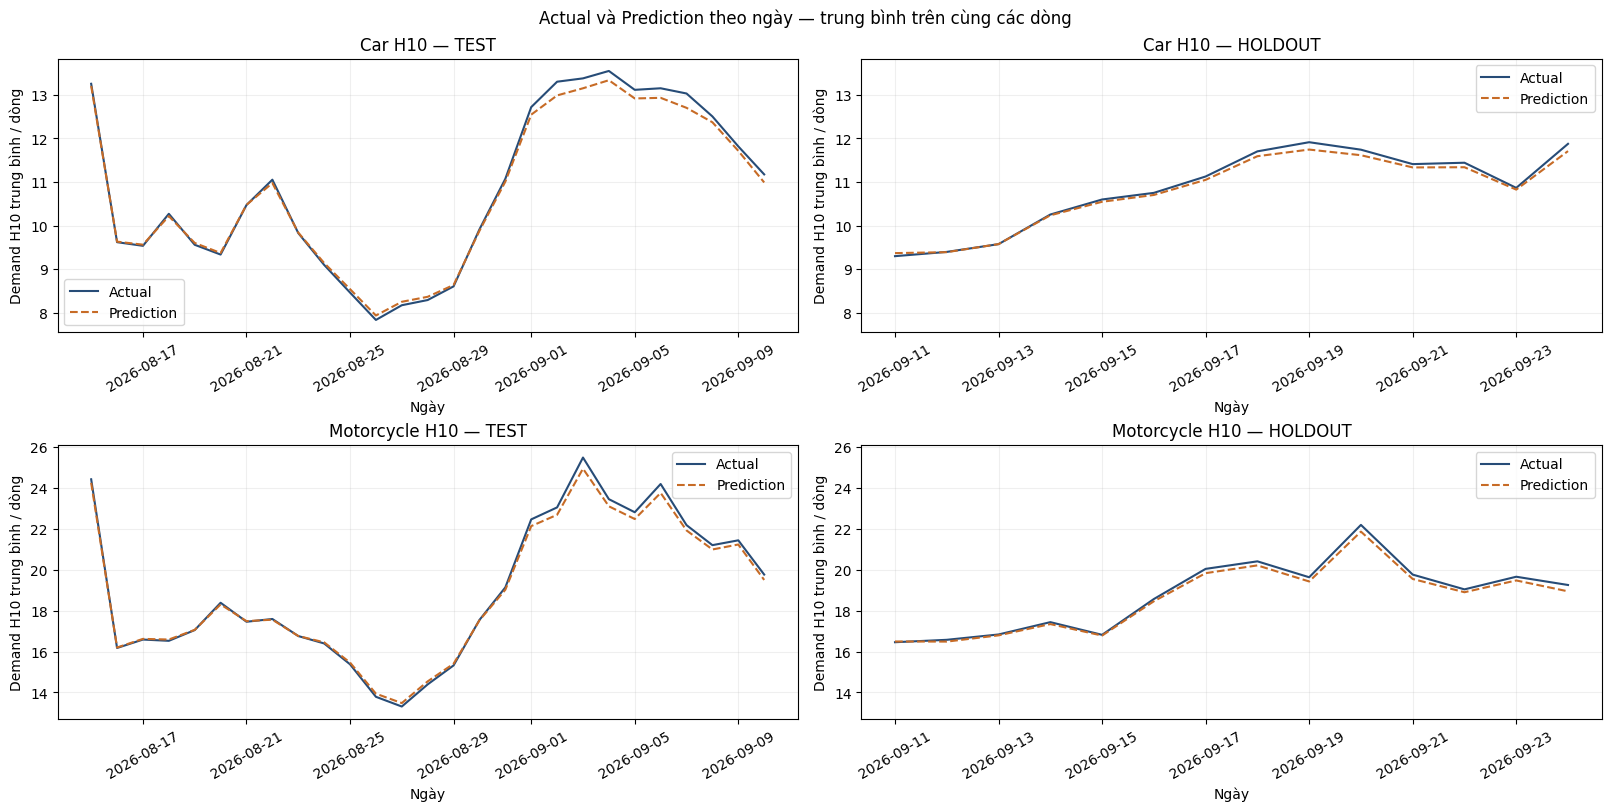

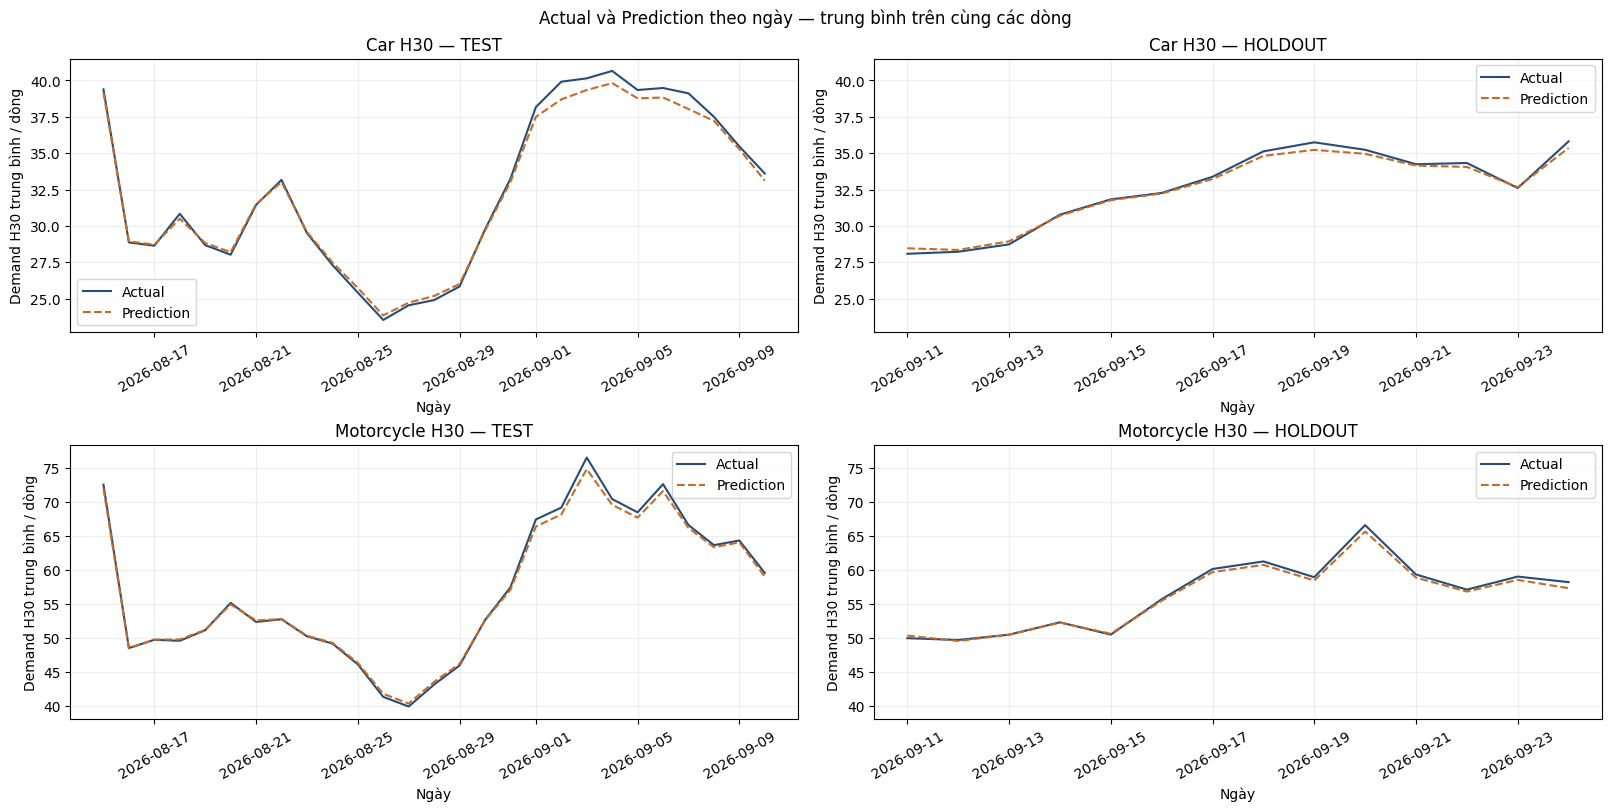

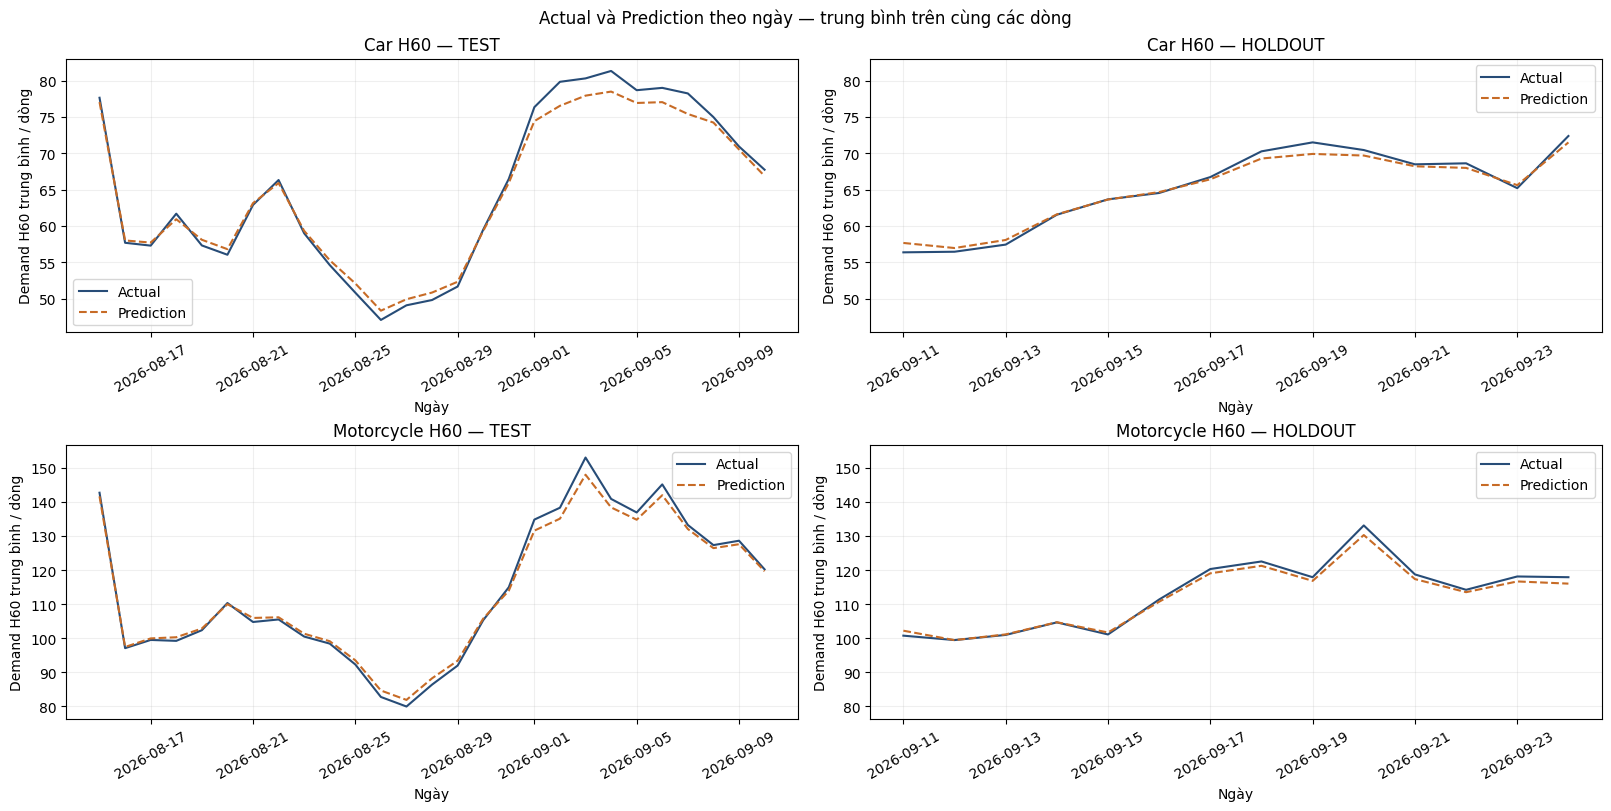

H30/H60 biểu diễn demand trung bình của target; không cộng thành tổng booking/ngày.


In [28]:
# CELL 1 — Actual/Prediction theo ngày trên TEST và HOLDOUT
if "DA_GROUPS" not in globals():
    raise RuntimeError("Chạy Audit 06 trước cell này.")

mentor_daily = DA_GROUPS.loc[
    (DA_GROUPS.model_role == "TRAIN_ONLY")
    & (DA_GROUPS.grain == "daily")
    & DA_GROUPS.split.isin(["TEST", "HOLDOUT"])
].copy()

mentor_daily["date"] = pd.to_datetime(mentor_daily["date"])
da_table("mentor_daily_actual_prediction", mentor_daily)

for h in DA_HORIZONS:
    fig, axes = plt.subplots(
        2, 2, figsize=(16, 8), constrained_layout=True
    )

    for r, mode in enumerate(DA_MODES):
        for c, split in enumerate(["TEST", "HOLDOUT"]):
            z = mentor_daily.loc[
                (mentor_daily["mode"] == mode)
                & (mentor_daily.horizon == h)
                & (mentor_daily.split == split)
            ].sort_values("date")

            if z.empty:
                raise ValueError(f"Thiếu dữ liệu {mode} H{h} {split}")

            ax = axes[r, c]
            ax.plot(
                z.date, z.actual_mean,
                label="Actual", color="#274c77"
            )
            ax.plot(
                z.date, z.prediction_mean,
                label="Prediction", color="#c76b26", linestyle="--"
            )
            ax.set(
                title=f"{mode} H{h} — {split}",
                ylabel=f"Demand H{h} trung bình / dòng",
                xlabel="Ngày"
            )
            ax.tick_params(axis="x", rotation=30)
            ax.grid(alpha=.2)
            ax.legend()

        # Cùng thang demand cho TEST/HOLDOUT của một mode.
        lo = min(ax.get_ylim()[0] for ax in axes[r])
        hi = max(ax.get_ylim()[1] for ax in axes[r])
        for ax in axes[r]:
            ax.set_ylim(lo, hi)

    fig.suptitle(
        "Actual và Prediction theo ngày — trung bình trên cùng các dòng"
    )
    da_figure(f"mentor_daily_actual_prediction_h{h}", fig)

print(
    "H30/H60 biểu diễn demand trung bình của target; "
    "không cộng thành tổng booking/ngày."
)

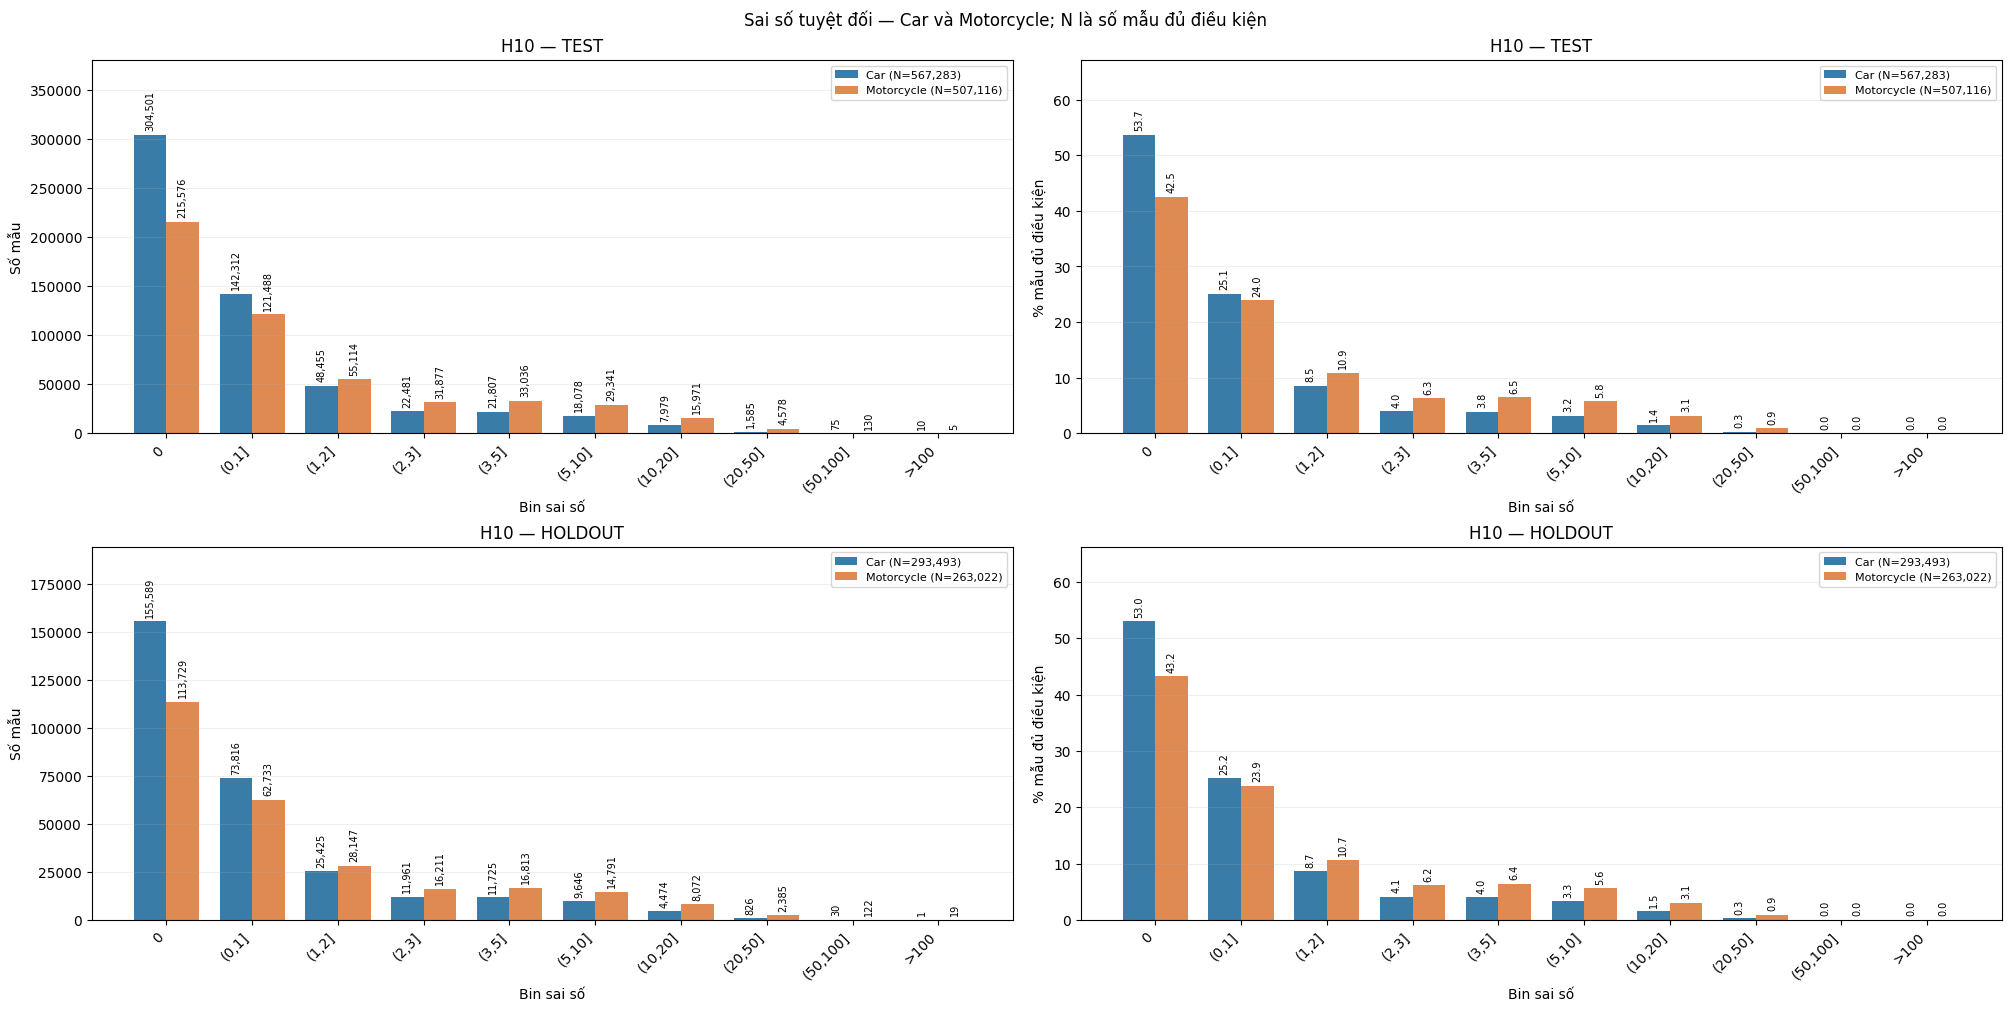

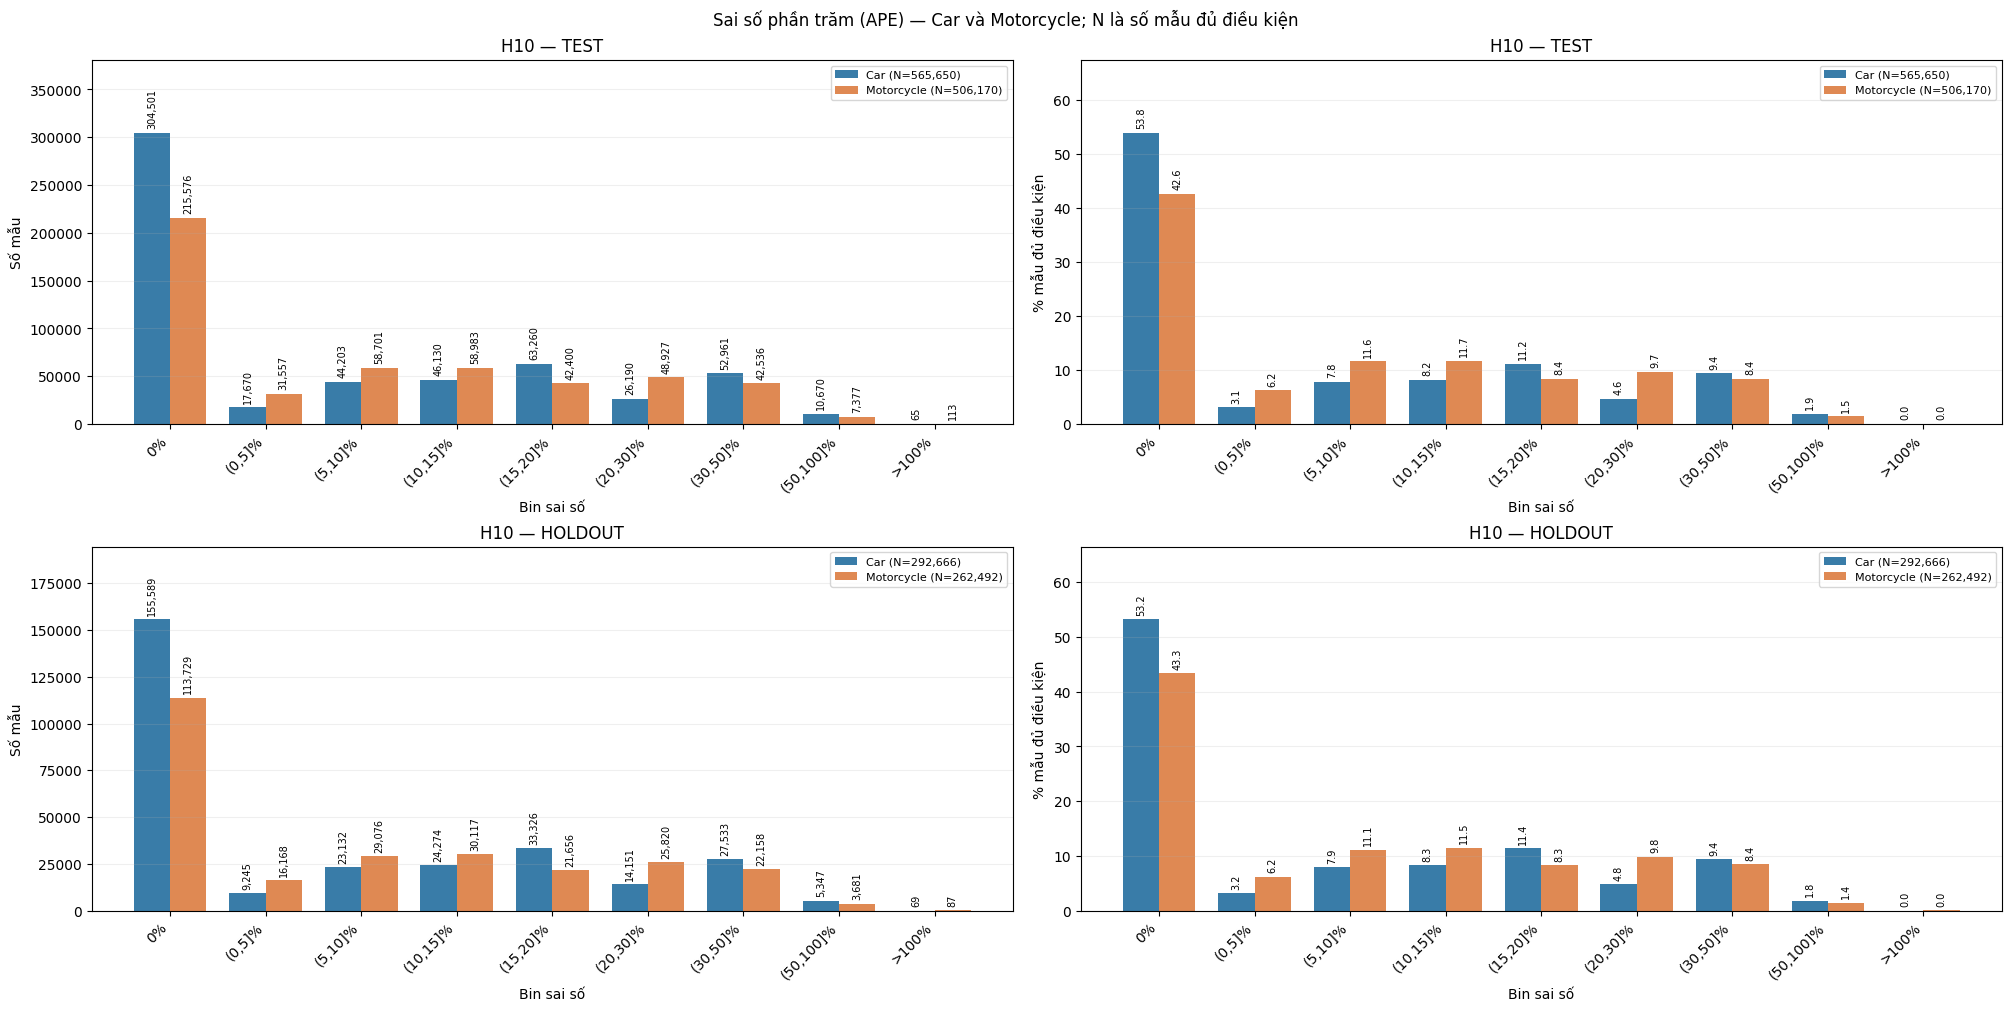

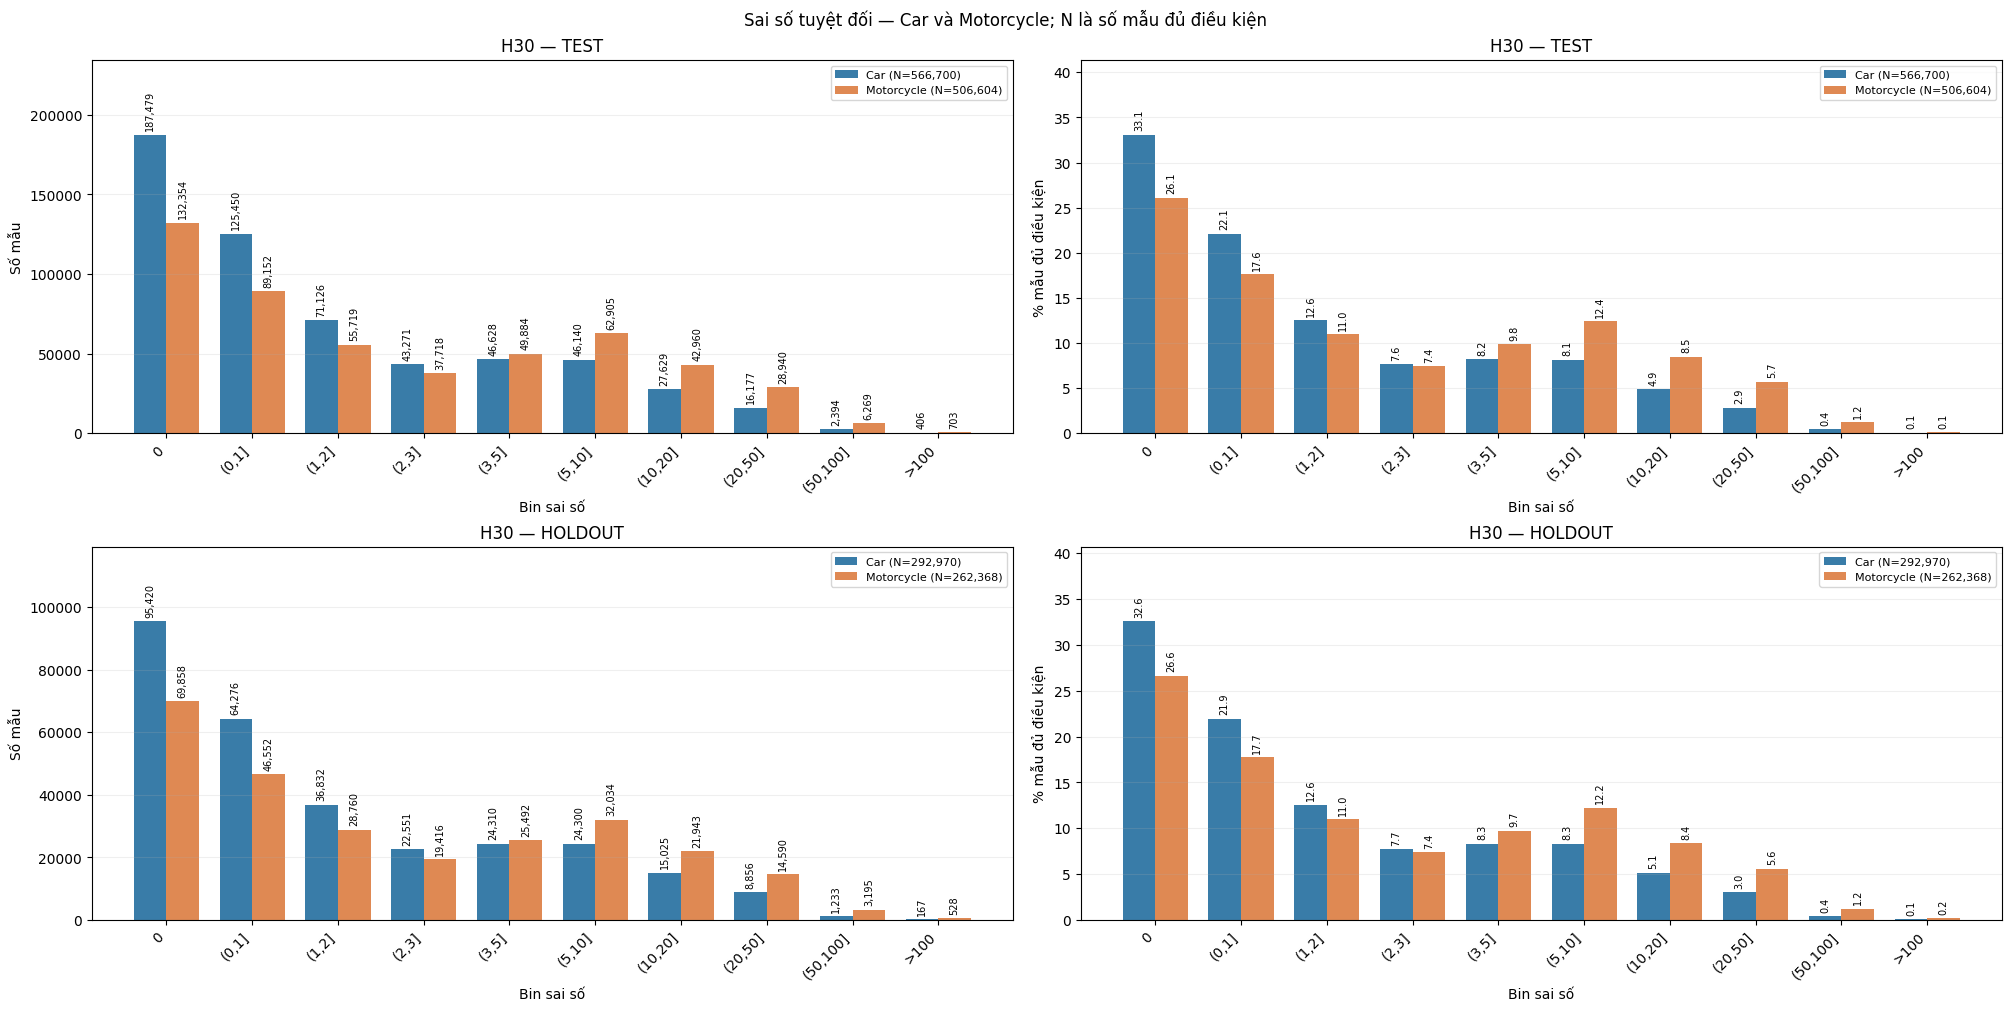

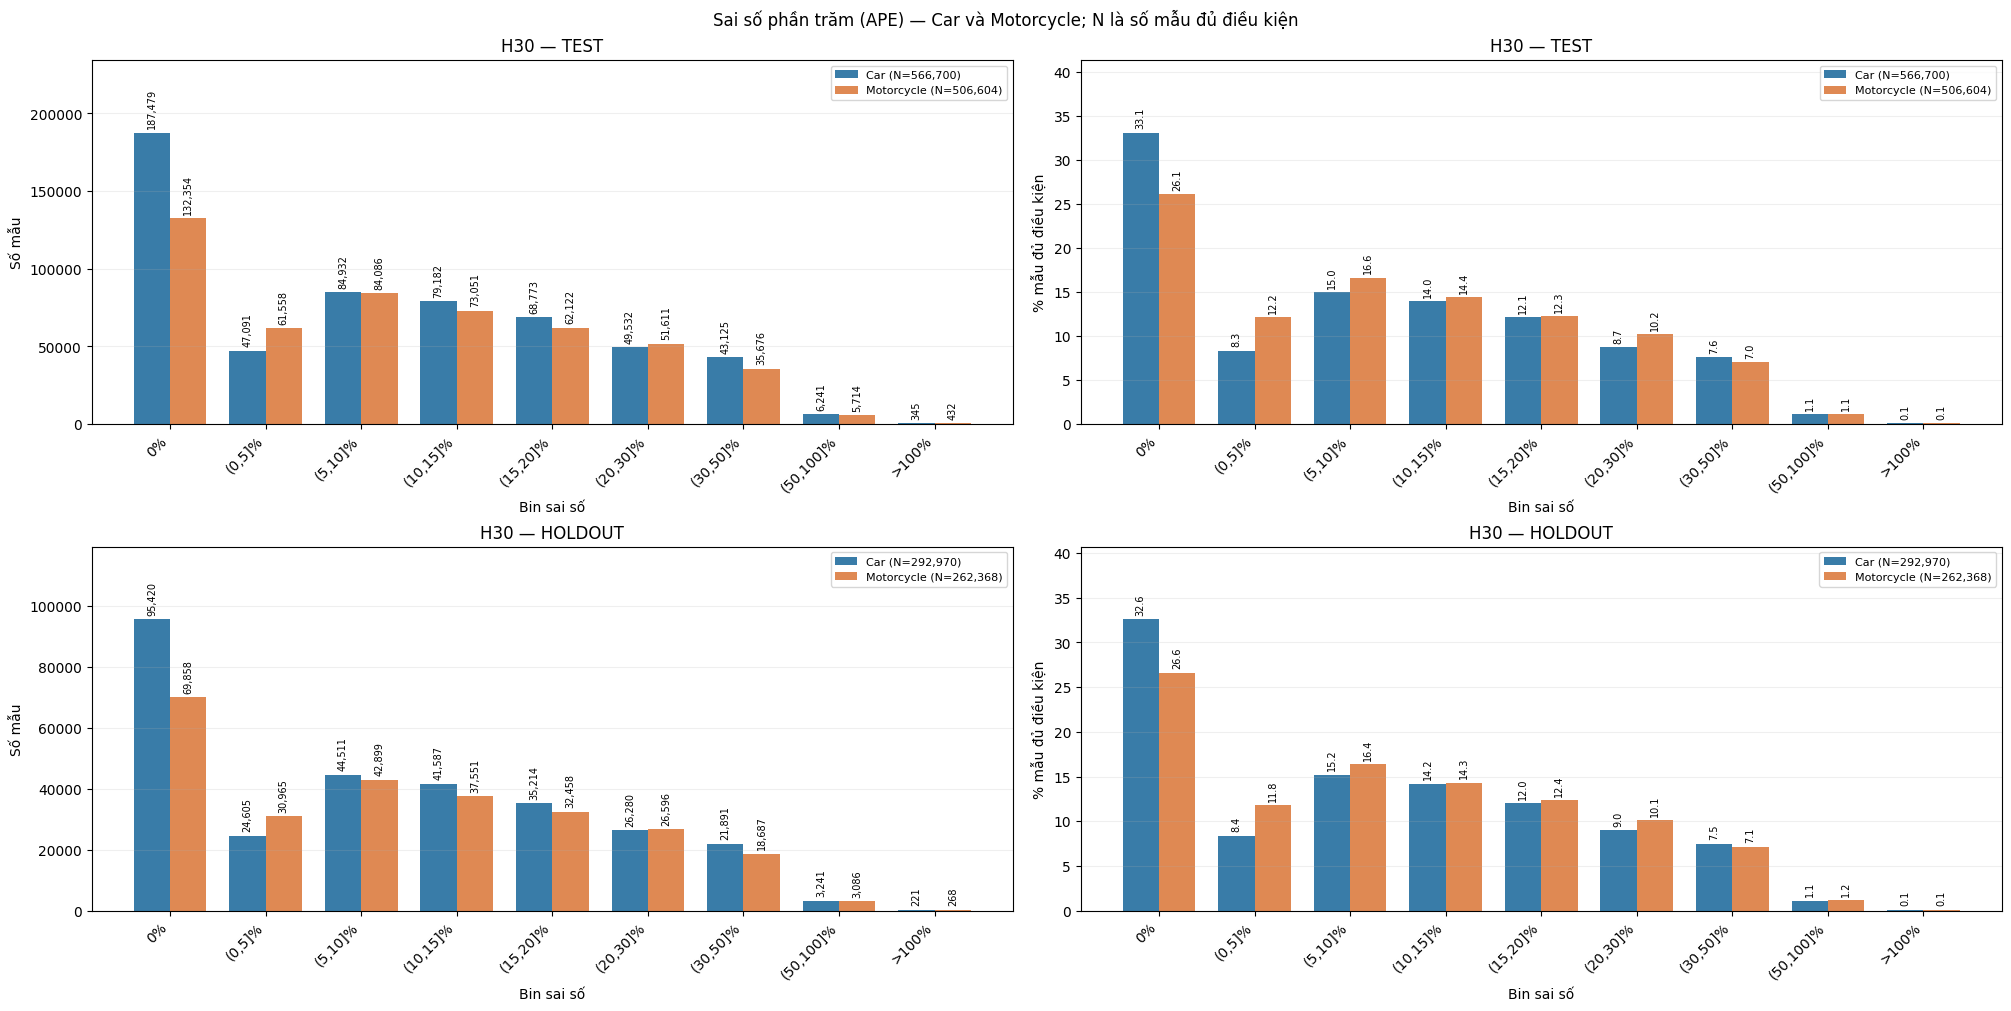

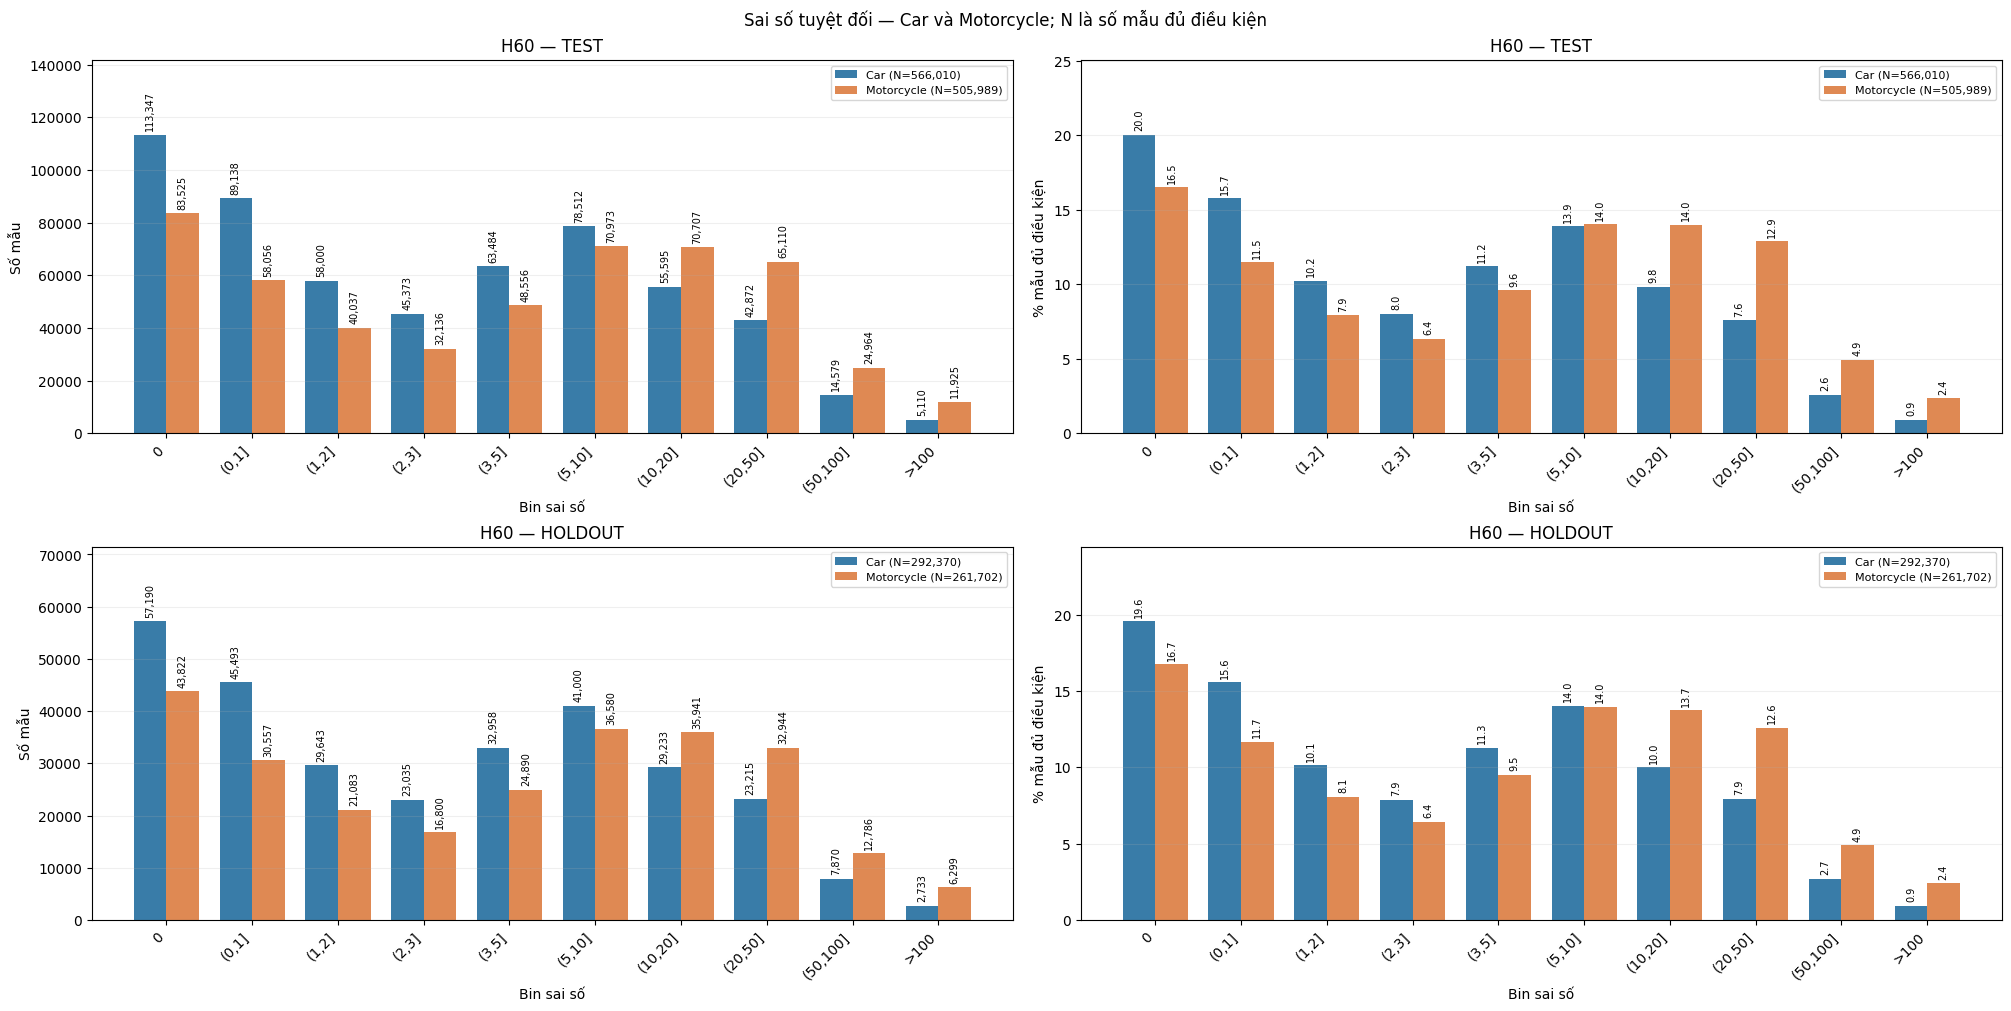

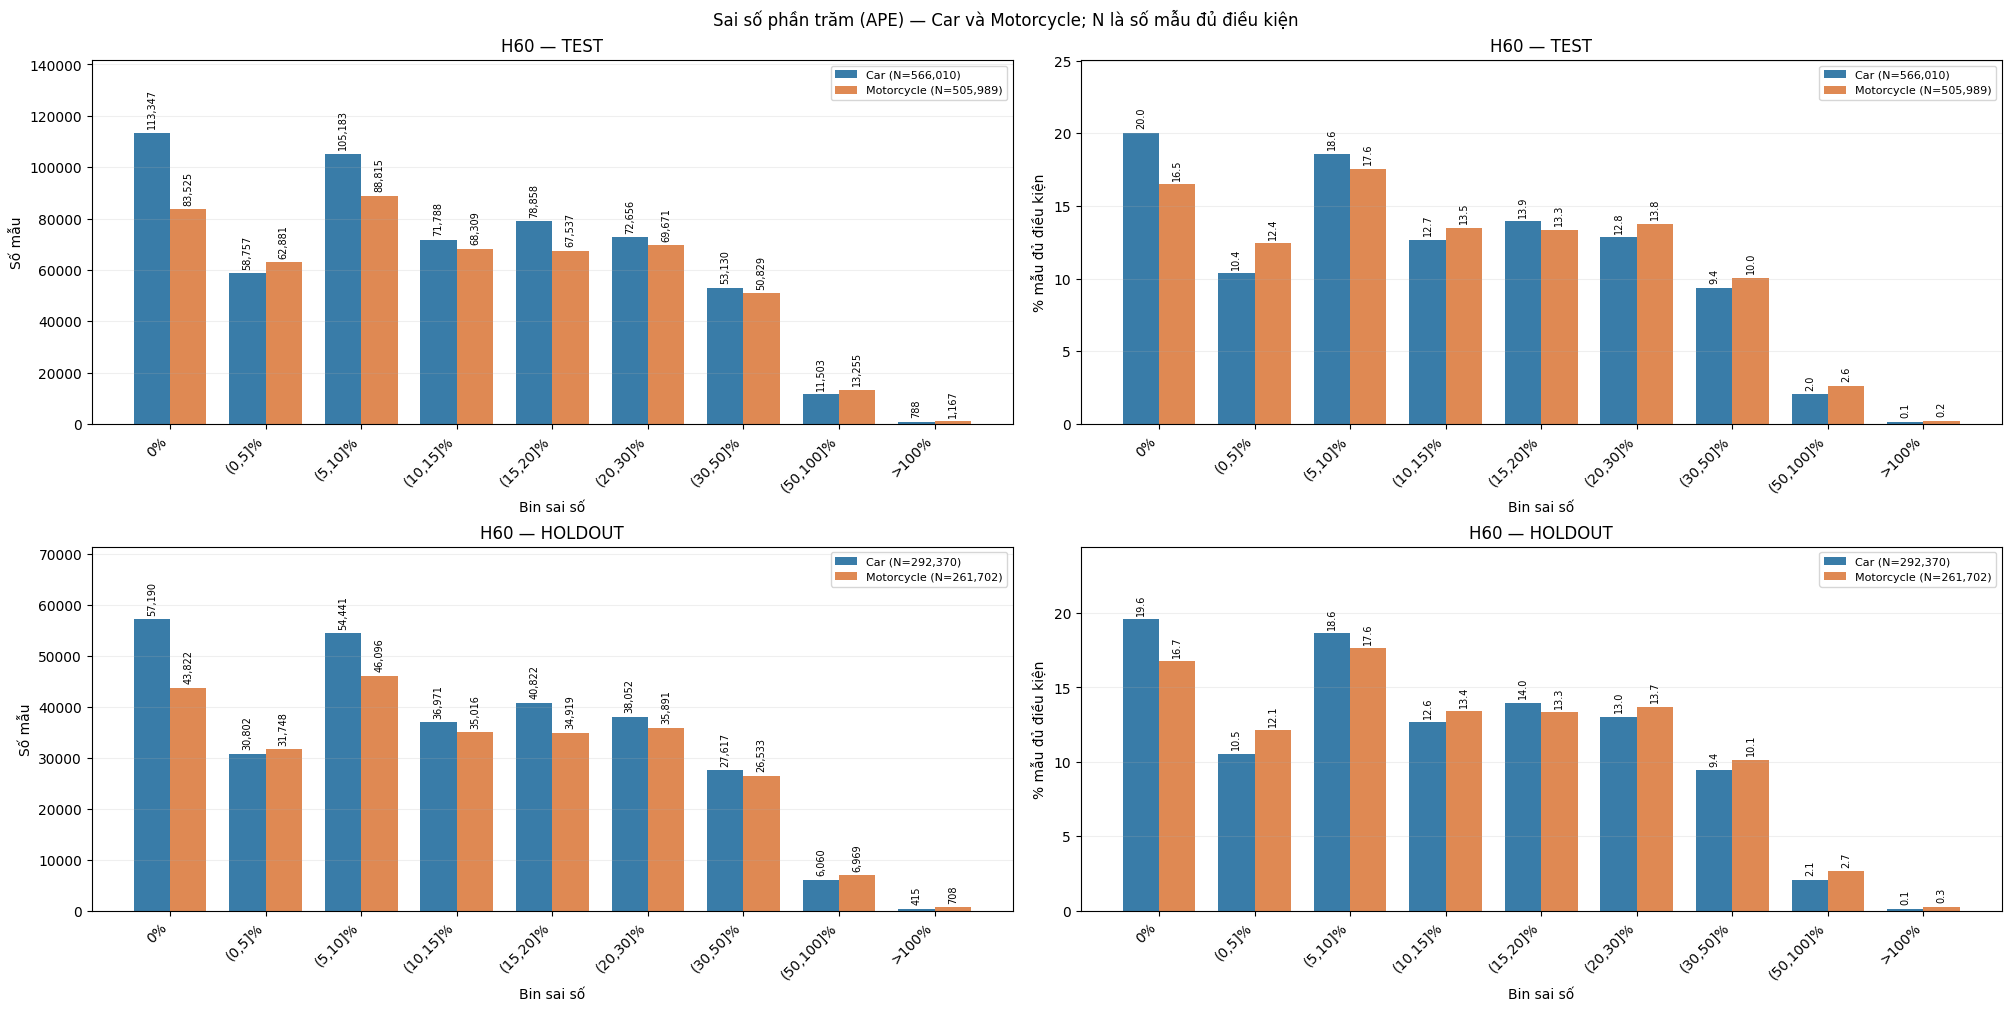

Bins APE chỉ tính actual > 0. Actual = 0 vẫn được tính trong bins tuyệt đối và WMAPE.


In [29]:
# CELL 2 — Bins sai số: Car/Motorcycle, số mẫu và tỷ lệ %
if "DA_ERROR_BINS" not in globals():
    raise RuntimeError("Chạy Audit 06 trước cell này.")

mentor_bins = DA_ERROR_BINS.loc[
    (DA_ERROR_BINS.model_role == "TRAIN_ONLY")
    & (DA_ERROR_BINS.scope == "all_rows")
    & DA_ERROR_BINS.split.isin(["TEST", "HOLDOUT"])
].copy()

da_table("mentor_error_bin_counts_pct", mentor_bins)

for h in DA_HORIZONS:
    for kind, labels in [
        ("absolute", DA_ABS_LABELS),
        ("percentage", DA_APE_LABELS)
    ]:
        fig, axes = plt.subplots(
            2, 2, figsize=(20, 10), constrained_layout=True
        )

        for r, split in enumerate(["TEST", "HOLDOUT"]):
            for c, metric in enumerate(["rows", "rows_pct"]):
                ax = axes[r, c]
                x = np.arange(len(labels))

                for j, mode in enumerate(DA_MODES):
                    z = mentor_bins.loc[
                        (mentor_bins["mode"] == mode)
                        & (mentor_bins.horizon == h)
                        & (mentor_bins.split == split)
                        & (mentor_bins.error_type == kind)
                    ].set_index("bin").reindex(labels)

                    if z["eligible_rows"].isna().any():
                        raise ValueError(
                            f"Thiếu bins {mode} H{h} {split} {kind}"
                        )

                    bars = ax.bar(
                        x + (j - .5) * .38,
                        z[metric],
                        width=.38,
                        label=f"{mode} (N={int(z.eligible_rows.iloc[0]):,})",
                        color=["#397ca8", "#df8953"][j]
                    )
                    texts = [
                        f"{v:,.0f}" if metric == "rows" else f"{v:.1f}"
                        for v in z[metric]
                    ]
                    ax.bar_label(
                        bars, labels=texts,
                        rotation=90, padding=3, fontsize=7
                    )

                ax.set_xticks(x, labels, rotation=45, ha="right")
                ax.set(
                    title=f"H{h} — {split}",
                    xlabel="Bin sai số",
                    ylabel=(
                        "Số mẫu" if metric == "rows"
                        else "% mẫu đủ điều kiện"
                    )
                )
                ax.margins(y=.25)
                ax.legend(fontsize=8)
                ax.grid(axis="y", alpha=.2)

        title = (
            "Sai số tuyệt đối" if kind == "absolute"
            else "Sai số phần trăm (APE)"
        )
        fig.suptitle(
            title + " — Car và Motorcycle; N là số mẫu đủ điều kiện"
        )
        da_figure(f"mentor_error_bins_{kind}_h{h}", fig)

print(
    "Bins APE chỉ tính actual > 0. Actual = 0 vẫn được tính "
    "trong bins tuyệt đối và WMAPE."
)

In [30]:
# CELL 3 — Chênh lệch trực tiếp HOLDOUT so với TEST
if "DA_METRICS" not in globals():
    raise RuntimeError("Chạy Audit 06 trước cell này.")

keys = ["mode", "horizon"]
metrics = [
    "rows", "days", "WMAPE_pct", "MAE", "RMSE", "bias_pct",
    "P95_abs_error", "actual_mean", "prediction_mean"
]

m = DA_METRICS.loc[
    DA_METRICS.model_role == "TRAIN_ONLY"
].copy()

parts = []
for split in ["TEST", "HOLDOUT"]:
    part = m.loc[m.split == split, keys + metrics].copy()
    part = part.rename(
        columns={v: f"{split}_{v}" for v in metrics}
    )
    parts.append(part)

mentor_compare = parts[0].merge(
    parts[1],
    on=keys,
    how="outer",
    validate="one_to_one",
    indicator=True
)

if (
    not mentor_compare["_merge"].eq("both").all()
    or len(mentor_compare) != 6
):
    raise ValueError("Cần đủ TEST và HOLDOUT cho cả 6 model.")

mentor_compare = mentor_compare.drop(columns="_merge")

for metric, name in [
    ("WMAPE_pct", "delta_WMAPE_pp"),
    ("MAE", "delta_MAE"),
    ("RMSE", "delta_RMSE"),
    ("bias_pct", "delta_bias_pp"),
    ("P95_abs_error", "delta_P95_abs_error")
]:
    mentor_compare[name] = (
        mentor_compare[f"HOLDOUT_{metric}"]
        - mentor_compare[f"TEST_{metric}"]
    )

mentor_compare["delta_abs_bias_pp"] = (
    mentor_compare.HOLDOUT_bias_pct.abs()
    - mentor_compare.TEST_bias_pct.abs()
)

mentor_compare = (
    mentor_compare.sort_values(keys).reset_index(drop=True)
)
da_table("mentor_test_holdout_comparison", mentor_compare)

display(
    mentor_compare[keys + [
        "TEST_rows", "HOLDOUT_rows",
        "TEST_WMAPE_pct", "HOLDOUT_WMAPE_pct", "delta_WMAPE_pp",
        "TEST_MAE", "HOLDOUT_MAE", "delta_MAE",
        "TEST_bias_pct", "HOLDOUT_bias_pct", "delta_abs_bias_pp"
    ]].round(4)
)

print(
    "Delta = HOLDOUT − TEST. "
    "Delta WMAPE/MAE/RMSE > 0: sai số tăng."
)
print(
    "Delta |bias| > 0: độ lệch tổng lớn hơn; "
    "bias âm là dự đoán thiếu."
)
print(
    "Chênh lệch chỉ là bằng chứng chẩn đoán; đọc cùng Audit 07 "
    "và coverage để phân biệt overfit với thay đổi dữ liệu."
)

,mode,horizon,TEST_rows,HOLDOUT_rows,TEST_WMAPE_pct,HOLDOUT_WMAPE_pct,delta_WMAPE_pp,TEST_MAE,HOLDOUT_MAE,delta_MAE,TEST_bias_pct,HOLDOUT_bias_pct,delta_abs_bias_pp
0,Car,10,567283,293493,11.4712,11.6560,0.1848,1.2378,1.2637,0.0260,-0.6377,-0.6012,-0.0365
1,Car,30,566700,292970,11.2779,11.3879,0.1100,3.6515,3.7078,0.0564,-0.6650,-0.3160,-0.3490
2,Car,60,566010,292370,14.2196,14.3735,0.1539,9.2096,9.3709,0.1612,-0.7456,-0.2549,-0.4907
3,Motorcycle,10,507116,263022,11.0217,11.0559,0.0343,2.0791,2.0745,-0.0045,-0.5467,-0.8092,0.2624
4,Motorcycle,30,506604,262368,10.6121,10.7377,0.1255,6.0072,6.0559,0.0487,-0.4230,-0.5595,0.1365
5,Motorcycle,60,505989,261702,13.4226,13.6406,0.2181,15.1997,15.4147,0.2150,-0.3333,-0.6504,0.3171


Delta = HOLDOUT − TEST. Delta WMAPE/MAE/RMSE > 0: sai số tăng.
Delta |bias| > 0: độ lệch tổng lớn hơn; bias âm là dự đoán thiếu.
Chênh lệch chỉ là bằng chứng chẩn đoán; đọc cùng Audit 07 và coverage để phân biệt overfit với thay đổi dữ liệu.


### Audit 09

In [31]:
# Đóng gói CSV + PNG + metadata + bản tóm tắt, không gói model nặng.
DA_METADATA=dict(holdout_status=DA_HOLDOUT_STATUS,
    splits={'validation_start':str(DA_VAL_START),'test_start':str(DA_TEST_START),
            'holdout_start':str(DA_HOLDOUT_START),'data_end_exclusive':str(DA_END)},
    raw_source=DA_RAW_SOURCE,timezone='Asia/Ho_Chi_Minh',seed=DA_SEED,
    holdout_generation=HOLDOUT_MANIFEST,
    main_metrics_scope='All eligible rows, no sampling',curve_sample_rows=DA_CURVE_SAMPLE_ROWS,
    absolute_bin_labels=DA_ABS_LABELS,percentage_bin_labels=DA_APE_LABELS,
    error_bin_interval='right-closed (a,b]; zero separate',
    percentage_error='100*abs(pred-actual)/actual on actual>0 only',
    zero_actual='Included in absolute errors and overall WMAPE; excluded from APE denominator',
    gap_alert_pp=DA_GAP_PP,gap_alert_ratio=DA_GAP_RATIO,min_group_rows=DA_MIN_GROUP_ROWS,
    min_group_days=DA_MIN_GROUP_DAYS,models=DA_MODEL_MANIFEST,
    limitations=['HOLDOUT là 14 ngày fake mới cùng cơ chế; chưa chứng minh chất lượng trên dữ liệu thực.',
                'VAL đã dùng chọn cấu hình nên không là đánh giá độc lập cuối cùng.',
                'Model chính chỉ fit TRAIN; audit không fit thêm.',
                'H30/H60 dùng target chồng lấn; tổng nhãn không phải tổng booking duy nhất.',
                'Coverage lưới tiềm năng không đồng nghĩa missing nếu hex không hoạt động.',
                'Giờ đầy đủ cần 6 bucket; ngày/nhóm ít hỗ trợ được ghi rõ.',
                'Bootstrap theo ngày chỉ là khoảng mô tả, không bảo đảm độc lập theo thời gian.',
                'Các ngưỡng gap chỉ cảnh báo, không là kết luận production readiness.'])
(DA_OUT/'metadata.json').write_text(json.dumps(DA_METADATA,ensure_ascii=False,indent=2,default=str),encoding='utf-8')
_lines=['# Kết quả demand trend và kiểm tra overfit',
        '\nHOLDOUT: **14 ngày fake mới sau dữ liệu cũ**, không dùng huấn luyện hoặc chọn cấu hình. Phạm vi kết luận là dữ liệu giả lập.',
        '\nBảng original_full_test_reports chỉ giữ TEST lịch sử; các bảng audit chấm HOLDOUT mới riêng, loại nhãn vượt ranh giới.', '\n## Phạm vi',f'- Mốc split: {DA_METADATA["splits"]}',
        f'- Nguồn EDA: {DA_RAW_SOURCE}. Metric chính chấm toàn bộ dòng đủ điều kiện.',
        '- TRAIN_ONLY là chính MODELS của notebook hieuchinh.',
        '\n## Kết quả candidate cuối']
for row in DA_METRICS.query('model_role == "TRAIN_ONLY"').itertuples():
    _lines.append(f'- {row.mode} H{row.horizon} {row.split}: {row.rows:,} dòng; WMAPE {row.WMAPE_pct:.3f}%; bias {row.bias_pct:+.3f}%; MAE {row.MAE:.3f}.')
_lines+=['\n## Dấu hiệu cần kiểm tra']
for row in DA_GAPS.query('model_role == "TRAIN_ONLY"').itertuples():
    _lines.append(f'- {row.mode} H{row.horizon} TRAIN → {row.split}: gap {row.gap_pp:+.3f} điểm %; {row.status}.')
_lines+=['\n## Cách đọc bins',
 '- `error_bins.csv`: tách absolute/percentage, mode, horizon, model_role, split và scope.',
 '- `rows_pct`: tỷ lệ trên dòng đủ điều kiện trong scope; lỗi % luôn loại actual=0 khỏi mẫu số.',
 '- `error_share_all_pct`: đóng góp vào tổng sai số tuyệt đối toàn tập, không phải tỷ lệ số dòng.',
 '- `WMAPE_contribution_all_pp`: phần đóng góp vào WMAPE toàn tập. Scope con không cộng chồng lên all_rows.',
 '- `zero_actual.csv`: dự đoán dương khi actual=0, tỷ lệ và đóng góp lỗi.',
 '- `actual_1_to_3` và `actual_gt30` giúp tránh kết luận từ lỗi % lớn trên demand nhỏ.',
 '\n## Giới hạn']+['- '+x for x in DA_METADATA['limitations']]
(DA_OUT/'README_KET_QUA.md').write_text('\n'.join(_lines),encoding='utf-8')
# Chỉ gói các file của lần chạy hiện tại, tránh lẫn biểu đồ cũ khi chạy lại.
import zipfile
_da_zip=DA_OUT.parent/'demand_trend_overfit_results.zip'
_files=[DA_OUT/(name+'.csv') for name in DA_TABLES]+[DA_OUT/name for name in sorted(set(DA_FIGURES))]+[DA_OUT/'metadata.json',DA_OUT/'README_KET_QUA.md']
with zipfile.ZipFile(_da_zip,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for p in _files:z.write(p,arcname=p.name)
    for p in REPORT_DIR.rglob('*'):
        if p.is_file(): z.write(p,arcname='original_full_test_reports/'+str(p.relative_to(REPORT_DIR)))
print('HOÀN TẤT:',_da_zip)
print('Gửi lại file ZIP này và notebook có output đã Save Version để viết thêm vào báo cáo.')
try:
    from IPython.display import FileLink
    display(FileLink(str(_da_zip)))
except Exception:
    pass


HOÀN TẤT: /kaggle/working/demand_trend_overfit_results.zip
Gửi lại file ZIP này và notebook có output đã Save Version để viết thêm vào báo cáo.


/kaggle/working/demand_trend_overfit_results.zip